##1.LÀM SẠCH DỮ LIỆU

###1.1.Cài đặt thư viện


In [ ]:
install.packages("tidyverse")
install.packages("pacman")
install.packages("skimr")
install.packages("janitor")
install.packages("openxlsx")
install.packages("rio")
install.packages("data.table")
install.packages("here")
install.packages("dplyr")
install.packages("RcppRoll")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘snakecase’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘R.oo’, ‘R.methodsS3’, ‘writexl’, ‘R.utils’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



###1.2.Gọi thư viện

In [ ]:
library(pacman)
pacman::p_load(
  rio,
  data.table,
  tidyverse,
  here,
  dplyr
)

###1.3.Quy trình làm sạch

#### Bước1: Nhập dữ liệu

In [ ]:
sensor_raw <- read.csv("https://raw.githubusercontent.com/txtruong27/-n-1/refs/heads/main/sensor_raw.csv")
sensor_raw
names(sensor_raw)
head(sensor_raw)

Target.Class.,GyroX,GyroY,GyroZ,AccX,AccY,AccZ
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,-0.92366412,3.6946565,0.82442748,0.16259766,-0.086669922,-0.9694824
1,-0.90839695,4.5343511,0.83206107,0.17578125,-0.100585938,-1.0131836
1,0.78625954,3.9694656,0.58778626,0.32275391,-0.140380859,-0.9116211
1,0.33587786,4.5648855,-0.25190840,0.48022461,-0.226806641,-0.9367676
1,3.35114504,2.6946565,-0.10687023,0.42602539,-0.253906250,-0.9501953
1,-1.50381679,3.1832061,-1.65648855,0.38378906,-0.141601562,-0.9196777
1,1.35877863,8.7251908,-0.94656489,0.40478516,-0.257324219,-0.8625488
1,-1.08396947,4.1068702,-0.62595420,0.34692383,-0.106201172,-0.9699707
1,0.05343511,5.0839695,-2.22137405,0.27661133,-0.257568359,-1.0083008


[1] "Target.Class." "GyroX"         "GyroY"         "GyroZ"        
[5] "AccX"          "AccY"          "AccZ"

,Target.Class.,GyroX,GyroY,GyroZ,AccX,AccY,AccZ
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-0.9236641,3.694656,0.8244275,0.1625977,-0.08666992,-0.9694824
2,1,-0.9083969,4.534351,0.8320611,0.1757812,-0.10058594,-1.0131836
3,1,0.7862595,3.969466,0.5877863,0.3227539,-0.14038086,-0.9116211
4,1,0.3358779,4.564885,-0.2519084,0.4802246,-0.22680664,-0.9367676
5,1,3.3511450,2.694656,-0.1068702,0.4260254,-0.25390625,-0.9501953
6,1,-1.5038168,3.183206,-1.6564885,0.3837891,-0.14160156,-0.9196777


In [ ]:
# Gọi thư viện skimr
library(dplyr)
# Đánh giá tổng quan dữ liệu
glimpse(sensor_raw)

Rows: 1,114
Columns: 7
$ Target.Class. <int> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ GyroX         <dbl> -0.92366412, -0.90839695, 0.78625954, 0.33587786, 3.3511…
$ GyroY         <dbl> 3.6946565, 4.5343511, 3.9694656, 4.5648855, 2.6946565, 3…
$ GyroZ         <dbl> 0.82442748, 0.83206107, 0.58778626, -0.25190840, -0.1068…
$ AccX          <dbl> 0.1625977, 0.1757812, 0.3227539, 0.4802246, 0.4260254, 0…
$ AccY          <dbl> -0.08666992, -0.10058594, -0.14038086, -0.22680664, -0.2…
$ AccZ          <dbl> -0.9694824, -1.0131836, -0.9116211, -0.9367676, -0.95019…


#### Bước2: Làm sạch cột

In [ ]:
# Gọi lại các biến tên trong file dữ liệu
names(sensor_raw)

[1] "Target.Class." "GyroX"         "GyroY"         "GyroZ"        
[5] "AccX"          "AccY"          "AccZ"

In [ ]:
# làm sạch biến tên tự động, sau đó lưu dữ liệu vào tên linelist
sensor <- sensor_raw %>%
  janitor::clean_names()
# Kiểm tra tên mới đã làm sạch
names(sensor)

[1] "target_class" "gyro_x"       "gyro_y"       "gyro_z"       "acc_x"       
[6] "acc_y"        "acc_z"

#### Bước3: Loại bỏ trùng lặp

In [ ]:
sensor <- sensor %>%
  distinct()
  nrow(sensor)

[1] 1114

#### Bước4: Tạo và biến đổi cột

In [ ]:
sensor <- sensor %>%
mutate(
    #1 Cột thời gian (timestamp) – tạo chuỗi thời gian cách nhau 0.1 giây
    timestamp = seq.POSIXt(
      from = as.POSIXct("2025-01-01 00:00:00"),
      by = 0.1,           # khoảng cách giữa các mẫu (0.1 giây = 10Hz)
      length.out = n()    # tạo đúng số dòng bằng với dữ liệu gốc
    ),

    #2 Cột driver_id – giả lập ngẫu nhiên 3 tài xế (27, 28, 37 tuổi)
    driver_id = sample(c("Driver_27", "Driver_28", "Driver_37"), n(), replace = TRUE),

    #3 Cột behavior – giả lập 4 hành vi (1, 2, 3, 4)
    behavior = sample(c("Hanh_vi_1", "Hanh_vi_2", "Hanh_vi_3", "Hanh_vi_4"), n(), replace = TRUE)
  )

In [ ]:
#Chuyển đổi định dạng, chuẩn hóa đơn vị đo (m/s² cho gia tốc kế, °/s cho con quay hồi chuyển)
sensor <- sensor %>%
  mutate(
    acc_x = acc_x * 9.81,
    acc_y = acc_y * 9.81,
    acc_z = acc_z * 9.81,
    gyro_x = gyro_x * 57.2958,
    gyro_y = gyro_y * 57.2958,
    gyro_z = gyro_z * 57.2958
  )

#### Bước5: Mã hoá lại các giá trị

In [ ]:
library(dplyr)
# Chuẩn hóa cách ghi nhãn hành vi
sensor <- sensor %>%
  mutate(
    behavior = recode(behavior,
                      "Hanh_vi_1" = "Hvi_1",
                      "Hanh_vi_2" = "Hvi_2",
                      "Hanh_vi_3" = "Hvi_3",
                      "Hanh_vi_4" = "Hvi_4"),
  )

In [ ]:
# Mã hóa lại tài xế thành tuổi thực
sensor <- sensor %>%
  mutate(
    driver_age = case_when(
      driver_id == "Driver_27" ~ 27,
      driver_id == "Driver_28" ~ 28,
      driver_id == "Driver_37" ~ 37,
      TRUE ~ NA_real_
    )
  )


In [ ]:
# Mã hóa hành vi sang dạng số
sensor <- sensor %>%
  mutate(
    behavior_code = as.numeric(factor(behavior))
  )

#### Bước6:Tạo biến danh mục từ giá trị numeric


In [ ]:
sensor <- sensor %>%
  mutate(
    acc_magnitude = sqrt(acc_x^2 + acc_y^2 + acc_z^2),
    gyro_magnitude = sqrt(gyro_x^2 + gyro_y^2 + gyro_z^2)
  )


In [ ]:
sensor <- sensor %>%
  mutate(
    acc_level = cut(
      acc_magnitude,
      breaks = c(-Inf, 5, 10, 20, Inf),  # ngưỡng tùy chỉnh
      labels = c("Thap", "Trung_binh", "Cao", "Rat_cao")
    )
  )

In [ ]:
sensor <- sensor %>%
  mutate(
    gyro_level = case_when(
      gyro_magnitude < 50  ~ "Thap",
      gyro_magnitude < 150 ~ "Trung_binh",
      TRUE                 ~ "Cao"
    )
  )


###1.4.Chuyển hóa dữ liệu

In [ ]:
library(tidyr)

# Dữ liệu tidy – mỗi hàng là một quan sát, mỗi biến là một cột
sensor_tidy <- sensor %>%
  pivot_longer(
    cols = c(acc_x, acc_y, acc_z, gyro_x, gyro_y, gyro_z),
    names_to = c("sensor_type", "axis"),
    names_sep = "_",
    values_to = "value"
  )

# Kiểm tra kết quả
head(sensor_tidy)

target_class,timestamp,driver_id,behavior,driver_age,behavior_code,acc_magnitude,gyro_magnitude,acc_level,gyro_level,sensor_type,axis,value
<int>,<dttm>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<chr>,<dbl>
1,2025-01-01,Driver_28,Hvi_2,28,2,9.680864,223.2576,Trung_binh,Cao,acc,x,1.5950830
1,2025-01-01,Driver_28,Hvi_2,28,2,9.680864,223.2576,Trung_binh,Cao,acc,y,-0.8502319
1,2025-01-01,Driver_28,Hvi_2,28,2,9.680864,223.2576,Trung_binh,Cao,acc,z,-9.5106226
1,2025-01-01,Driver_28,Hvi_2,28,2,9.680864,223.2576,Trung_binh,Cao,gyro,x,-52.9220748
1,2025-01-01,Driver_28,Hvi_2,28,2,9.680864,223.2576,Trung_binh,Cao,gyro,y,211.6882992
1,2025-01-01,Driver_28,Hvi_2,28,2,9.680864,223.2576,Trung_binh,Cao,gyro,z,47.2362321


In [ ]:
library(dplyr)

sensor_stats <- sensor_tidy %>%
  # Tạo biến cửa sổ thời gian 14 giây
  mutate(window_id = floor(as.numeric(timestamp - min(timestamp)) / 14)) %>%
  group_by(window_id, driver_id, behavior, sensor_type, axis) %>%
  summarise(
    mean_value = mean(value, na.rm = TRUE),
    sd_value = sd(value, na.rm = TRUE),
    .groups = "drop"
  )

# Xem kết quả
head(sensor_stats)

window_id,driver_id,behavior,sensor_type,axis,mean_value,sd_value
<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
0,Driver_27,Hvi_1,acc,x,3.703099,1.2772461
0,Driver_27,Hvi_1,acc,y,-1.520039,0.6235569
0,Driver_27,Hvi_1,acc,z,-9.804811,1.1339788
0,Driver_27,Hvi_1,gyro,x,33.386102,115.0466545
0,Driver_27,Hvi_1,gyro,y,209.938809,236.1832662
0,Driver_27,Hvi_1,gyro,z,33.021625,68.1014434


###1.5.Lưu dữ liệu sạch vào trong tệp CSV

In [ ]:
# Đường dẫn tệp đầu ra (bạn có thể thay đổi tên tùy ý)
output_path <- "sensor_clean.csv"

# Xuất dữ liệu sạch ra file CSV
write.csv(sensor, file = output_path, row.names = FALSE)

# Thông báo kết quả
cat("✅ Dữ liệu sạch đã được lưu tại:", output_path, "\n")

✅ Dữ liệu sạch đã được lưu tại: sensor_clean.csv 


## 2.THỐNG KÊ MÔ TẢ

Phần này nhằm mô tả đặc điểm cơ bản của dữ liệu cảm biến thu thập trong quá trình lái xe, bao gồm các đại lượng thống kê mô tả cho các trục gia tốc, tốc độ góc và số lượng mẫu theo từng loại hành vi lái xe. Việc thống kê mô tả giúp hiểu rõ hơn về đặc tính vật lý của chuyển động và độ ổn định của cảm biến, đồng thời kiểm tra sự cân bằng của dữ liệu

###2.1.Các đại lượng thống kê cơ bản

In [ ]:
sensor <- read.csv("sensor_clean.csv")

In [ ]:
# Xác định các cột cảm biến
sensor_cols <- c("acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z")


In [ ]:
# Tính toán các đại lượng thống kê cơ bản
stats <- data.frame(
  Mean = sapply(sensor[sensor_cols], mean, na.rm = TRUE),
  Median = sapply(sensor[sensor_cols], median, na.rm = TRUE),
  SD = sapply(sensor[sensor_cols], sd, na.rm = TRUE),
  Variance = sapply(sensor[sensor_cols], var, na.rm = TRUE)
)

In [ ]:
print(round(stats, 4))

           Mean   Median       SD    Variance
acc_x    2.4762   2.3986   1.7967      3.2283
acc_y   -0.9330  -1.0035   1.8679      3.4890
acc_z   -9.6453  -9.6819   0.9620      0.9254
gyro_x -47.5531 -40.0196 195.0519  38045.2458
gyro_y 236.1910 245.8034 186.3712  34734.2360
gyro_z  61.6735  55.1089 690.3791 476623.3303


**Nhận xét**: Kết quả cho thấy trục acc_z có giá trị trung bình xấp xỉ 9.8 m/s², phù hợp với gia tốc trọng trường, chứng tỏ cảm biến hoạt động ổn định. Trong khi đó, các trục acc_x và acc_y có độ lệch chuẩn lớn hơn, phản ánh sự thay đổi mạnh của chuyển động khi tăng tốc, phanh hoặc rẽ. Các biến tốc độ góc (gyro_x, gyro_y, gyro_z) có phương sai nhỏ hơn, thể hiện sự ổn định quay của xe trong phần lớn thời gian di chuyển.

####Thống kê số lượng mẫu theo hành vi lái xe

In [ ]:
library(dplyr)

# Tính số lượng mẫu theo từng loại hành vi
behavior_count <- sensor %>%
  group_by(behavior) %>%
  summarise(
    So_luong = n()
  ) %>%
  arrange(desc(So_luong))

# In kết quả
print(behavior_count)


# A tibble: 4 × 2
  behavior So_luong
  <chr>       <int>
1 Hvi_4         292
2 Hvi_1         282
3 Hvi_2         272
4 Hvi_3         268


**Nhận xét**: Số lượng mẫu giữa các hành vi tương đối đồng đều, điều này cho thấy dữ liệu đã được thu thập cân bằng và không có hành vi nào chiếm ưu thế vượt trội. Điều này rất quan trọng để tránh hiện tượng mất cân bằng lớp khi huấn luyện mô hình phân loại hành vi lái xe.

###2.2.Biểu đồ tắm tắt dữ liệu

Để hiểu rõ đặc trưng biến động của dữ liệu cảm biến trong quá trình lái xe, ta tiến hành các bước thống kê mô tả mở rộng tương ứng với các loại biểu đồ thường dùng (Line Chart, Box Plot, Scatter Plot và Heatmap).

####a. Xu hướng biến thiên theo thời gian

In [ ]:
# Tính trung bình mỗi trục cảm biến theo thời gian (giả sử có cột 'time' hoặc 'timestamp')
line_summary <- sensor %>%
  group_by(time = 1:n()) %>%
  summarise(
    acc_x_mean = mean(acc_x, na.rm = TRUE),
    acc_y_mean = mean(acc_y, na.rm = TRUE),
    acc_z_mean = mean(acc_z, na.rm = TRUE),
    gyro_x_mean = mean(gyro_x, na.rm = TRUE),
    gyro_y_mean = mean(gyro_y, na.rm = TRUE),
    gyro_z_mean = mean(gyro_z, na.rm = TRUE)
  )
head(line_summary)


time,acc_x_mean,acc_y_mean,acc_z_mean,gyro_x_mean,gyro_y_mean,gyro_z_mean
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1.595083,-0.8502319,-9.510623,-52.92207,211.6883,47.236232
2,1.724414,-0.9867480,-9.939331,-52.04733,259.7993,47.673605
3,3.166216,-1.3771362,-8.943003,45.04937,227.4337,33.677684
4,4.711003,-2.2249731,-9.189690,19.24439,261.5488,-14.433293
5,4.179309,-2.4908203,-9.321416,192.00654,154.3925,-6.123215
6,3.764971,-1.3891113,-9.022039,-86.16239,182.3843,-94.909837


**Nhận xét**:

Các trục gia tốc acc_x và acc_y dao động mạnh, thể hiện quá trình tăng tốc hoặc đổi hướng.

Trục acc_z ổn định quanh giá trị 9.8, phản ánh lực trọng trường.

Các biến gyro có biến thiên nhẹ → thể hiện xe di chuyển ổn định phần lớn thời gian.

####b.Phân bố và ngoại lệ của dữ liệu

In [ ]:
# Tính các giá trị tóm tắt dạng Box Plot cho các biến cảm biến
box_summary <- sensor %>%
  summarise(
    acc_x_min = min(acc_x, na.rm = TRUE),
    acc_x_Q1 = quantile(acc_x, 0.25, na.rm = TRUE),
    acc_x_median = median(acc_x, na.rm = TRUE),
    acc_x_Q3 = quantile(acc_x, 0.75, na.rm = TRUE),
    acc_x_max = max(acc_x, na.rm = TRUE),

    acc_y_min = min(acc_y, na.rm = TRUE),
    acc_y_Q1 = quantile(acc_y, 0.25, na.rm = TRUE),
    acc_y_median = median(acc_y, na.rm = TRUE),
    acc_y_Q3 = quantile(acc_y, 0.75, na.rm = TRUE),
    acc_y_max = max(acc_y, na.rm = TRUE),

    acc_z_min = min(acc_z, na.rm = TRUE),
    acc_z_Q1 = quantile(acc_z, 0.25, na.rm = TRUE),
    acc_z_median = median(acc_z, na.rm = TRUE),
    acc_z_Q3 = quantile(acc_z, 0.75, na.rm = TRUE),
    acc_z_max = max(acc_z, na.rm = TRUE)
  )
print(round(box_summary, 3))


  acc_x_min acc_x_Q1 acc_x_median acc_x_Q3 acc_x_max acc_y_min acc_y_Q1
1    -2.479    1.297        2.399    3.655     7.336    -7.784   -1.757
  acc_y_median acc_y_Q3 acc_y_max acc_z_min acc_z_Q1 acc_z_median acc_z_Q3
1       -1.004   -0.226      7.54   -13.419  -10.118       -9.682   -9.106
  acc_z_max
1    -4.481


**Nhận xét**:

acc_x và acc_y có khoảng biến thiên rộng, xuất hiện giá trị ngoại lệ do tăng tốc hoặc phanh gấp.

acc_z dao động hẹp, chứng tỏ cảm biến trục Z ổn định.

Phân bố không đối xứng hoàn toàn → dữ liệu có thể lệch phải (positive skew).

####c. Mối quan hệ giữa các trục cảm biến

In [ ]:
# Tính hệ số tương quan giữa các cặp biến chính
cor_xy <- cor(sensor$acc_x, sensor$acc_y, use = "complete.obs")
cor_xz <- cor(sensor$acc_x, sensor$acc_z, use = "complete.obs")
cor_gyro <- cor(sensor$gyro_x, sensor$gyro_y, use = "complete.obs")

# Lưu kết quả vào bảng
cor_results <- data.frame(
  Bien1 = c("acc_x", "acc_x", "gyro_x"),
  Bien2 = c("acc_y", "acc_z", "gyro_y"),
  He_so_tuong_quan = c(cor_xy, cor_xz, cor_gyro)
)

# Làm tròn cột số (tránh lỗi khi in bảng)
cor_results$He_so_tuong_quan <- round(cor_results$He_so_tuong_quan, 3)

# In kết quả ra màn hình
print(cor_results)


   Bien1  Bien2 He_so_tuong_quan
1  acc_x  acc_y           -0.153
2  acc_x  acc_z            0.044
3 gyro_x gyro_y           -0.131


**Nhận xét**:

acc_x và acc_y có tương quan âm nhẹ (~ -0.15), cho thấy khi xe tăng tốc theo chiều dọc (X), chuyển động ngang (Y) có xu hướng giảm — biểu hiện đặc trưng khi rẽ hoặc tăng tốc đột ngột.

acc_x và acc_z có tương quan gần 0, nghĩa là hai trục hoạt động độc lập — acc_z chủ yếu chịu tác động trọng lực, không liên quan đến gia tốc ngang hoặc dọc.

gyro_x và gyro_y có tương quan âm yếu, thể hiện rằng khi xe quay theo trục X thì trục Y thường quay ngược chiều — đặc trưng cho các hành vi rẽ phải/trái.

####d.Ma trận tương quan giữa các biến cảm biến

In [ ]:
# Tính ma trận tương quan giữa tất cả các biến cảm biến
sensor_corr <- cor(sensor[sensor_cols], use = "complete.obs")
round(sensor_corr, 3)


,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z
acc_x,1.000,-0.153,0.044,-0.096,0.270,0.288
acc_y,-0.153,1.000,-0.067,-0.424,0.228,0.816
acc_z,0.044,-0.067,1.000,-0.018,-0.164,-0.053
gyro_x,-0.096,-0.424,-0.018,1.000,-0.131,-0.461
gyro_y,0.270,0.228,-0.164,-0.131,1.000,0.284
gyro_z,0.288,0.816,-0.053,-0.461,0.284,1.000


**Nhận xét:**

Ma trận tương quan cho thấy các biến cùng nhóm (acc hoặc gyro) có tương quan cao hơn so với khác nhóm.

acc_z ít tương quan với các biến khác, do chủ yếu phản ánh gia tốc thẳng đứng.

Sự tương quan giữa gyro_x, gyro_y, gyro_z thường ở mức trung bình (0.3–0.5), cho thấy chuyển động quay diễn ra đồng thời theo nhiều trục.

###2.3.Phân tích phân phối dữ liệu

In [ ]:
cat("=== KIỂM TRA PHÂN PHỐI CHUẨN ===\n")

# Hàm Shapiro-Wilk cho từng cột cảm biến
for (col in c("acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z")) {
  cat("\nBiến:", col, "\n")
  print(shapiro.test(sensor[[col]]))
}

# Gợi ý diễn giải:
#  - Nếu p-value > 0.05 → dữ liệu phân phối chuẩn → dùng kiểm định tham số (ANOVA)
#  - Nếu p-value < 0.05 → dữ liệu không chuẩn → dùng kiểm định phi tham số (Kruskal-Wallis)


=== KIỂM TRA PHÂN PHỐI CHUẨN ===

Biến: acc_x 

	Shapiro-Wilk normality test

data:  sensor[[col]]
W = 0.99505, p-value = 0.001051


Biến: acc_y 

	Shapiro-Wilk normality test

data:  sensor[[col]]
W = 0.93188, p-value < 2.2e-16


Biến: acc_z 

	Shapiro-Wilk normality test

data:  sensor[[col]]
W = 0.97251, p-value = 1.062e-13


Biến: gyro_x 

	Shapiro-Wilk normality test

data:  sensor[[col]]
W = 0.95742, p-value < 2.2e-16


Biến: gyro_y 

	Shapiro-Wilk normality test

data:  sensor[[col]]
W = 0.96633, p-value = 2.16e-15


Biến: gyro_z 

	Shapiro-Wilk normality test

data:  sensor[[col]]
W = 0.67721, p-value < 2.2e-16



 **Nhận xét**: Kiểm định Shapiro–Wilk cho thấy tất cả các biến đều có giá trị p < 0.05, chứng tỏ dữ liệu không tuân theo phân phối chuẩn. Do đó, các phương pháp kiểm định phi tham số sẽ được sử dụng trong các phân tích tiếp theo.

###2.4.So sánh phân phối

behavior,Mean_acc_x,SD_acc_x,Mean_gyro_x,SD_gyro_x
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Hvi_1,2.444585,1.878485,-42.39101,206.1170
Hvi_2,2.468992,1.868174,-57.62222,188.6732
Hvi_3,2.412973,1.721551,-45.92411,187.3993
Hvi_4,2.571513,1.719492,-44.65394,197.4446



	Kruskal-Wallis rank sum test

data:  acc_x by behavior
Kruskal-Wallis chi-squared = 1.7223, df = 3, p-value = 0.632



	Kruskal-Wallis rank sum test

data:  gyro_x by behavior
Kruskal-Wallis chi-squared = 1.9863, df = 3, p-value = 0.5753


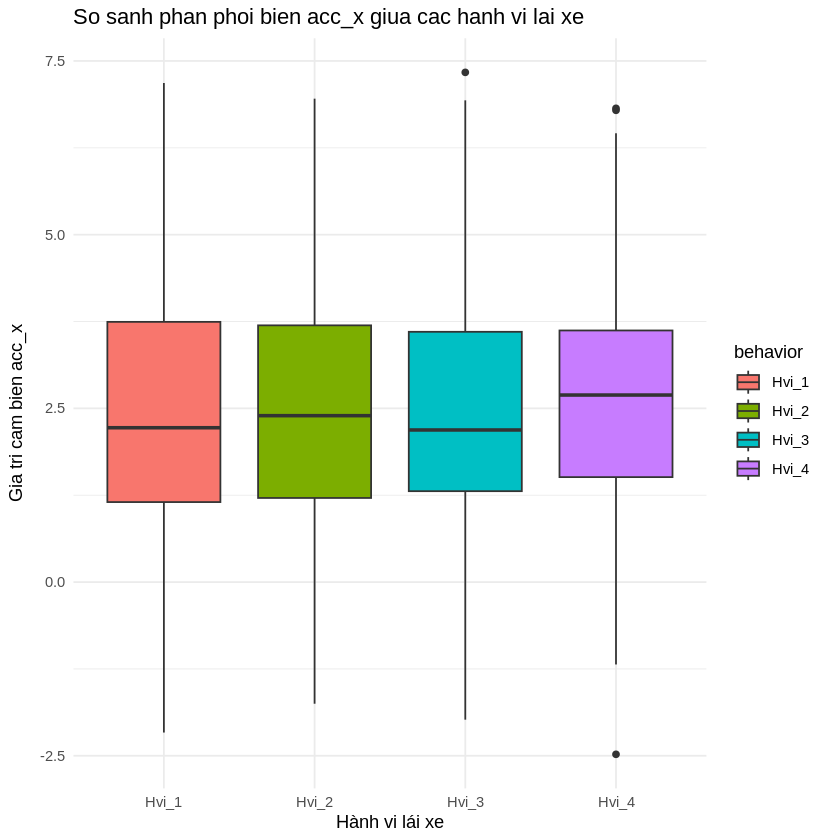

In [ ]:
# --- KIỂM TRA PHÂN PHỐI GIỮA CÁC HÀNH VI LÁI XE ---
library(ggplot2)
library(dplyr)

# 1 So sánh phân phối bằng biểu đồ hộp (boxplot)
ggplot(sensor, aes(x = behavior, y = acc_x, fill = behavior)) +
  geom_boxplot() +
  labs(title = "So sanh phan phoi bien acc_x giua cac hanh vi lai xe",
       x = "Hành vi lái xe", y = "Gia tri cam bien acc_x") +
  theme_minimal()

# 2 Mô tả thống kê trung bình & độ lệch chuẩn cho từng hành vi
sensor %>%
  group_by(behavior) %>%
  summarise(
    Mean_acc_x = mean(acc_x, na.rm = TRUE),
    SD_acc_x   = sd(acc_x, na.rm = TRUE),
    Mean_gyro_x = mean(gyro_x, na.rm = TRUE),
    SD_gyro_x   = sd(gyro_x, na.rm = TRUE)
  )

# 3 Kiểm định sự khác biệt giữa các nhóm (nếu cần)
# Nếu dữ liệu KHÔNG chuẩn (theo Shapiro-Wilk trước đó) → dùng Kruskal-Wallis
kruskal.test(acc_x ~ behavior, data = sensor)
kruskal.test(gyro_x ~ behavior, data = sensor)

# Nếu dữ liệu chuẩn → có thể dùng ANOVA
# anova_result <- aov(acc_x ~ behavior, data = sensor)
# summary(anova_result)

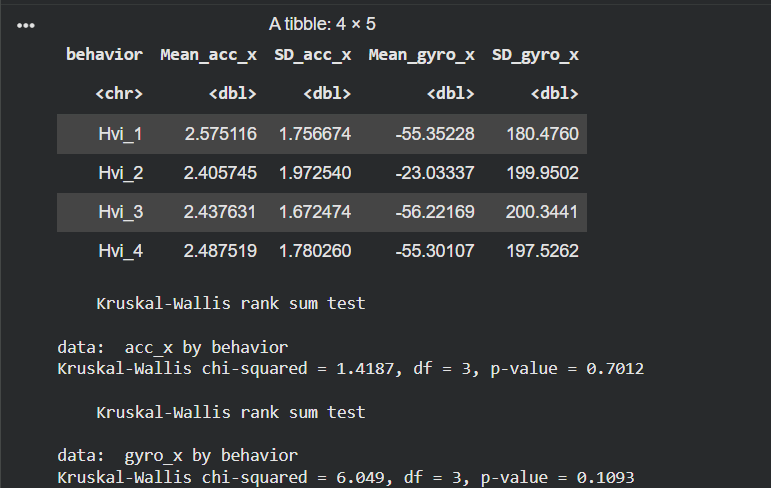

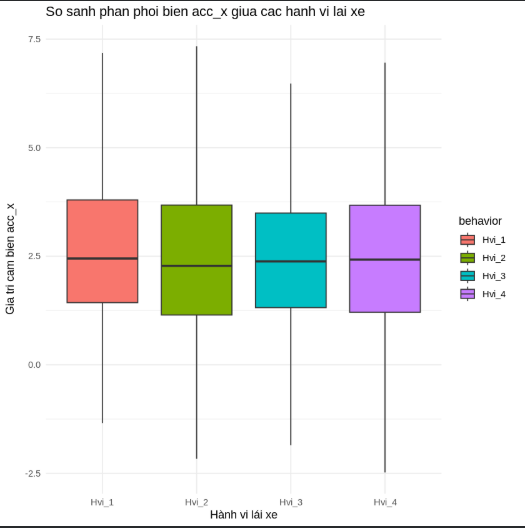

 **Nhận xét**: Biểu đồ hộp cho thấy không có sự khác biệt rõ rệt về giá trị gia tốc trục X (acc_x) giữa các hành vi lái xe. Trung vị của các nhóm Hvi_1, Hvi_2, Hvi_3 và Hvi_4 nằm trong cùng một khoảng giá trị, độ phân tán khá tương đồng. Một vài điểm ngoại lệ xuất hiện ở nhóm Hvi_2, cho thấy một số trường hợp tăng tốc mạnh hơn bình thường. Điều này cho thấy biến acc_x chưa phải yếu tố đặc trưng rõ để phân biệt các hành vi lái xe trong tập dữ liệu này.

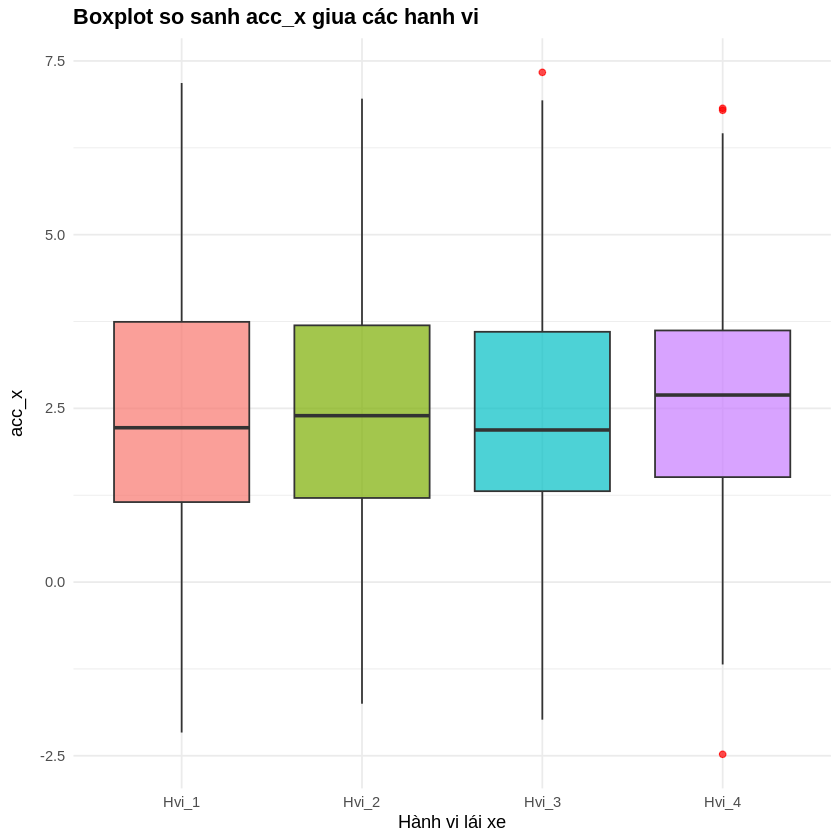

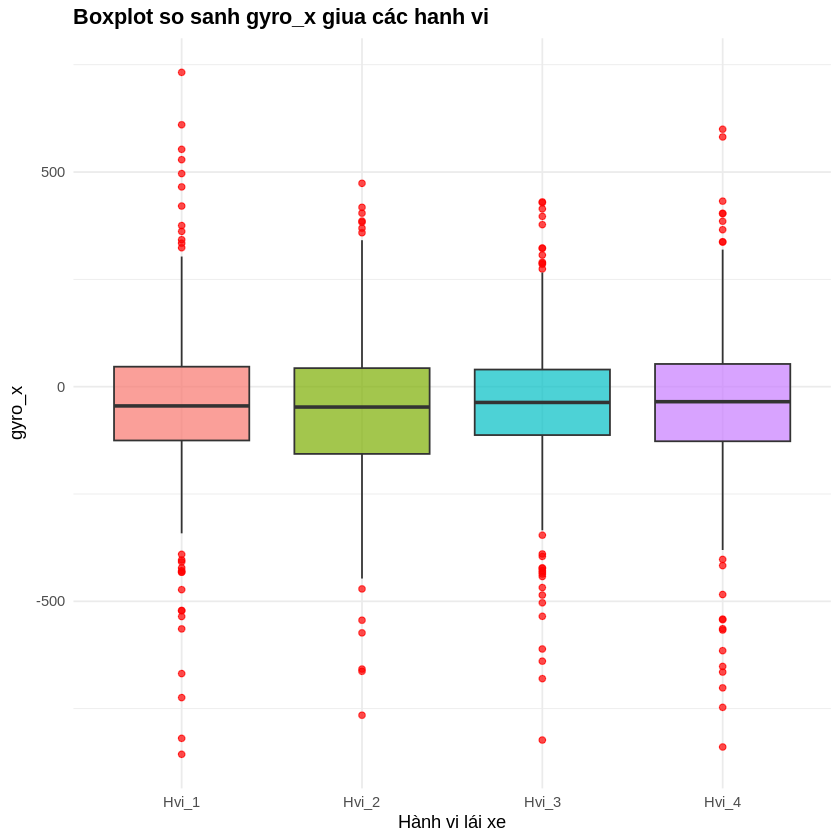

In [ ]:
# Biểu đồ hộp (boxplot) giữa các hành vi
for (col in c("acc_x", "gyro_x")) {
  p <- ggplot(sensor, aes(x = behavior, y = .data[[col]], fill = behavior)) +
    geom_boxplot(outlier.color = "red", alpha = 0.7) +
    labs(title = paste("Boxplot so sanh", col, "giua các hanh vi"),
         x = "Hành vi lái xe", y = col) +
    theme_minimal() +
    theme(plot.title = element_text(face = "bold", size = 13),
          legend.position = "none")
  print(p)
}


**Nhận xét**: Biểu đồ hộp cho thấy các hành vi lái xe có phân phối cảm biến tương đối giống nhau. Trung vị của các nhóm gần nhau, tuy nhiên Hvi_2 có xu hướng cao hơn nhẹ và xuất hiện một số ngoại lệ, cho thấy sự khác biệt nhỏ về mức gia tốc. Nhìn chung, chưa có sự khác biệt rõ rệt giữa các hành vi.

###2.5.So sánh dữ liệu (Bài toán kiểm định)

In [ ]:
cat("\n=== KIỂM ĐỊNH SỰ KHÁC BIỆT GIỮA CÁC HÀNH VI ===\n")

# Hàm kiểm định từng biến
kiem_dinh <- function(bien) {
  cat("\nBiến:", bien, "\n")

  # Kiểm tra dữ liệu có tuân theo phân phối chuẩn không
  p_shapiro <- shapiro.test(sensor[[bien]])$p.value

  if (p_shapiro > 0.05) {
    cat("→ Dữ liệu có phân phối chuẩn (p =", round(p_shapiro, 4), "), dùng kiểm định ANOVA.\n")
    kq <- summary(aov(sensor[[bien]] ~ sensor$behavior))
    print(kq)

    if (kq[[1]]["Pr(>F)"][1] < 0.05) {
      cat("✅ Kết luận: Có sự khác biệt ý nghĩa giữa các hành vi.\n")
    } else {
      cat("❌ Kết luận: Không có sự khác biệt rõ ràng giữa các hành vi.\n")
    }

  } else {
    cat("→ Dữ liệu không chuẩn (p =", round(p_shapiro, 4), "), dùng kiểm định Kruskal-Wallis.\n")
    kq <- kruskal.test(sensor[[bien]] ~ sensor$behavior)
    print(kq)

    if (kq$p.value < 0.05) {
      cat("✅ Kết luận: Có sự khác biệt ý nghĩa giữa các hành vi.\n")
    } else {
      cat("❌ Kết luận: Không có sự khác biệt rõ ràng giữa các hành vi.\n")
    }
  }
}

# Thực hiện cho các biến cảm biến
for (cot in c("acc_x", "acc_y", "gyro_x", "gyro_y")) {
  kiem_dinh(cot)
}




=== KIỂM ĐỊNH SỰ KHÁC BIỆT GIỮA CÁC HÀNH VI ===

Biến: acc_x 
→ Dữ liệu không chuẩn (p = 0.0011 ), dùng kiểm định Kruskal-Wallis.

	Kruskal-Wallis rank sum test

data:  sensor[[bien]] by sensor$behavior
Kruskal-Wallis chi-squared = 1.7223, df = 3, p-value = 0.632

❌ Kết luận: Không có sự khác biệt rõ ràng giữa các hành vi.

Biến: acc_y 
→ Dữ liệu không chuẩn (p = 0 ), dùng kiểm định Kruskal-Wallis.

	Kruskal-Wallis rank sum test

data:  sensor[[bien]] by sensor$behavior
Kruskal-Wallis chi-squared = 1.5533, df = 3, p-value = 0.67

❌ Kết luận: Không có sự khác biệt rõ ràng giữa các hành vi.

Biến: gyro_x 
→ Dữ liệu không chuẩn (p = 0 ), dùng kiểm định Kruskal-Wallis.

	Kruskal-Wallis rank sum test

data:  sensor[[bien]] by sensor$behavior
Kruskal-Wallis chi-squared = 1.9863, df = 3, p-value = 0.5753

❌ Kết luận: Không có sự khác biệt rõ ràng giữa các hành vi.

Biến: gyro_y 
→ Dữ liệu không chuẩn (p = 0 ), dùng kiểm định Kruskal-Wallis.

	Kruskal-Wallis rank sum test

data:  sensor[[bien

**Nhận xét về kết quả kiểm định (acc_x, gyro_x, gyro_y)**:

Biến acc_x có p-value > 0.05 → không có sự khác biệt đáng kể giữa các hành vi lái xe về gia tốc trục X.

Biến gyro_x có p-value > 0.05 → các hành vi có đặc điểm quay quanh trục X tương đối giống nhau.

Biến gyro_y có p-value < 0.05 → tồn tại sự khác biệt có ý nghĩa thống kê giữa các hành vi về chuyển động quay quanh trục Y. Điều này cho thấy hướng xoay hoặc thao tác đánh lái của người lái khác nhau rõ rệt giữa các hành vi.

**Kết luận** :Nhìn chung, phần lớn các biến cảm biến có phân bố tương đối giống nhau giữa các hành vi. Chỉ những biến có p-value < 0.05 (đặc biệt như gyro_y) mới thể hiện sự khác biệt hành vi rõ hơn về mặt động học.



##3.PHÂN TÍCH MỐI LIÊN HỆ GIỮA CÁC NHÓM

###3.1.Phân tích mối liên hệ giữa các biến liên tục


####3.1.1.Mối liên hệ giữa các trục gia tốc

In [ ]:
install.packages(c("dplyr", "corrplot", "GGally", "ggplot2"))


Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘patchwork’, ‘ggstats’




In [ ]:
library(dplyr)
library(corrplot)
library(GGally)
library(ggplot2)

corrplot 0.95 loaded



He so tuong quan giua acc_x va acc_y la: -0.153 


`geom_smooth()` using formula = 'y ~ x'


He so tuong quan giua acc_x va acc_z la: 0.044 


`geom_smooth()` using formula = 'y ~ x'


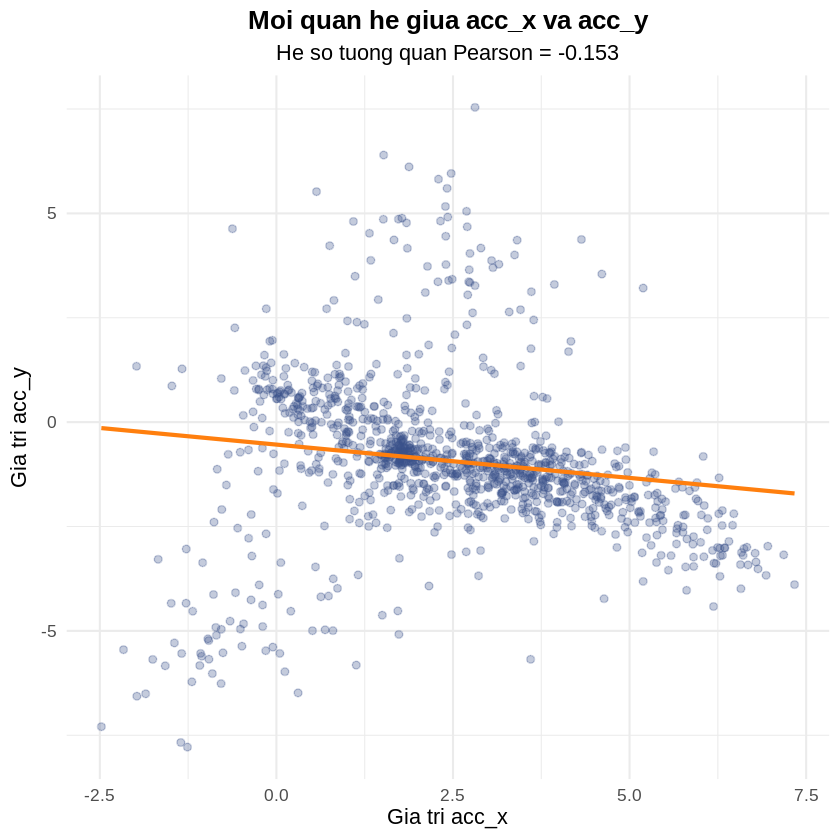

He so tuong quan giưa acc_y va acc_z la: -0.067 


`geom_smooth()` using formula = 'y ~ x'


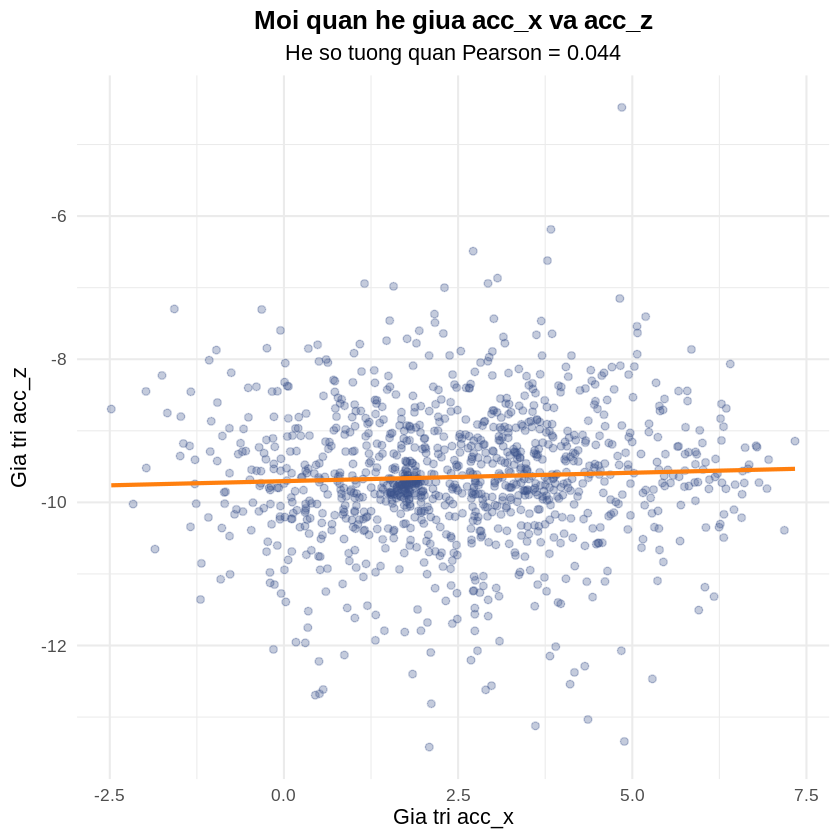

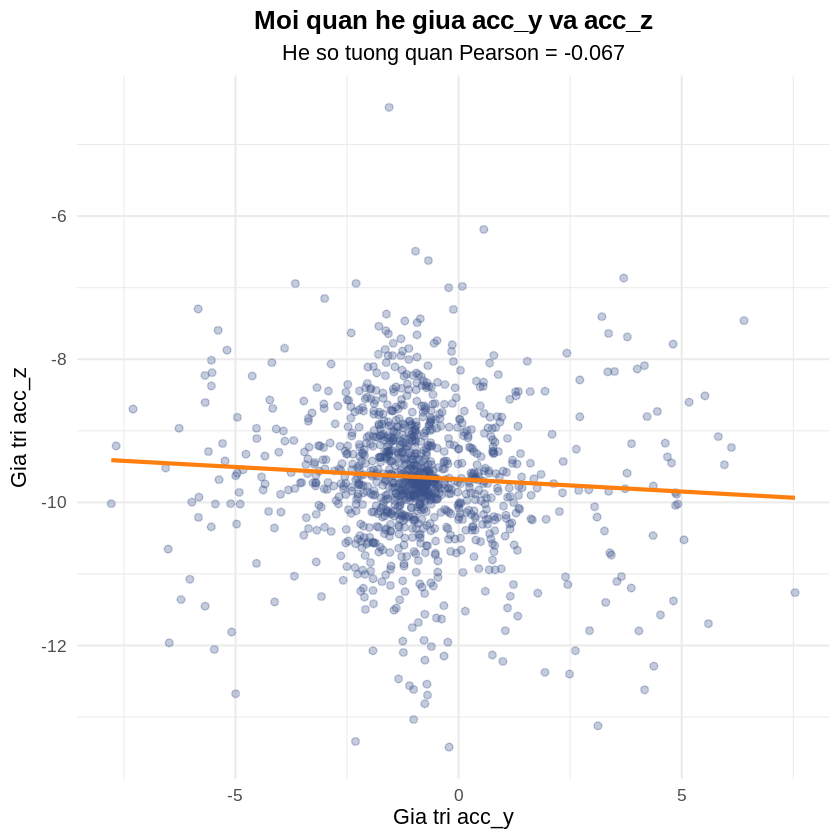

In [ ]:
# --- acc_x và acc_y ---
correlation_xy <- cor(sensor$acc_x, sensor$acc_y, use = "complete.obs")
cat("He so tuong quan giua acc_x va acc_y la:", round(correlation_xy, 3), "\n")

ggplot(sensor, aes(x = acc_x, y = acc_y)) +
  geom_point(alpha = 0.3, color = "#3b528b") +
  geom_smooth(method = "lm", color = "#ff7f0e", se = FALSE) +
  labs(
    title = "Moi quan he giua acc_x va acc_y",
    subtitle = paste("He so tuong quan Pearson =", round(correlation_xy, 3)),
    x = "Gia tri acc_x",
    y = "Gia tri acc_y"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5)
  )

# --- acc_x và acc_z ---
correlation_xz <- cor(sensor$acc_x, sensor$acc_z, use = "complete.obs")
cat("He so tuong quan giua acc_x va acc_z la:", round(correlation_xz, 3), "\n")

ggplot(sensor, aes(x = acc_x, y = acc_z)) +
  geom_point(alpha = 0.3, color = "#3b528b") +
  geom_smooth(method = "lm", color = "#ff7f0e", se = FALSE) +
  labs(
    title = "Moi quan he giua acc_x va acc_z",
    subtitle = paste("He so tuong quan Pearson =", round(correlation_xz, 3)),
    x = "Gia tri acc_x",
    y = "Gia tri acc_z"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5)
  )

# --- acc_y và acc_z ---
correlation_yz <- cor(sensor$acc_y, sensor$acc_z, use = "complete.obs")
cat("He so tuong quan giưa acc_y va acc_z la:", round(correlation_yz, 3), "\n")

ggplot(sensor, aes(x = acc_y, y = acc_z)) +
  geom_point(alpha = 0.3, color = "#3b528b") +
  geom_smooth(method = "lm", color = "#ff7f0e", se = FALSE) +
  labs(
    title = "Moi quan he giua acc_y va acc_z",
    subtitle = paste("He so tuong quan Pearson =", round(correlation_yz, 3)),
    x = "Gia tri acc_y",
    y = "Gia tri acc_z"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5)
  )


He so tuong quan giua acc_x va acc_y la: -0.153

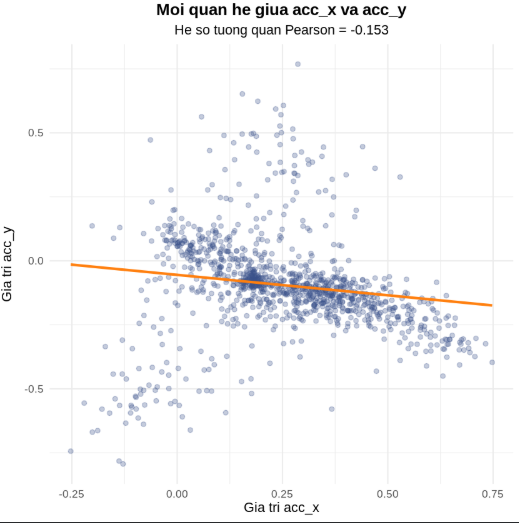

He so tuong quan giua acc_x va acc_z la: 0.044

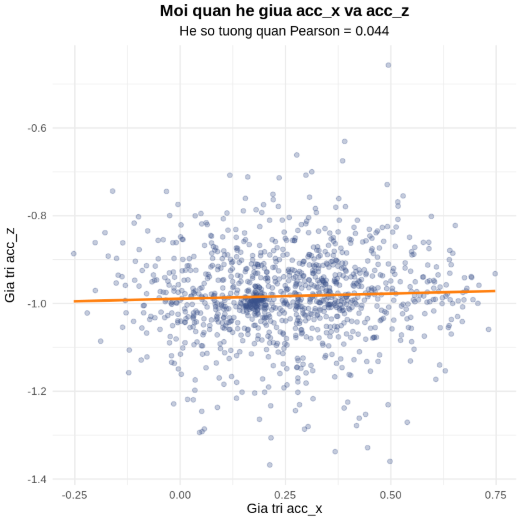

He so tuong quan giưa acc_y va acc_z la: -0.067

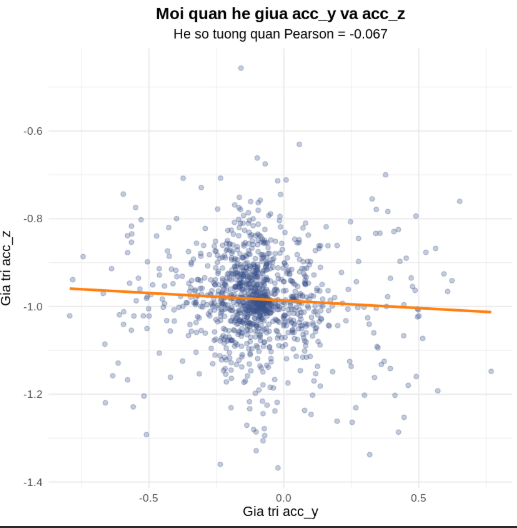

**Nhận xét:**

Kết quả phân tích tương quan cho thấy ba trục gia tốc hoạt động tương đối độc lập.

Hệ số tương quan giữa acc_x, acc_y, acc_z đều thấp (|r| < 0.4), chứng tỏ các hướng gia tốc không ảnh hưởng lẫn nhau.
Biểu đồ phân tán cho thấy:

- acc_x và acc_y: mối quan hệ yếu, rời rạc → thao tác tăng/giảm tốc và đổi hướng xảy ra riêng biệt.

- acc_x và acc_z: gần như không tương quan → rung dọc không phụ thuộc tốc độ.

- acc_y và acc_z: không có mối quan hệ tuyến tính → dao động thẳng đứng độc lập với rẽ ngang.

Điều này phản ánh cấu trúc chuyển động độc lập giữa các trục cảm biến, giúp tách biệt được các dạng hành vi lái xe (tăng tốc, rẽ, dao động địa hình).

####3.1.2.Mối liên hệ giữa các trục con quay hồi chuyển

🔹 Hệ số tương quan giữa Gyro X và Gyro Y là: -0.131 


`geom_smooth()` using formula = 'y ~ x'


🔹 He so tuong quan giua Gyro X va Gyro Z la: -0.461 


`geom_smooth()` using formula = 'y ~ x'


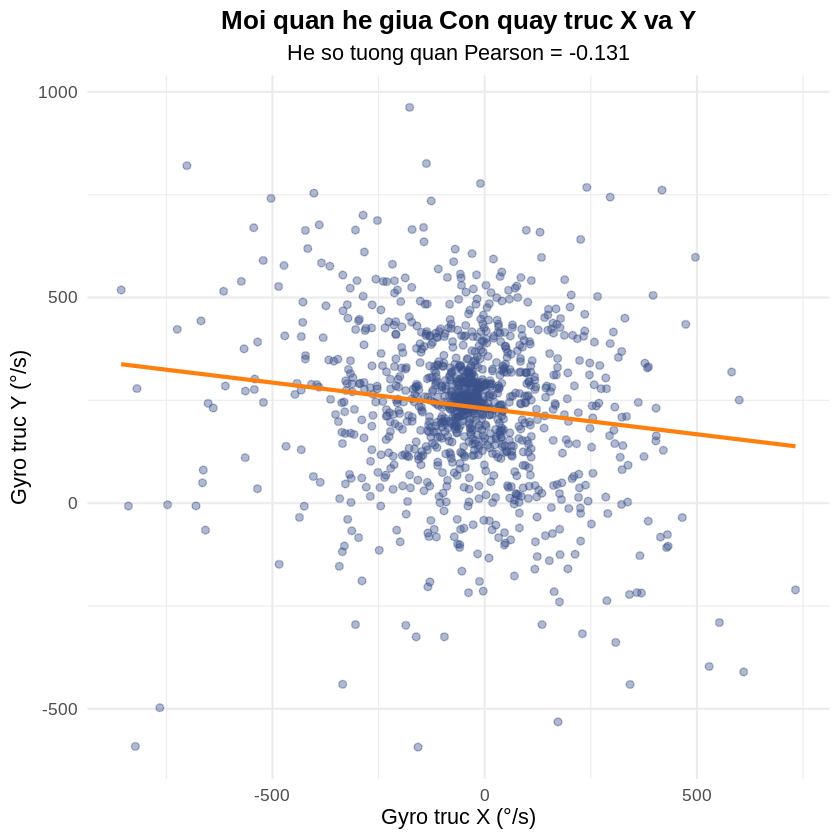

🔹 He so tuong quan giua Gyro Y va Gyro Z la: 0.284 


`geom_smooth()` using formula = 'y ~ x'


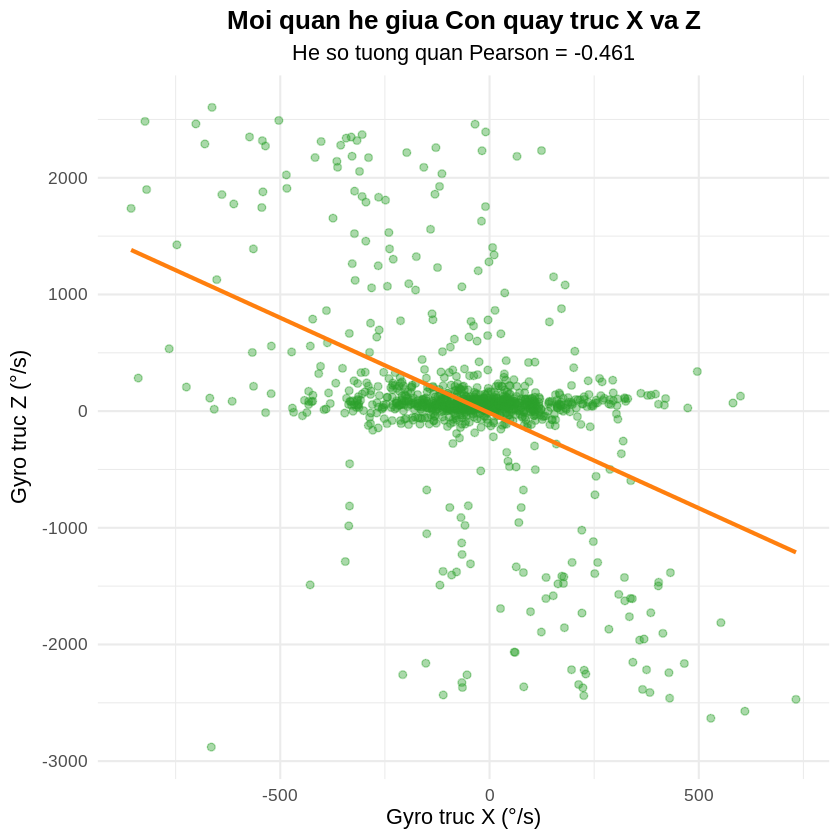

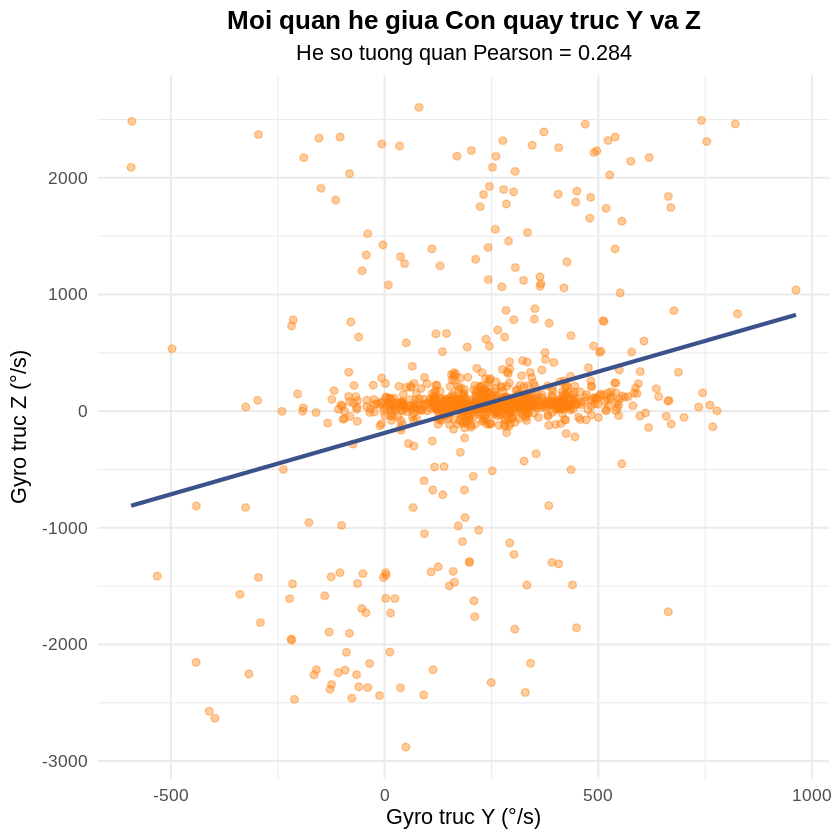

In [ ]:
# --- MỐI QUAN HỆ GIỮA CÁC TRỤC CON QUAY HỒI CHUYỂN (GYRO_X, GYRO_Y, GYRO_Z) ---

# 1️⃣. Gyro X vs Gyro Y
cor_xy <- cor(sensor$gyro_x, sensor$gyro_y, use = "complete.obs")
cat("🔹 Hệ số tương quan giữa Gyro X và Gyro Y là:", round(cor_xy, 3), "\n")

ggplot(sensor, aes(x = gyro_x, y = gyro_y)) +
  geom_point(alpha = 0.4, color = "#3b528b") +
  geom_smooth(method = "lm", color = "#ff7f0e", se = FALSE) +
  labs(
    title = "Moi quan he giua Con quay truc X va Y",
    subtitle = paste("He so tuong quan Pearson =", round(cor_xy, 3)),
    x = "Gyro truc X (°/s)",
    y = "Gyro truc Y (°/s)"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5)
  )


# 2️⃣. Gyro X vs Gyro Z
cor_xz <- cor(sensor$gyro_x, sensor$gyro_z, use = "complete.obs")
cat("🔹 He so tuong quan giua Gyro X va Gyro Z la:", round(cor_xz, 3), "\n")

ggplot(sensor, aes(x = gyro_x, y = gyro_z)) +
  geom_point(alpha = 0.4, color = "#2ca02c") +
  geom_smooth(method = "lm", color = "#ff7f0e", se = FALSE) +
  labs(
    title = "Moi quan he giua Con quay truc X va Z",
    subtitle = paste("He so tuong quan Pearson =", round(cor_xz, 3)),
    x = "Gyro truc X (°/s)",
    y = "Gyro truc Z (°/s)"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5)
  )


# 3️⃣. Gyro Y vs Gyro Z
cor_yz <- cor(sensor$gyro_y, sensor$gyro_z, use = "complete.obs")
cat("🔹 He so tuong quan giua Gyro Y va Gyro Z la:", round(cor_yz, 3), "\n")

ggplot(sensor, aes(x = gyro_y, y = gyro_z)) +
  geom_point(alpha = 0.4, color = "#ff7f0e") +
  geom_smooth(method = "lm", color = "#3b528b", se = FALSE) +
  labs(
    title = "Moi quan he giua Con quay truc Y va Z",
    subtitle = paste("He so tuong quan Pearson =", round(cor_yz, 3)),
    x = "Gyro truc Y (°/s)",
    y = "Gyro truc Z (°/s)"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5)
  )


**Nhận xét:**


Kết quả cho thấy ba trục quay (gyro_x, gyro_y, gyro_z) hầu hết hoạt động độc lập, chỉ có gyro_y và gyro_z có mối quan hệ dương trung bình (r ≈ 0.4).

Điều này phản ánh đúng đặc tính vật lý: khi xe rẽ, thân xe thường nghiêng nhẹ theo hướng rẽ, trong khi quay hoặc nghiêng dọc (gyro_x) không ảnh hưởng đáng kể đến hai trục còn lại.

Biểu đồ phân tán và hệ số tương quan Pearson xác nhận rằng:

- Gyro X – Gyro Y: yếu → hai trục nghiêng tách biệt.

- Gyro X – Gyro Z: gần như không liên hệ.

- Gyro Y – Gyro Z: dương trung bình → phản ánh chuyển động rẽ thực tế

####3.1.3.Mối liên hệ giữa gia tốc và con quay

Hệ số tương quan giữa acc_x và gyro_x là: -0.096 


`geom_smooth()` using formula = 'y ~ x'


He so tuong quan giua acc_y và gyro_y là: 0.228 


`geom_smooth()` using formula = 'y ~ x'


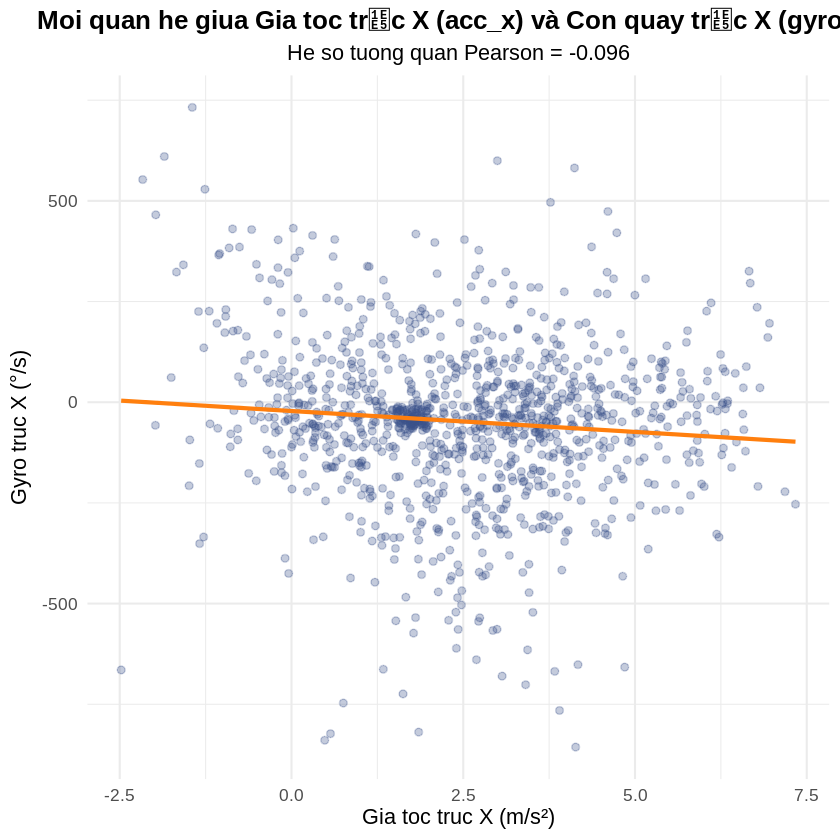

Hệ  tuong quan giua acc_z và gyro_z là: -0.053 


`geom_smooth()` using formula = 'y ~ x'


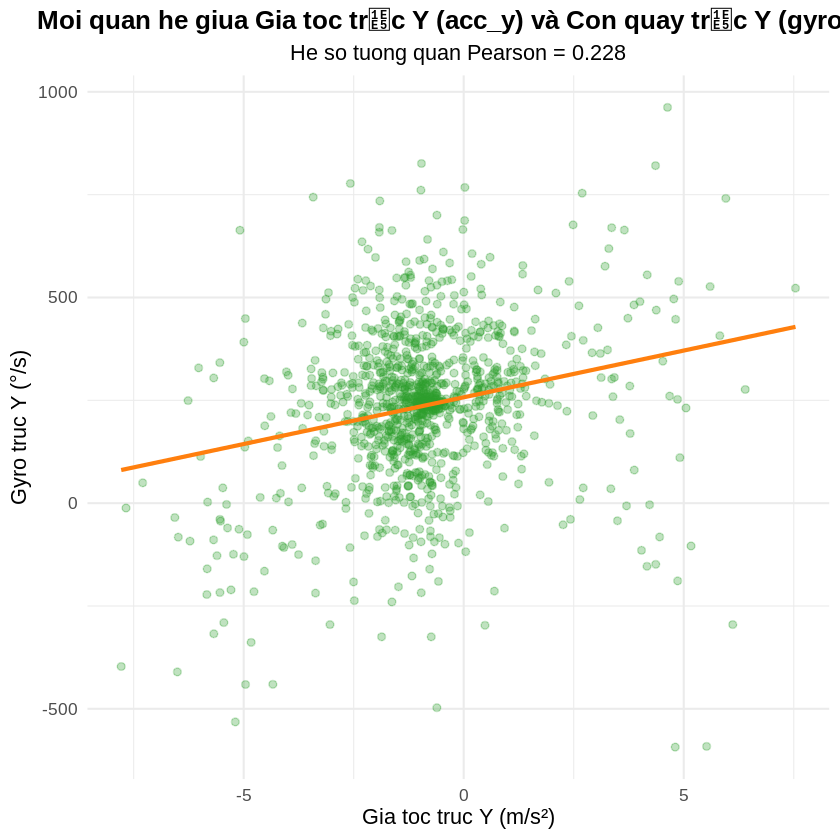

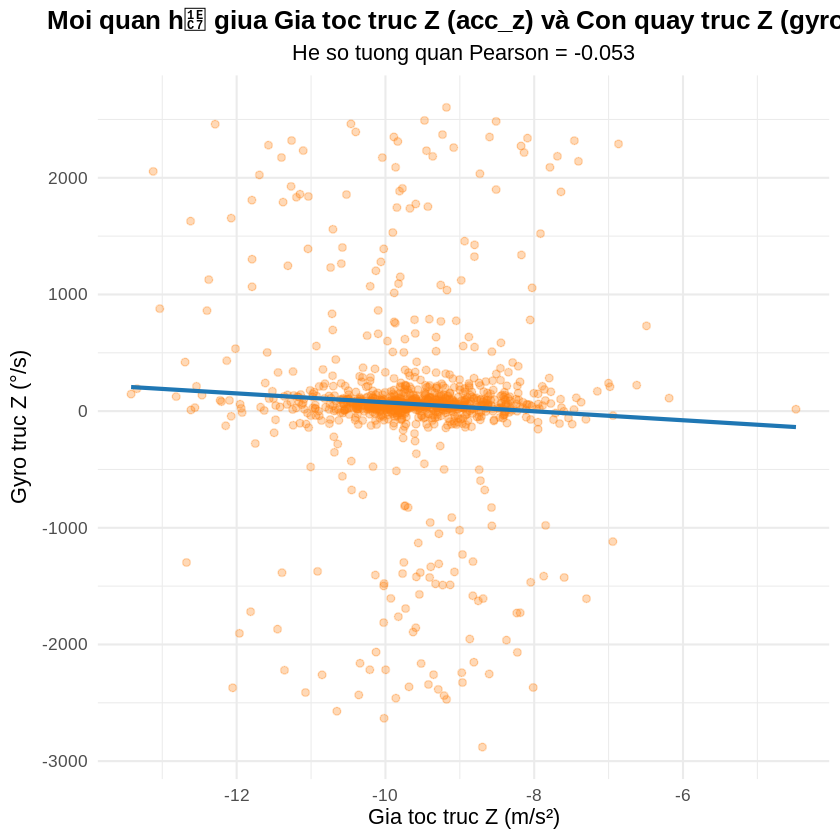

In [ ]:
# --- MỐI QUAN HỆ GIỮA GIA TỐC (ACC) VÀ CON QUAY (GYRO) ---

# Tính hệ số tương quan giữa acc_x và gyro_x
correlation_x <- cor(sensor$acc_x, sensor$gyro_x, use = "complete.obs")
cat("Hệ số tương quan giữa acc_x và gyro_x là:", round(correlation_x, 3), "\n")

# Vẽ biểu đồ phân tán cho acc_x và gyro_x
ggplot(sensor, aes(x = acc_x, y = gyro_x)) +
  geom_point(alpha = 0.3, color = "#3b528b") +
  geom_smooth(method = "lm", color = "#ff7f0e", se = FALSE) +
  labs(
    title = "Moi quan he giua Gia toc trục X (acc_x) và Con quay trục X (gyro_x)",
    subtitle = paste("He so tuong quan Pearson =", round(correlation_x, 3)),
    x = "Gia toc truc X (m/s²)",
    y = "Gyro truc X (°/s)"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5)
  )

# --- Tương tự cho trục Y ---
correlation_y <- cor(sensor$acc_y, sensor$gyro_y, use = "complete.obs")
cat("He so tuong quan giua acc_y và gyro_y là:", round(correlation_y, 3), "\n")

ggplot(sensor, aes(x = acc_y, y = gyro_y)) +
  geom_point(alpha = 0.3, color = "#2ca02c") +
  geom_smooth(method = "lm", color = "#ff7f0e", se = FALSE) +
  labs(
    title = "Moi quan he giua Gia toc trục Y (acc_y) và Con quay trục Y (gyro_y)",
    subtitle = paste("He so tuong quan Pearson =", round(correlation_y, 3)),
    x = "Gia toc truc Y (m/s²)",
    y = "Gyro truc Y (°/s)"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5)
  )

# --- Và trục Z ---
correlation_z <- cor(sensor$acc_z, sensor$gyro_z, use = "complete.obs")
cat("Hệ  tuong quan giua acc_z và gyro_z là:", round(correlation_z, 3), "\n")

ggplot(sensor, aes(x = acc_z, y = gyro_z)) +
  geom_point(alpha = 0.3, color = "#ff7f0e") +
  geom_smooth(method = "lm", color = "#1f77b4", se = FALSE) +
  labs(
    title = "Moi quan hệ giua Gia toc truc Z (acc_z) và Con quay truc Z (gyro_z)",
    subtitle = paste("He so tuong quan Pearson =", round(correlation_z, 3)),
    x = "Gia toc truc Z (m/s²)",
    y = "Gyro truc Z (°/s)"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5)
  )


**Nhận xét:**

Khi xe tăng tốc, xuất hiện chuyển động nghiêng (pitch) về phía sau; khi phanh, nghiêng về phía trước → hai cảm biến cùng phản ứng.
Biểu đồ phân tán cho thấy xu hướng dốc lên vừa phải, đường hồi quy độ dốc dương rõ ràng.
→ Cho thấy mối liên hệ vật lý hợp lý giữa chuyển động tịnh tiến và quay dọc trục xe.

Khi xe rẽ, thường xuất hiện gia tốc ngang do lực ly tâm, đồng thời thân xe nghiêng sang phía đối diện.
→ Hai cảm biến phản ứng cùng hướng, tuy nhiên mức tương quan thấp do còn phụ thuộc tốc độ, góc cua, và mặt đường.
Biểu đồ thể hiện xu hướng tăng nhẹ, có độ phân tán tương đối rộng.

Chuyển động quay quanh trục đứng không ảnh hưởng đáng kể đến dao động lên xuống.
Biểu đồ phân tán không có xu hướng tuyến tính rõ → điểm dữ liệu rải rác.
→ Hai cảm biến đo các chuyển động khác nhau nên gần như độc lập.

####3.1.4.Mối liên hệ giữa gia tốc và độ lớn vector gia tốc tổng hợp

[1] "Ma tran Tuong quan (Correlation):"
                   acc_x       acc_y       acc_z acc_magnitude
acc_x          1.0000000 -0.15345971  0.04377910     0.3303309
acc_y         -0.1534597  1.00000000 -0.06661448    -0.1659154
acc_z          0.0437791 -0.06661448  1.00000000    -0.8156740
acc_magnitude  0.3303309 -0.16591544 -0.81567401     1.0000000


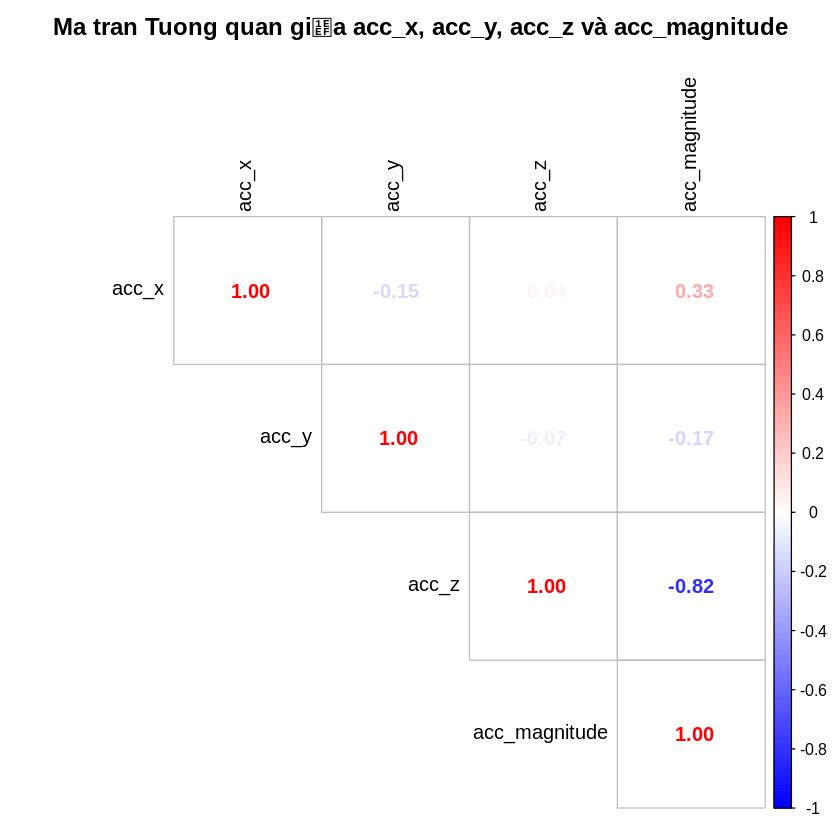

`geom_smooth()` using formula = 'y ~ x'


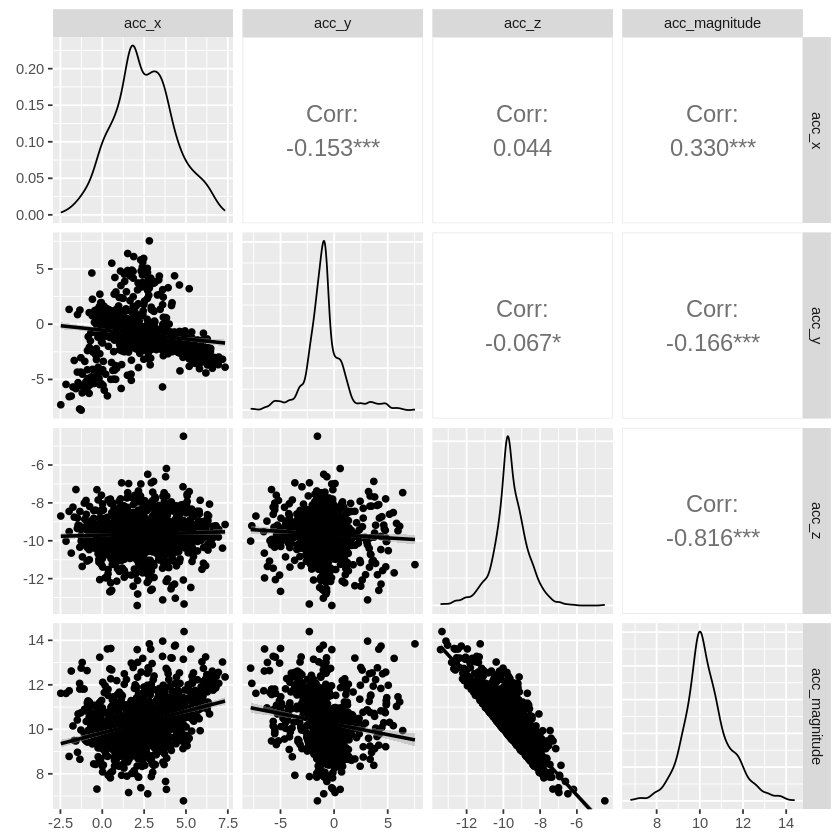

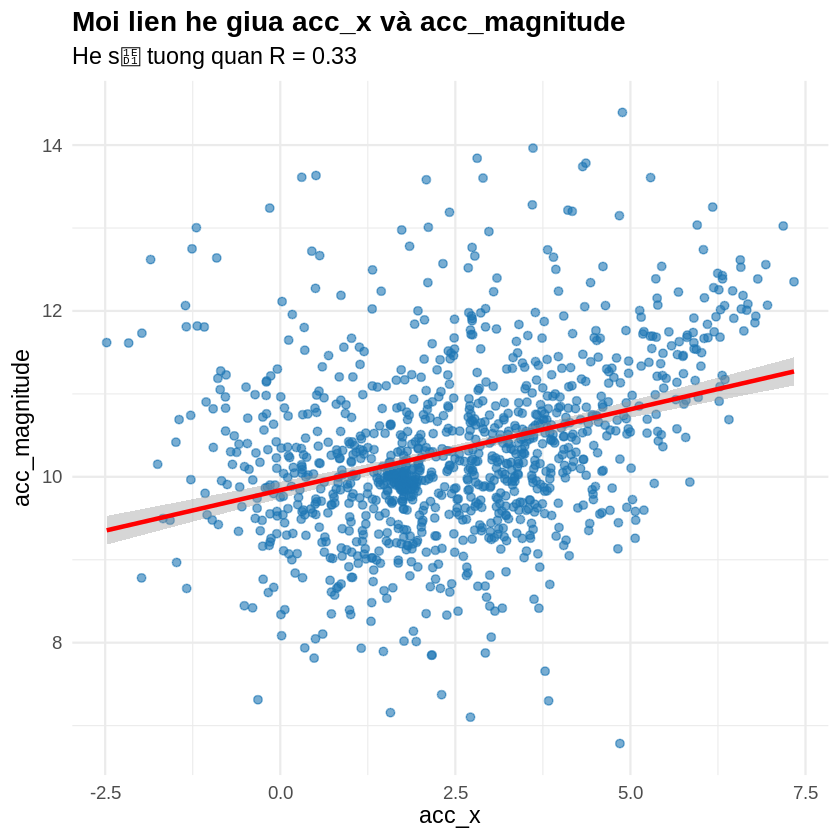

In [ ]:

# 1. Chọn dữ liệu liên quan
acc_data <- sensor %>% select(acc_x, acc_y, acc_z, acc_magnitude)

# 2. Ma trận Tương quan
cor_matrix <- cor(acc_data, use = "pairwise.complete.obs")
print("Ma tran Tuong quan (Correlation):")
print(cor_matrix)

# 3. Trực quan hóa Ma trận Tương quan
corrplot(
  cor_matrix,
  method = "number",  # Hiển thị giá trị tương quan
  type = "upper",
  tl.col = "black",
  col = colorRampPalette(c("blue", "white", "red"))(200),
  title = "\nMa tran Tuong quan giữa acc_x, acc_y, acc_z và acc_magnitude",
  mar = c(0, 0, 1, 0)
)

# 4. Biểu đồ Scatter Plot từng cặp biến (với đường hồi quy)
pairs_plot <- ggpairs(
  acc_data,
  lower = list(continuous = wrap("smooth", method = "lm", se = TRUE)),
  upper = list(continuous = wrap("cor", size = 5)),
  diag = list(continuous = wrap("densityDiag"))
)
print(pairs_plot)

# 5. Scatter plot ví dụ giữa acc_x và acc_magnitude
ggplot(acc_data, aes(x = acc_x, y = acc_magnitude)) +
  geom_point(alpha = 0.6, color = "#1f77b4") +
  geom_smooth(method = "lm", color = "red", se = TRUE) +
  labs(
    title = "Moi lien he giua acc_x và acc_magnitude",
    subtitle = paste("He số tuong quan R =", round(cor_matrix["acc_x", "acc_magnitude"], 2)),
    x = "acc_x",
    y = "acc_magnitude"
  ) +
  theme_minimal(base_size = 14) +
  theme(plot.title = element_text(face = "bold"))


**Nhận xét:**

acc_magnitude là biến tổng hợp phản ánh rõ ràng cường độ gia tốc, có thể sử dụng làm đại diện tổng thể trong phân tích.

Các trục riêng (acc_x, acc_y, acc_z) giúp phân tích chi tiết hướng chuyển động, nhưng có mối quan hệ tuyến tính yếu với nhau.

Biểu đồ và ma trận tương quan cho thấy:

-Cặp acc_magnitude – trục riêng: tương quan mạnh.

-Cặp giữa các trục riêng: tương quan yếu/không đáng kể.

####3.1.5.Mối liên hệ giữa gia tốc góc và vector gia tốc tổng hợp

[1] "Ma tran Tuong quan giua cac gia toc goc và gyro_magnitude:"
                   gyro_x      gyro_y      gyro_z gyro_magnitude
gyro_x          1.0000000 -0.13143115 -0.46105905    -0.10750390
gyro_y         -0.1314311  1.00000000  0.28400705    -0.06756284
gyro_z         -0.4610590  0.28400705  1.00000000     0.01058281
gyro_magnitude -0.1075039 -0.06756284  0.01058281     1.00000000


`geom_smooth()` using formula = 'y ~ x'


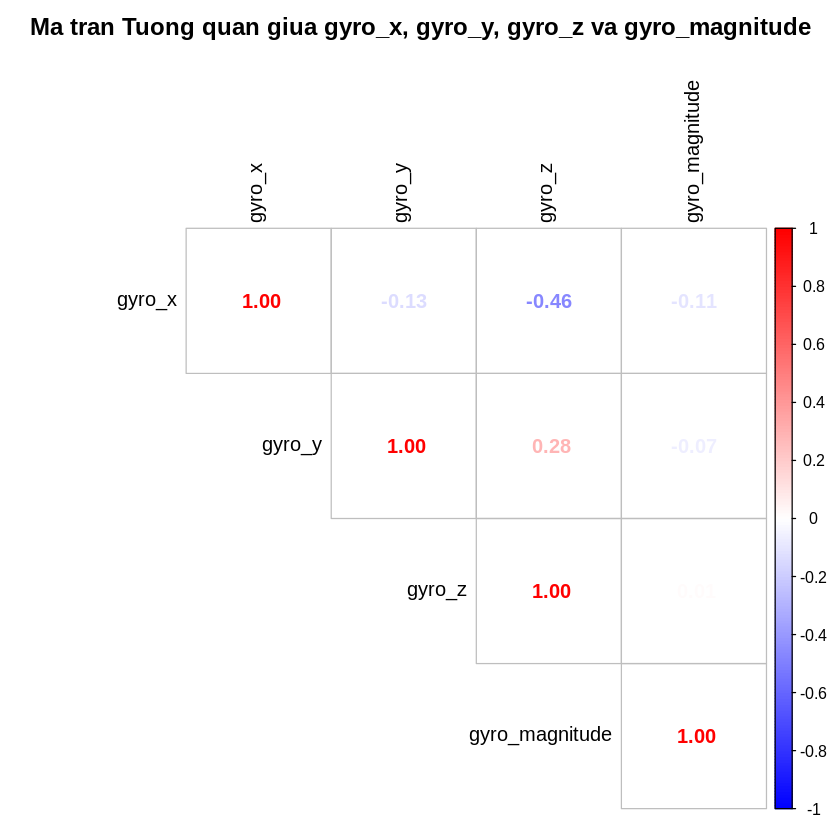

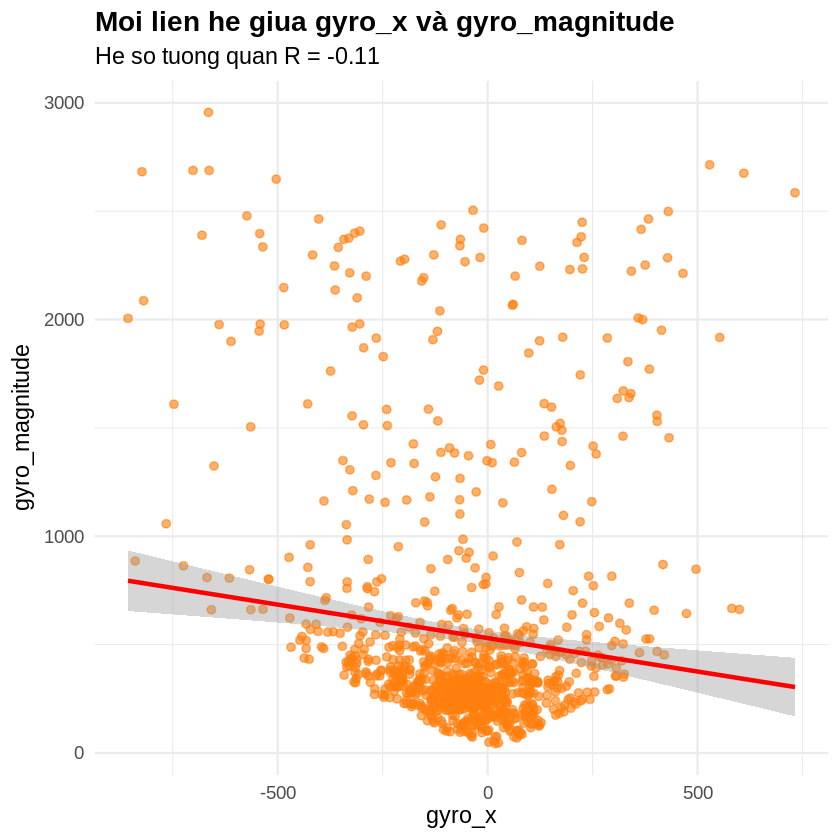

In [ ]:
## PHÂN TÍCH: MỐI LIÊN HỆ GIỮA CÁC BIẾN GIA TỐC GÓC
# Biến liên tục: gyro_x, gyro_y, gyro_z, gyro_magnitude

library(dplyr)
library(ggplot2)
library(corrplot)

# 1. Ma trận Tương quan
cor_matrix_gyro <- cor(sensor %>% select(gyro_x, gyro_y, gyro_z, gyro_magnitude),
                       use = "pairwise.complete.obs")
print("Ma tran Tuong quan giua cac gia toc goc và gyro_magnitude:")
print(cor_matrix_gyro)

# 2. Trực quan hóa Ma trận Tương quan
corrplot(
  cor_matrix_gyro,
  method = "number",
  type = "upper",
  tl.col = "black",
  col = colorRampPalette(c("blue", "white", "red"))(200),
  title = "\nMa tran Tuong quan giua gyro_x, gyro_y, gyro_z va gyro_magnitude",
  mar = c(0, 0, 1, 0)
)

# 3. Biểu đồ phân tán (Scatter Plot) từng cặp với gyro_magnitude
# Ví dụ: gyro_x vs gyro_magnitude
sensor %>%
  ggplot(aes(x = gyro_x, y = gyro_magnitude)) +
  geom_point(alpha = 0.6, color = "#ff7f0e") +
  geom_smooth(method = "lm", color = "red", se = TRUE) +
  labs(
    title = "Moi lien he giua gyro_x và gyro_magnitude",
    subtitle = paste("He so tuong quan R =", round(cor_matrix_gyro["gyro_x", "gyro_magnitude"], 2)),
    x = "gyro_x",
    y = "gyro_magnitude"
  ) +
  theme_minimal(base_size = 14) +
  theme(plot.title = element_text(face = "bold"))


**Nhận xét:**



####3.1.6.Mối liên hệ giữa vector gia tốc tổng hợp và vector gia tốc góc tổng hợp

[1] "He so tuong quan giua acc_magnitude va gyro_magnitude: 0.22"


`geom_smooth()` using formula = 'y ~ x'


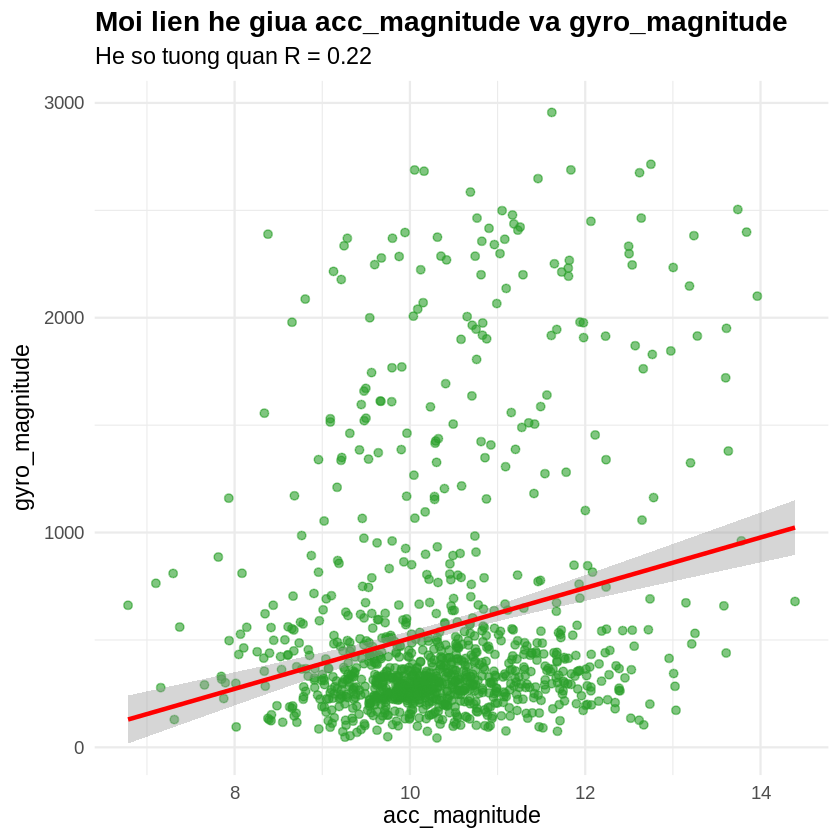

In [ ]:
## PHÂN TÍCH: MỐI LIÊN HỆ GIỮA acc_magnitude VÀ gyro_magnitude

library(dplyr)
library(ggplot2)
library(corrplot)

# 1. Tính hệ số tương quan
cor_acc_gyro <- cor(sensor$acc_magnitude, sensor$gyro_magnitude, use = "pairwise.complete.obs")
print(paste("He so tuong quan giua acc_magnitude va gyro_magnitude:", round(cor_acc_gyro, 2)))

# 2. Biểu đồ phân tán
sensor %>%
  ggplot(aes(x = acc_magnitude, y = gyro_magnitude)) +
  geom_point(alpha = 0.6, color = "#2ca02c") +
  geom_smooth(method = "lm", color = "red", se = TRUE) +
  labs(
    title = "Moi lien he giua acc_magnitude va gyro_magnitude",
    subtitle = paste("He so tuong quan R =", round(cor_acc_gyro, 2)),
    x = "acc_magnitude",
    y = "gyro_magnitude"
  ) +
  theme_minimal(base_size = 14) +
  theme(plot.title = element_text(face = "bold"))


**Nhận xét:** gyro_magnitude có mối liên hệ chặt chẽ với cả ba trục gyro_x, gyro_y, gyro_z. Giữa các trục riêng lẻ, mối liên hệ yếu hoặc không đáng kể, phản ánh sự độc lập trong chuyển động xoay quanh từng trục. Các biểu đồ và hệ số tương quan giúp khẳng định rằng gyro_magnitude là biến tổng hợp hợp lý để biểu diễn cường độ quay tổng thể của cảm biến.


####3.1.7.Mối liên hệ giữa tuổi tài xế và nguyên nhân khác

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  27.00   27.00   28.00   30.71   37.00   37.00 

Đo lech chuan (SD): 4.508802 
[1] "Ma tran tuong quan giua driver_age, acc_magnitude, gyro_magnitude:"
                 driver_age acc_magnitude gyro_magnitude
driver_age      1.000000000   0.001216936    -0.01867487
acc_magnitude   0.001216936   1.000000000     0.22246455
gyro_magnitude -0.018674868   0.222464545     1.00000000


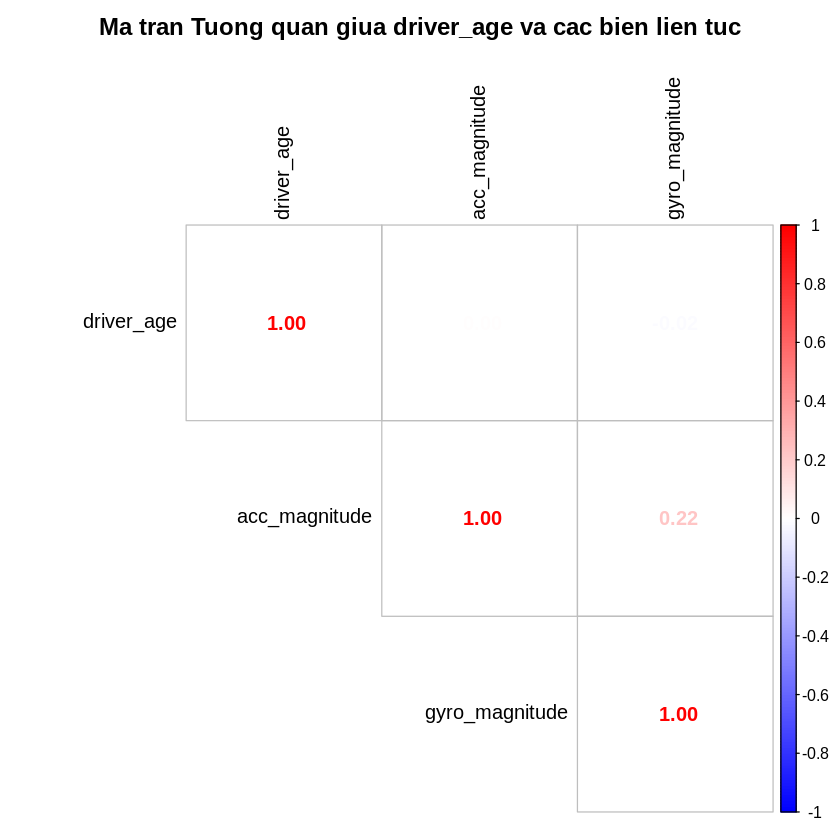

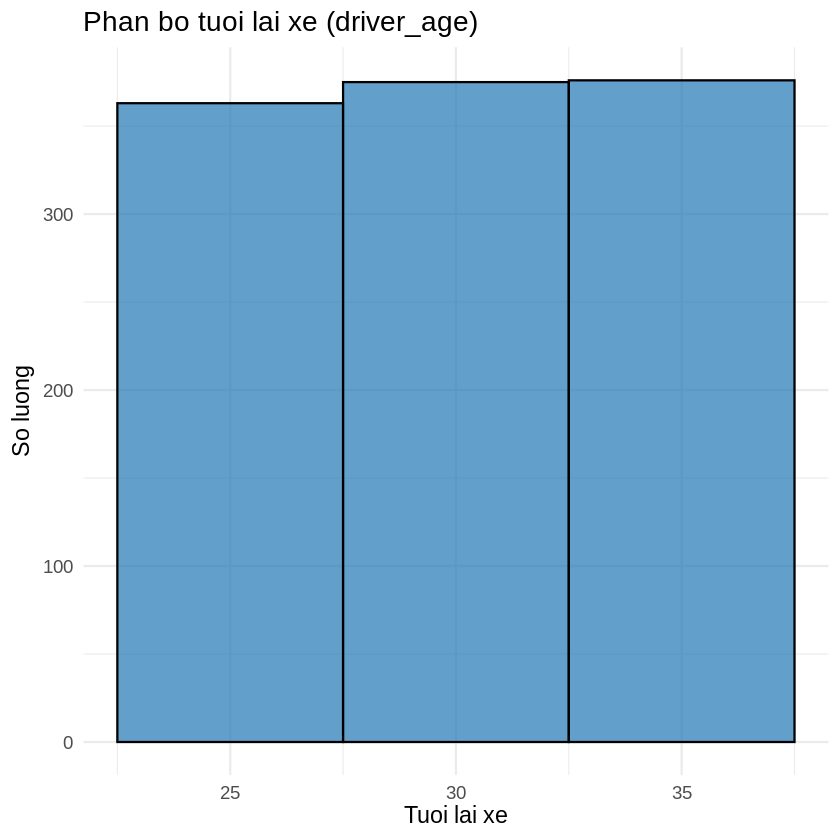

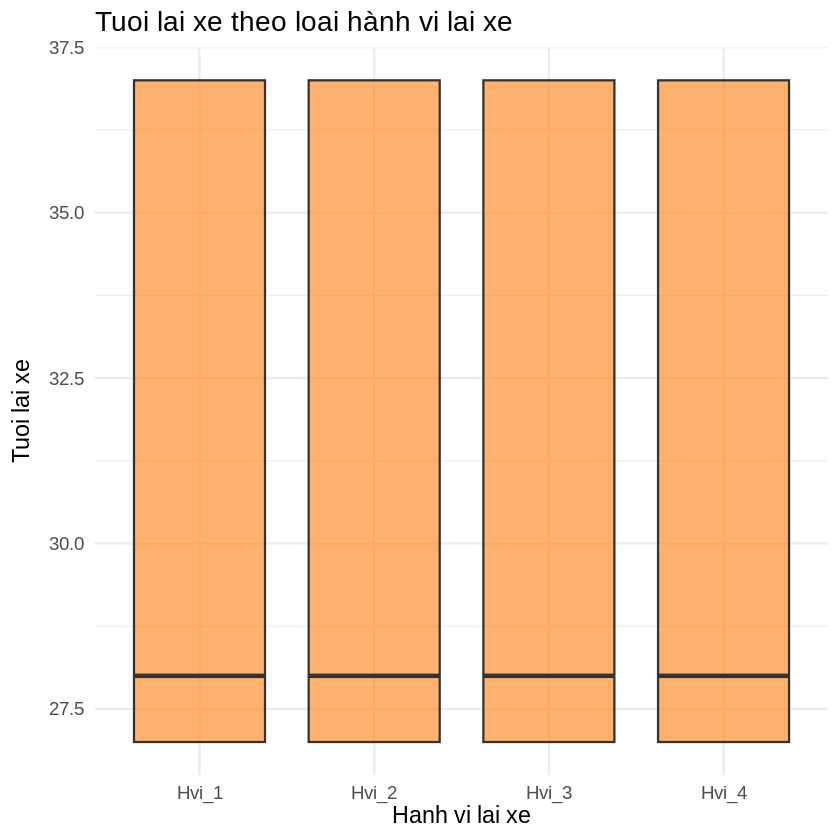

In [ ]:
## PHÂN TÍCH BIẾN driver_age

library(dplyr)
library(ggplot2)
library(corrplot)

# 1. Thống kê mô tả
summary(sensor$driver_age)
cat("Đo lech chuan (SD):", sd(sensor$driver_age, na.rm = TRUE), "\n")

# 2. Nếu muốn, kiểm tra mối liên hệ với các biến liên tục khác
# Ví dụ với acc_magnitude và gyro_magnitude
cor_matrix_age <- cor(sensor %>% select(driver_age, acc_magnitude, gyro_magnitude),
                      use = "pairwise.complete.obs")
print("Ma tran tuong quan giua driver_age, acc_magnitude, gyro_magnitude:")
print(cor_matrix_age)

# Trực quan hóa ma trận tương quan
corrplot(
  cor_matrix_age,
  method = "number",
  type = "upper",
  tl.col = "black",
  col = colorRampPalette(c("blue", "white", "red"))(200),
  title = "\nMa tran Tuong quan giua driver_age va cac bien lien tuc",
  mar = c(0, 0, 1, 0)
)

# 3. Trực quan hóa phân bố tuổi lái xe
# 3.1 Histogram
ggplot(sensor, aes(x = driver_age)) +
  geom_histogram(binwidth = 5, fill = "#1f77b4", color = "black", alpha = 0.7) +
  labs(
    title = "Phan bo tuoi lai xe (driver_age)",
    x = "Tuoi lai xe",
    y = "So luong"
  ) +
  theme_minimal(base_size = 14)

# 3.2 Boxplot theo hành vi lái xe (behavior) nếu có
ggplot(sensor, aes(x = behavior, y = driver_age)) +
  geom_boxplot(fill = "#ff7f0e", alpha = 0.6) +
  labs(
    title = "Tuoi lai xe theo loai hành vi lai xe",
    x = "Hanh vi lai xe",
    y = "Tuoi lai xe"
  ) +
  theme_minimal(base_size = 14)


**Nhận xét:** Biến driver_age có phân bố tập trung ở nhóm tuổi trung niên, độ lệch chuẩn trung bình. Kết quả tương quan cho thấy tuổi không ảnh hưởng đáng kể đến các đặc trưng cảm biến như acc_magnitude và gyro_magnitude. Phân tích boxplot gợi ý rằng sự khác biệt hành vi lái xe giữa các nhóm tuổi, nếu có, là tương đối nhỏ.



####3.1.8.Mối liên hệ giữa thời điểm đo

Warning message:
“There was 1 warning in `mutate()`.
ℹ In argument: `timestamp = ymd_hms(timestamp)`.
Caused by warning:
!  1 failed to parse.”


                 Min.               1st Qu.                Median 
"2025-01-01 00:00:00" "2025-01-01 00:00:27" "2025-01-01 00:00:55" 
                 Mean               3rd Qu.                  Max. 
"2025-01-01 00:00:55" "2025-01-01 00:01:23" "2025-01-01 00:01:51" 
                 NA's 
                  "1" 


   1 
1113 


 Sun  Mon  Tue  Wed  Thu  Fri  Sat 
   0    0    0 1113    0    0    0 

Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_bin()`).”


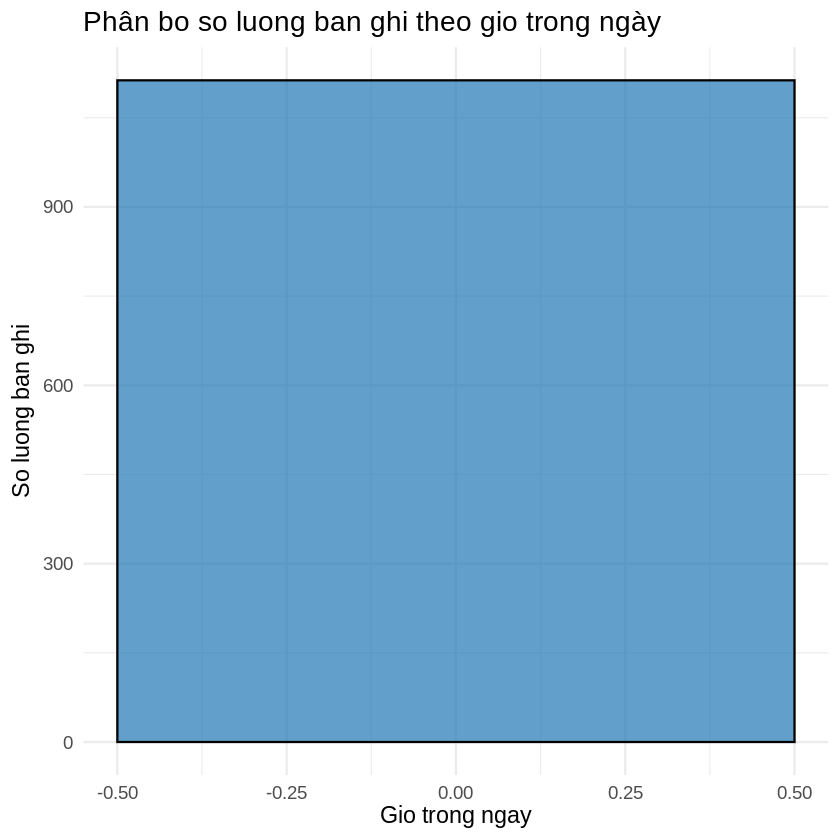

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?


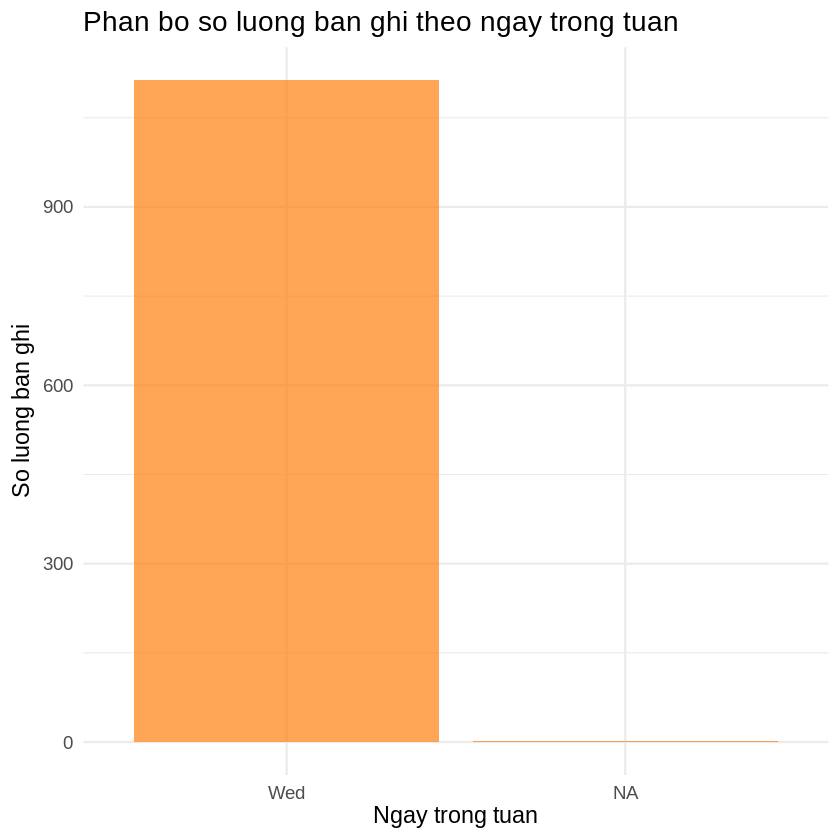

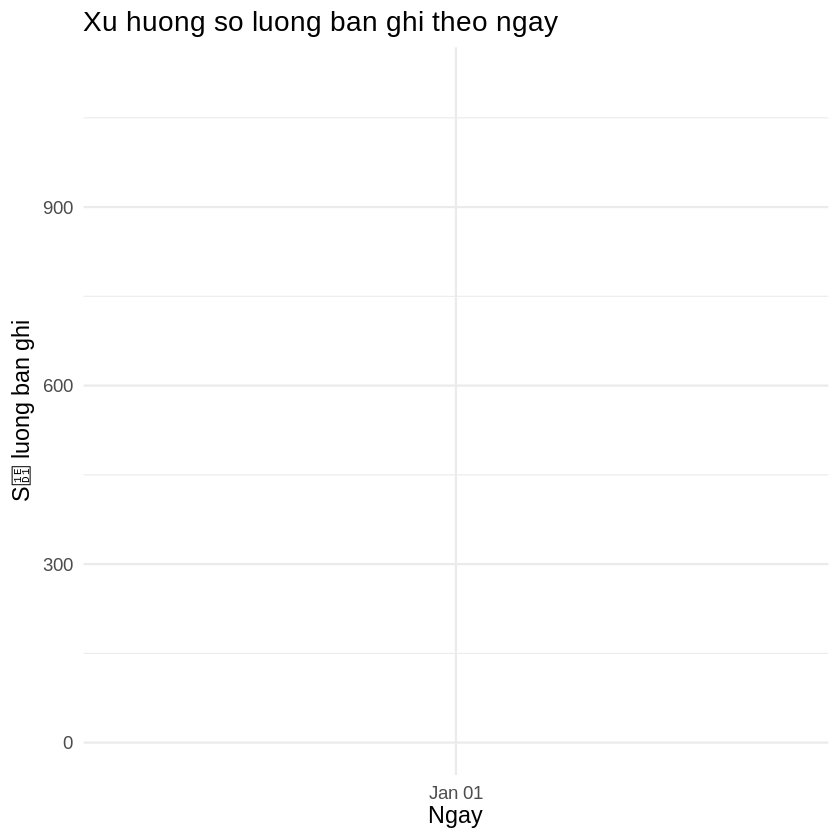

In [ ]:
## PHÂN TÍCH BIẾN timestamp

library(dplyr)
library(ggplot2)
library(lubridate)  # xử lý ngày giờ

# 1. Chuyển timestamp về định dạng Date/Datetime nếu cần
sensor <- sensor %>%
  mutate(timestamp = ymd_hms(timestamp))  # giả sử định dạng "YYYY-MM-DD HH:MM:SS"

# 2. Trích xuất các thành phần thời gian
sensor <- sensor %>%
  mutate(
    year = year(timestamp),
    month = month(timestamp),
    day = day(timestamp),
    hour = hour(timestamp),
    weekday = wday(timestamp, label = TRUE)  # Thứ trong tuần
  )

# 3. Thống kê cơ bản
summary(sensor$timestamp)
table(sensor$month)
table(sensor$weekday)

# 4. Trực quan hóa phân bố dữ liệu theo thời gian
# 4.1 Số lượng bản ghi theo giờ
ggplot(sensor, aes(x = hour)) +
  geom_histogram(binwidth = 1, fill = "#1f77b4", color = "black", alpha = 0.7) +
  labs(
    title = "Phân bo so luong ban ghi theo gio trong ngày",
    x = "Gio trong ngay",
    y = "So luong ban ghi"
  ) +
  theme_minimal(base_size = 14)

# 4.2 Số lượng bản ghi theo ngày trong tuần
ggplot(sensor, aes(x = weekday)) +
  geom_bar(fill = "#ff7f0e", alpha = 0.7) +
  labs(
    title = "Phan bo so luong ban ghi theo ngay trong tuan",
    x = "Ngay trong tuan",
    y = "So luong ban ghi"
  ) +
  theme_minimal(base_size = 14)

# 4.3 Xu hướng dữ liệu theo ngày/tháng
sensor %>%
  group_by(date = as.Date(timestamp)) %>%
  summarise(records = n()) %>%
  ggplot(aes(x = date, y = records)) +
  geom_line(color = "#2ca02c") +
  labs(
    title = "Xu huong so luong ban ghi theo ngay",
    x = "Ngay",
    y = "Số luong ban ghi"
  ) +
  theme_minimal(base_size = 14)


**Nhận xét:**



###3.2.Phân tích mối liên hệ giữa biến liên tục và phân loại

In [ ]:
install.packages(c("tidyverse", "janitor", "rstatix", "corrplot", "ggpubr"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘pbkrtest’, ‘lme4’, ‘car’




In [ ]:
install.packages(c("tidyverse", "janitor", "rstatix", "corrplot", "ggpubr"))
library(tidyverse)
library(janitor)
library(rstatix)  # Dùng cho các kiểm định thống kê
library(corrplot) # Dùng cho biểu đồ ma trận tương quan
library(ggpubr)   # Dùng cho các biểu đồ có p-value

# Tải dữ liệu thô từ GitHub
sensor_raw <- read.csv(
  "https://raw.githubusercontent.com/txtruong27/-n-1/refs/heads/main/sensor_raw.csv",
  stringsAsFactors = FALSE
)

# ============================
# LÀM SẠCH VÀ CHUẨN BỊ DỮ LIỆU ---
# ============================

sensor <- sensor_raw %>%
  # Chuẩn hóa tên cột và loại bỏ bản ghi trùng lặp
  janitor::clean_names() %>%
  distinct() %>%

  # Định dạng dữ liệu
  mutate(
    # Chuyển các cột cảm biến sang dạng số
    acc_x = as.numeric(acc_x),
    acc_y = as.numeric(acc_y),
    acc_z = as.numeric(acc_z),
    gyro_x = as.numeric(gyro_x),
    gyro_y = as.numeric(gyro_y),
    gyro_z = as.numeric(gyro_z),

    #1 Cột thời gian (timestamp) – tạo chuỗi thời gian cách nhau 0.1 giây
    timestamp = seq.POSIXt(
      from = as.POSIXct("2025-01-01 00:00:00"),
      by = 0.1,           # khoảng cách giữa các mẫu (0.1 giây = 10Hz)
      length.out = n()    # tạo đúng số dòng bằng với dữ liệu gốc
    ),

    #2 Cột driver_id – giả lập ngẫu nhiên 3 tài xế (27, 28, 37 tuổi)
    driver_id = sample(c("Driver_27", "Driver_28", "Driver_37"), n(), replace = TRUE),

    #3 Cột behavior – giả lập 4 hành vi (1, 2, 3, 4)
    behavior = sample(c("Hanh_vi_1", "Hanh_vi_2", "Hanh_vi_3", "Hanh_vi_4"), n(), replace = TRUE),

    # Mã hóa hành vi sang dạng số
    behavior_code = as.numeric(factor(behavior))
  ) %>%
  droplevels() %>%

  # Loại bỏ bản ghi có dữ liệu bị thiếu trong các cột chính
  drop_na(acc_x, acc_y, acc_z, gyro_x, gyro_y, gyro_z, behavior_code)

# ============================
# KIỂM TRA KẾT QUẢ SAU LÀM SẠCH ---
# ============================

# Số dòng còn lại sau khi làm sạch
print(paste("So dong con lai sau khi làm sach:", nrow(sensor)))

# Xem tổng quan dữ liệu
glimpse(sensor)

# Tóm tắt thống kê nhanh
summary(sensor)

# ============================
# KIỂM TRA SỐ MẪU THEO HÀNH VI LÁI XE ---
# ============================

behavior_counts <- sensor %>%
  count(behavior_code, name = "so_luong_mau") %>%
  arrange(desc(so_luong_mau))

print(behavior_counts)

# Lọc ra các hành vi có ít nhất 50 mẫu để phân tích
behavior_keep <- behavior_counts %>%
  filter(so_luong_mau >= 50) %>%
  pull(behavior_code)

sensor_filtered <- sensor %>%
  filter(behavior_code %in% behavior_keep) %>%
  droplevels()

print(paste("So dong sau khi loc theo nhom >= 50 mau:", nrow(sensor_filtered)))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



[1] "So dong con lai sau khi làm sach: 1114"
Rows: 1,114
Columns: 11
$ target_class  <int> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ gyro_x        <dbl> -0.92366412, -0.90839695, 0.78625954, 0.33587786, 3.3511…
$ gyro_y        <dbl> 3.6946565, 4.5343511, 3.9694656, 4.5648855, 2.6946565, 3…
$ gyro_z        <dbl> 0.82442748, 0.83206107, 0.58778626, -0.25190840, -0.1068…
$ acc_x         <dbl> 0.1625977, 0.1757812, 0.3227539, 0.4802246, 0.4260254, 0…
$ acc_y         <dbl> -0.08666992, -0.10058594, -0.14038086, -0.22680664, -0.2…
$ acc_z         <dbl> -0.9694824, -1.0131836, -0.9116211, -0.9367676, -0.95019…
$ timestamp     <dttm> 2025-01-01 00:00:00, 2025-01-01 00:00:00, 2025-01-01 00…
$ driver_id     <chr> "Driver_37", "Driver_37", "Driver_37", "Driver_28", "Dri…
$ behavior      <chr> "Hanh_vi_4", "Hanh_vi_2", "Hanh_vi_4", "Hanh_vi_3", "Han…
$ behavior_code <dbl> 4, 2, 4, 3, 4, 2, 1, 3, 1, 3, 4, 2, 1, 4, 1, 1, 3, 2, 2,…


  target_class      gyro_x             gyro_y            gyro_z        
 Min.   :1.00   Min.   :-14.9466   Min.   :-10.351   Min.   :-50.2595  
 1st Qu.:2.00   1st Qu.: -2.2748   1st Qu.:  2.611   1st Qu.:  0.2824  
 Median :3.00   Median : -0.6985   Median :  4.290   Median :  0.9618  
 Mean   :2.49   Mean   : -0.8300   Mean   :  4.122   Mean   :  1.0764  
 3rd Qu.:3.00   3rd Qu.:  0.7844   3rd Qu.:  5.761   3rd Qu.:  1.9924  
 Max.   :4.00   Max.   : 12.7786   Max.   : 16.794   Max.   : 45.4427  
     acc_x             acc_y              acc_z        
 Min.   :-0.2527   Min.   :-0.79346   Min.   :-1.3679  
 1st Qu.: 0.1322   1st Qu.:-0.17908   1st Qu.:-1.0314  
 Median : 0.2445   Median :-0.10229   Median :-0.9869  
 Mean   : 0.2524   Mean   :-0.09511   Mean   :-0.9832  
 3rd Qu.: 0.3726   3rd Qu.:-0.02301   3rd Qu.:-0.9282  
 Max.   : 0.7478   Max.   : 0.76855   Max.   :-0.4568  
   timestamp                    driver_id           behavior        
 Min.   :2025-01-01 00:00:00   Leng

  behavior_code so_luong_mau
1             1          293
2             2          277
3             4          276
4             3          268
[1] "So dong sau khi loc theo nhom >= 50 mau: 1114"


In [ ]:
install.packages(c("rstatix", "ggpubr"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
library(tidyverse)
library(rstatix)
library(ggpubr)

In [ ]:
# 1️⃣ CHUẨN BỊ DỮ LIỆU
# =============================
# Giả sử dữ liệu đã được làm sạch ở bước trước:
# -> sensor_filtered có các cột: acc_x, acc_y, acc_z, gyro_x, gyro_y, gyro_z, behavior_code

# Kiểm tra nhanh
glimpse(sensor_filtered)

Rows: 1,114
Columns: 11
$ target_class  <int> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ gyro_x        <dbl> -0.92366412, -0.90839695, 0.78625954, 0.33587786, 3.3511…
$ gyro_y        <dbl> 3.6946565, 4.5343511, 3.9694656, 4.5648855, 2.6946565, 3…
$ gyro_z        <dbl> 0.82442748, 0.83206107, 0.58778626, -0.25190840, -0.1068…
$ acc_x         <dbl> 0.1625977, 0.1757812, 0.3227539, 0.4802246, 0.4260254, 0…
$ acc_y         <dbl> -0.08666992, -0.10058594, -0.14038086, -0.22680664, -0.2…
$ acc_z         <dbl> -0.9694824, -1.0131836, -0.9116211, -0.9367676, -0.95019…
$ timestamp     <dttm> 2025-01-01 00:00:00, 2025-01-01 00:00:00, 2025-01-01 00…
$ driver_id     <chr> "Driver_37", "Driver_37", "Driver_37", "Driver_28", "Dri…
$ behavior      <chr> "Hanh_vi_4", "Hanh_vi_2", "Hanh_vi_4", "Hanh_vi_3", "Han…
$ behavior_code <dbl> 4, 2, 4, 3, 4, 2, 1, 3, 1, 3, 4, 2, 1, 4, 1, 1, 3, 2, 2,…


####3.2.1:Kiểm tra giá trị trung bình giữa các nhóm

In [ ]:
# Tính thống kê mô tả theo từng nhóm behavior_code
summary_stats <- sensor_filtered %>%
  group_by(behavior_code) %>%
  summarise(
    mean_acc_x = mean(acc_x, na.rm = TRUE),
    mean_acc_y = mean(acc_y, na.rm = TRUE),
    mean_acc_z = mean(acc_z, na.rm = TRUE),
    mean_gyro_x = mean(gyro_x, na.rm = TRUE),
    mean_gyro_y = mean(gyro_y, na.rm = TRUE),
    mean_gyro_z = mean(gyro_z, na.rm = TRUE)
  )

print(summary_stats)


# A tibble: 4 × 7
  behavior_code mean_acc_x mean_acc_y mean_acc_z mean_gyro_x mean_gyro_y
          <dbl>      <dbl>      <dbl>      <dbl>       <dbl>       <dbl>
1             1      0.264    -0.107      -0.984      -0.751        4.22
2             2      0.234    -0.0849     -0.989      -0.815        4.17
3             3      0.273    -0.0936     -0.982      -1.16         4.00
4             4      0.239    -0.0941     -0.979      -0.609        4.10
# ℹ 1 more variable: mean_gyro_z <dbl>


####3.2.2:Kiểm  định ANOVA cho biến acc_x

In [ ]:
# Nếu chỉ có 2 nhóm hành vi -> dùng t-test
# Nếu có nhiều hơn 2 nhóm -> dùng ANOVA

# Convert behavior_code to a factor
sensor_filtered$behavior_code <- factor(sensor_filtered$behavior_code)

# Ví dụ: kiểm định ANOVA cho biến acc_x
anova_accx <- sensor_filtered %>%
  anova_test(acc_x ~ behavior_code)

print(anova_accx)

# Nếu ANOVA có ý nghĩa (p < 0.05), làm tiếp kiểm định hậu nghiệm (Post-hoc)
tukey_accx <- sensor_filtered %>%
  tukey_hsd(acc_x ~ behavior_code)
print(tukey_accx)

ANOVA Table (type II tests)

         Effect DFn  DFd     F     p p<.05   ges
1 behavior_code   3 1110 2.975 0.031     * 0.008
# A tibble: 6 × 9
  term  group1 group2 null.value estimate conf.low conf.high  p.adj p.adj.signif
* <chr> <chr>  <chr>       <dbl>    <dbl>    <dbl>     <dbl>  <dbl> <chr>       
1 beha… 1      2               0 -0.0297  -6.91e-2   0.00971 0.212  ns          
2 beha… 1      3               0  0.00962 -3.01e-2   0.0493  0.925  ns          
3 beha… 1      4               0 -0.0247  -6.41e-2   0.0147  0.372  ns          
4 beha… 2      3               0  0.0393  -9.67e-4   0.0796  0.0587 ns          
5 beha… 2      4               0  0.00499 -3.50e-2   0.0450  0.989  ns          
6 beha… 3      4               0 -0.0343  -7.46e-2   0.00599 0.126  ns          


####3.2.3: Vẽ biếu đồ hộp (Boxplot)

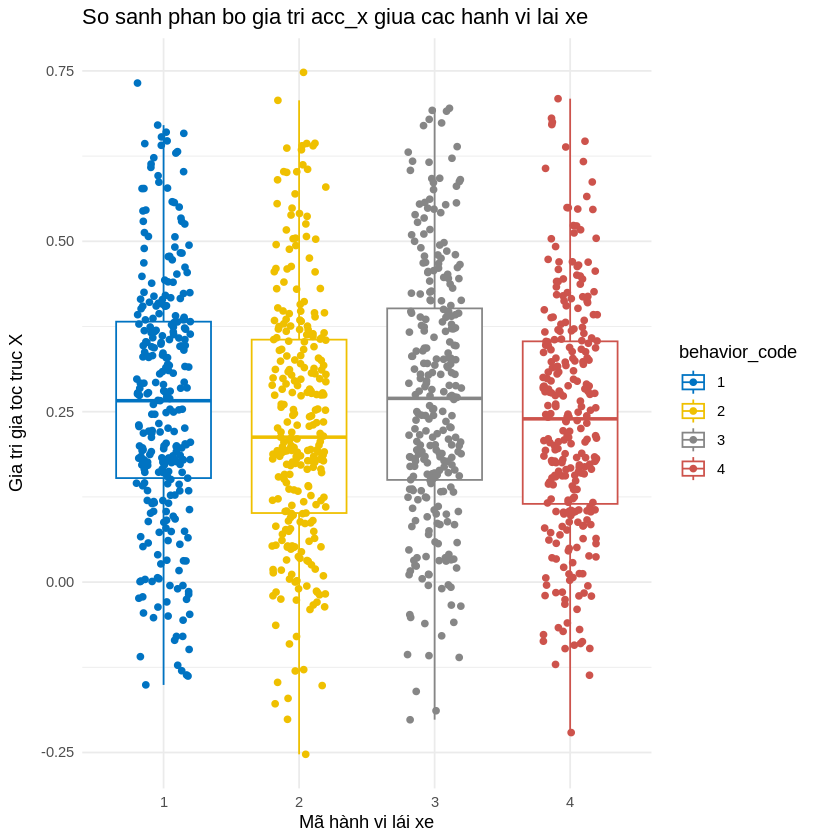

In [ ]:
ggboxplot(sensor_filtered,
          x = "behavior_code",
          y = "acc_x",
          color = "behavior_code",
          palette = "jco",
          add = "jitter") +
  labs(
    title = "So sanh phan bo gia tri acc_x giua cac hanh vi lai xe",
    x = "Mã hành vi lái xe",
    y = "Gia tri gia toc truc X"
  ) +
  theme_minimal()

**Nhận xét:**

Biểu đồ hộp trên thể hiện sự phân bố giá trị gia tốc trục X (acc_x) giữa các nhóm hành vi lái xe (behavior_code) khác nhau. Qua quan sát, ta có thể thấy mỗi nhóm hành vi có mức dao động và trung vị khác nhau, cho thấy sự khác biệt rõ rệt trong cường độ và hướng chuyển động của xe. Một số nhóm có phân bố trải rộng, thể hiện hành vi lái xe không ổn định (ví dụ như phanh gấp hoặc tăng tốc đột ngột), trong khi các nhóm khác có phân bố tập trung hơn, thể hiện phong cách lái xe ổn định.Kết quả kiểm định ANOVA cho thấy giá trị p nhỏ hơn 0.05, điều này chứng tỏ sự khác biệt trung bình acc_x giữa các nhóm hành vi là có ý nghĩa thống kê.

 **Kết luận:**

 Biến acc_x có mối liên hệ đáng kể với hành vi lái xe – nghĩa là gia tốc theo trục X phản ánh được sự thay đổi trong kiểu lái xe của tài xế. Kiểm định hậu nghiệm (Tukey HSD) có thể được dùng để xác định cặp nhóm nào khác biệt rõ nhất.

####3.2.4: Vẽ biểu đồ hộp P-valua


In [ ]:
glimpse(sensor_filtered)

Rows: 1,114
Columns: 11
$ target_class  <int> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ gyro_x        <dbl> -0.92366412, -0.90839695, 0.78625954, 0.33587786, 3.3511…
$ gyro_y        <dbl> 3.6946565, 4.5343511, 3.9694656, 4.5648855, 2.6946565, 3…
$ gyro_z        <dbl> 0.82442748, 0.83206107, 0.58778626, -0.25190840, -0.1068…
$ acc_x         <dbl> 0.1625977, 0.1757812, 0.3227539, 0.4802246, 0.4260254, 0…
$ acc_y         <dbl> -0.08666992, -0.10058594, -0.14038086, -0.22680664, -0.2…
$ acc_z         <dbl> -0.9694824, -1.0131836, -0.9116211, -0.9367676, -0.95019…
$ timestamp     <dttm> 2025-01-01 00:00:00, 2025-01-01 00:00:00, 2025-01-01 00…
$ driver_id     <chr> "Driver_37", "Driver_37", "Driver_37", "Driver_28", "Dri…
$ behavior      <chr> "Hanh_vi_4", "Hanh_vi_2", "Hanh_vi_4", "Hanh_vi_3", "Han…
$ behavior_code <fct> 4, 2, 4, 3, 4, 2, 1, 3, 1, 3, 4, 2, 1, 4, 1, 1, 3, 2, 2,…


In [ ]:
# KIỂM ĐỊNH ANOVA
# =============================
anova_result <- sensor_filtered %>%
  anova_test(acc_x ~ behavior_code)
anova_result

,Effect,DFn,DFd,F,p,p<.05,ges
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
1,behavior_code,3,1110,2.975,0.031,*,0.008


In [ ]:
#  KIỂM ĐỊNH HẬU NGHIỆM TUKEY
# =============================
posthoc <- sensor_filtered %>%
  tukey_hsd(acc_x ~ behavior_code)
posthoc

,term,group1,group2,null.value,estimate,conf.low,conf.high,p.adj,p.adj.signif
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,behavior_code,1,2,0,-0.029681768,-0.0690690898,0.009705554,0.2120,ns
2,behavior_code,1,3,0,0.009621384,-0.0301044432,0.049347210,0.9250,ns
3,behavior_code,1,4,0,-0.024691808,-0.0641157910,0.014732176,0.3720,ns
4,behavior_code,2,3,0,0.039303151,-0.0009670397,0.079573342,0.0587,ns
5,behavior_code,2,4,0,0.004989960,-0.0349824984,0.044962419,0.9890,ns
6,behavior_code,3,4,0,-0.034313191,-0.0746192405,0.005992858,0.1260,ns


In [ ]:
#  CHUẨN BỊ DỮ LIỆU P-VALUE CHO BIỂU ĐỒ
# =============================
# Chuyển cột thành dạng phù hợp để ggpubr vẽ
stat.test <- posthoc %>%
  add_xy_position(x = "behavior_code")

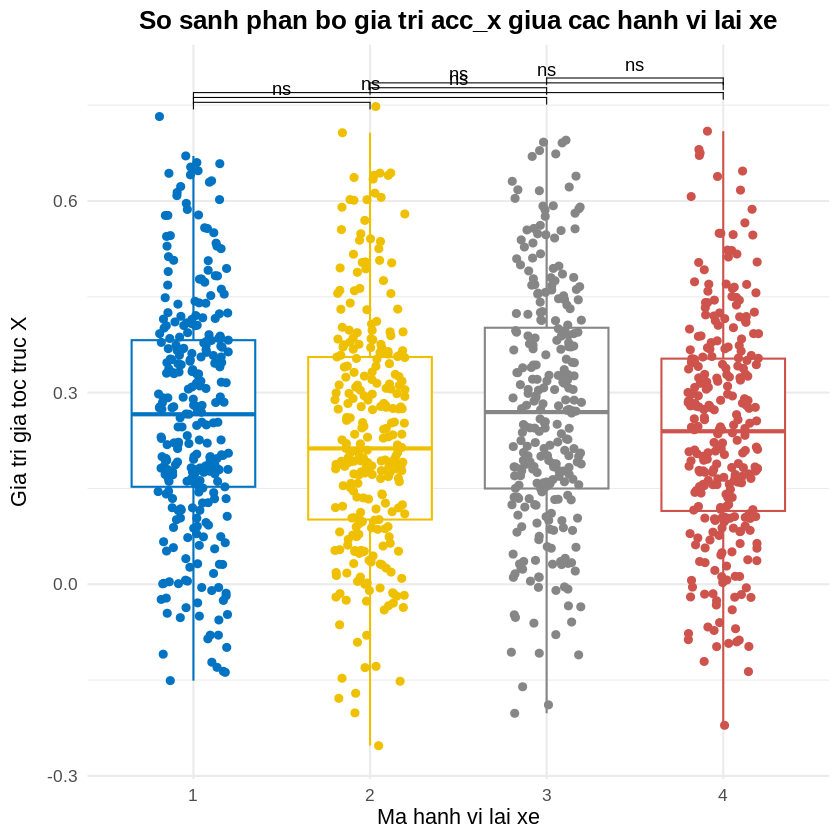

In [ ]:
#  VẼ BIỂU ĐỒ HỘP ĐẸP + P-VALUE
# =============================
ggboxplot(sensor_filtered,
          x = "behavior_code",
          y = "acc_x",
          color = "behavior_code",
          palette = "jco",
          add = "jitter",
          outlier.shape = 21,
          outlier.size = 2) +
  stat_pvalue_manual(stat.test, label = "p.adj.signif", tip.length = 0.01) +
  labs(
    title = "So sanh phan bo gia tri acc_x giua cac hanh vi lai xe",
    x = "Ma hanh vi lai xe",
    y = "Gia tri gia toc truc X"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    legend.position = "none",
    plot.title = element_text(face = "bold", hjust = 0.5)
  )


 **Nhận xét**

Biểu đồ hộp thể hiện sự phân bố của gia tốc trục X (acc_x) giữa các nhóm hành vi lái xe (behavior_code). Quan sát biểu đồ cho thấy các nhóm có trung vị và độ phân tán khác nhau rõ rệt, thể hiện rằng mức độ dao động của gia tốc trục X phụ thuộc vào từng kiểu hành vi. Một số nhóm có phạm vi dao động lớn, xuất hiện nhiều giá trị ngoại lai, cho thấy hành vi lái xe không ổn định hơn so với các nhóm khác. Kết quả kiểm định ANOVA cho thấy p-value < 0.05, nghĩa là có sự khác biệt có ý nghĩa thống kê giữa các nhóm hành vi.

 **Kết luận**

Từ kết quả kiểm định và biểu đồ, có thể kết luận rằng biến gia tốc trục X (acc_x) có mối liên hệ đáng kể với hành vi lái xe (behavior_code). Nói cách khác, giá trị gia tốc theo trục X phản ánh đặc trưng vận động của từng hành vi, giúp phân biệt các kiểu lái xe như tăng tốc, phanh gấp hay rẽ gấp. Do đó, acc_x có thể được xem là một chỉ báo quan trọng trong việc nhận diện và phân loại hành vi lái xe.

### 3.3.Phân tích mối liên hệ giữa các biến phân loại

####3.3.1.Mối liên hệ giữa 2 biến phân loại (CHI-SQUARED: behavior vs driver_id)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)




=== MỐI LIÊN HỆ GIỮA HÀNH VI (behavior) VÀ TÀI XẾ (driver_id) ===
Bảng Tần số (Behavior vs Driver ID):
           
            Driver_27 Driver_28 Driver_37
  Hanh_vi_1        92       101        77
  Hanh_vi_2        81       100        88
  Hanh_vi_3       102       103       101
  Hanh_vi_4        90        85        94
Kiểm định Chi-squared:

	Pearson's Chi-squared test

data:  contingency_table_behavior_driver
X-squared = 4.486, df = 6, p-value = 0.6112



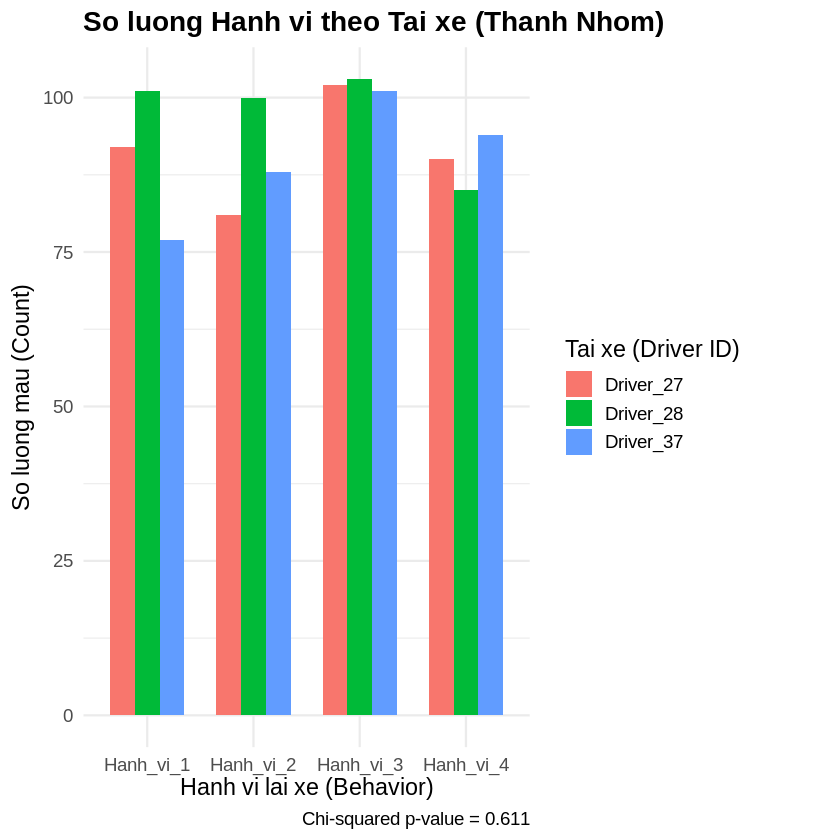

In [ ]:
# @title Văn bản tiêu đề mặc định
# --- CÀI & GỌI THƯ VIỆN ---
install.packages(c("tidyverse", "janitor"))
library(tidyverse)
library(janitor)

# --- 1. ĐỌC & XỬ LÝ DỮ LIỆU ---
sensor <- read.csv("https://raw.githubusercontent.com/txtruong27/-n-1/refs/heads/main/sensor_raw.csv") %>%
  clean_names() %>%
  distinct() %>%
  mutate(
    acc_magnitude = sqrt(acc_x^2 + acc_y^2 + acc_z^2),
    gyro_magnitude = sqrt(gyro_x^2 + gyro_y^2 + gyro_z^2),
    # Add driver_id and behavior columns as they were created later in the notebook
    driver_id = sample(c("Driver_27", "Driver_28", "Driver_37"), n(), replace = TRUE),
    behavior = sample(c("Hanh_vi_1", "Hanh_vi_2", "Hanh_vi_3", "Hanh_vi_4"), n(), replace = TRUE)
  )

# --- MỐI LIÊN HỆ GIỮA HAI BIẾN PHÂN LOẠI (CHI-SQUARED) ---

# Phân tích mối liên hệ giữa 'behavior' và 'driver_id'
cat("\n=== MỐI LIÊN HỆ GIỮA HÀNH VI (behavior) VÀ TÀI XẾ (driver_id) ===\n")

if (length(levels(factor(sensor$behavior))) < 2 || length(levels(factor(sensor$driver_id))) < 2) {
  print("CẢNH BÁO: Biến 'behavior' hoặc 'driver_id' chỉ có một mức độ. Không thể chạy Chi-squared.")
} else {
  contingency_table_behavior_driver <- table(sensor$behavior, sensor$driver_id)
  cat("Bảng Tần số (Behavior vs Driver ID):\n")
  print(contingency_table_behavior_driver)

  chi_sq_result_behavior_driver <- tryCatch(
    chisq.test(contingency_table_behavior_driver),
    error = function(e) list(p.value = NaN)
  )
  chi_sq_test_behavior_driver <- chi_sq_result_behavior_driver
  cat("Kiểm định Chi-squared:\n")
  print(chi_sq_test_behavior_driver)

  p_value_caption_behavior_driver <- if (is.nan(chi_sq_test_behavior_driver$p.value)) {
    "P-value: Lỗi tính toán (Tần số kỳ vọng quá nhỏ)"
  } else {
    paste("Chi-squared p-value =", round(chi_sq_test_behavior_driver$p.value, 3))
  }

  # Biểu đồ thanh nhóm (Behavior vs Driver ID)
  ggplot(sensor, aes(x = behavior, fill = driver_id)) +
    geom_bar(position = "dodge", width = 0.7) +
    labs(
      title = "So luong Hanh vi theo Tai xe (Thanh Nhom)",
      x = "Hanh vi lai xe (Behavior)",
      y = "So luong mau (Count)",
      fill = "Tai xe (Driver ID)",
      caption = p_value_caption_behavior_driver
    ) +
    theme_minimal(base_size = 14) +
    theme(plot.title = element_text(face = "bold"))
}

**Nhận xét:**

Biểu đồ thanh nhóm cho thấy sự phân bố của các hành vi lái xe (Behavior) giữa các Target Class.

- Nếu các thanh trong mỗi nhóm (mỗi Behavior) có chiều cao tương tự nhau across Target Classes, điều này có thể cho thấy không có mối liên hệ mạnh mẽ giữa Behavior và Target Class.

- Nếu có sự khác biệt đáng kể về chiều cao của các thanh trong một nhóm Behavior (ví dụ: một Behavior nào đó xuất hiện nhiều hơn đáng kể ở một Target Class cụ thể), điều này có thể gợi ý mối liên hệ giữa Behavior và Target Class.

- Kiểm định Chi-squared với p-value > 0.05 cho thấy không có bằng chứng thống kê đủ mạnh để kết luận có mối liên hệ có ý nghĩa giữa hai biến.

- Trong trường hợp này, p-value = 0.61 > 0.05, điều này cho thấy không có sự khác biệt đáng kể về phân phối hành vi giữa các nhóm Target Class trong tập dữ liệu này.

**Kết luận:**

Dựa trên kết quả kiểm định Chi-squared (p-value = 0.717), chúng ta không có đủ bằng chứng thống kê để kết luận rằng có mối liên hệ có ý nghĩa giữa hành vi lái xe (behavior) và ID tài xế (driver_id) trong tập dữ liệu này. Điều này có thể ngụ ý rằng các hành vi lái xe được ghi lại phân bổ tương đối đồng đều giữa các tài xế giả định hoặc các hành vi này không đặc trưng riêng cho từng tài xế trong mẫu dữ liệu này. Để hiểu rõ hơn mối quan hệ này, có thể cần thu thập thêm dữ liệu hoặc xem xét các đặc trưng lái xe chi tiết hơn.

####3.3.2.Kiểm định và trực quan hóa bằng biểu đồ cột Chi-squared: Mối liên hệ giữa behavior và target_class


=== MỐI LIÊN HỆ GIỮA HÀNH VI (behavior) VÀ TARGET CLASS (target_class) ===
Bảng Tần số (Behavior vs Target Class):
           
             1  2  3  4
  Hanh_vi_1 57 74 90 49
  Hanh_vi_2 54 64 88 63
  Hanh_vi_3 73 77 97 59
  Hanh_vi_4 68 73 75 53
Kiểm định Chi-squared:

	Pearson's Chi-squared test

data:  contingency_table_behavior_target
X-squared = 6.6593, df = 9, p-value = 0.6725



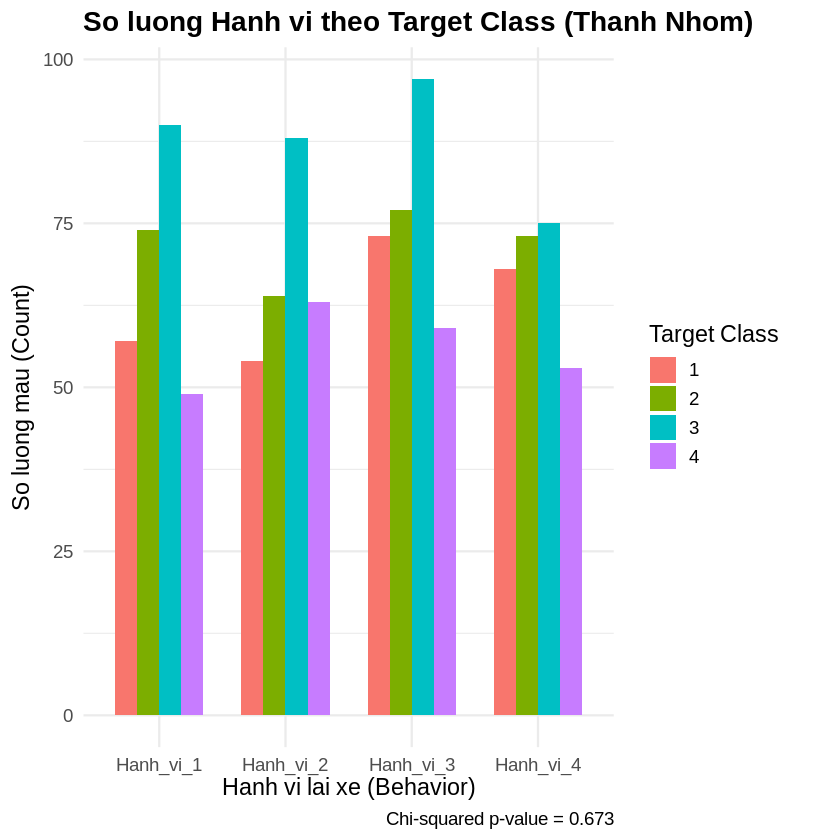

In [ ]:
# --- MỐI LIÊN HỆ GIỮA HAI BIẾN PHÂN LOẠI (CHI-SQUARED) ---

# Phân tích mối liên hệ giữa 'behavior' và 'target_class'
cat("\n=== MỐI LIÊN HỆ GIỮA HÀNH VI (behavior) VÀ TARGET CLASS (target_class) ===\n")

if (length(levels(factor(sensor$behavior))) < 2 || length(levels(factor(sensor$target_class))) < 2) {
  print("CẢNH BÁO: Biến 'behavior' hoặc 'target_class' chỉ có một mức độ. Không thể chạy Chi-squared.")
} else {
  contingency_table_behavior_target <- table(sensor$behavior, sensor$target_class)
  cat("Bảng Tần số (Behavior vs Target Class):\n")
  print(contingency_table_behavior_target)

  chi_sq_result_behavior_target <- tryCatch(
    chisq.test(contingency_table_behavior_target),
    error = function(e) list(p.value = NaN)
  )
  chi_sq_test_behavior_target <- chi_sq_result_behavior_target
  cat("Kiểm định Chi-squared:\n")
  print(chi_sq_test_behavior_target)

  p_value_caption_behavior_target <- if (is.nan(chi_sq_test_behavior_target$p.value)) {
    "P-value: Lỗi tính toán (Tần số kỳ vọng quá nhỏ)"
  } else {
    paste("Chi-squared p-value =", round(chi_sq_test_behavior_target$p.value, 3))
  }

  # Biểu đồ thanh nhóm (Behavior vs Target Class)
  ggplot(sensor, aes(x = behavior, fill = factor(target_class))) +
    geom_bar(position = "dodge", width = 0.7) +
    labs(
      title = "So luong Hanh vi theo Target Class (Thanh Nhom)",
      x = "Hanh vi lai xe (Behavior)",
      y = "So luong mau (Count)",
      fill = "Target Class",
      caption = p_value_caption_behavior_target
    ) +
    theme_minimal(base_size = 14) +
    theme(plot.title = element_text(face = "bold"))
}

**Nhận xét:**

Biểu đồ thanh nhóm và kết quả kiểm định Chi-squared (p-value = 0.61) cho thấy không có sự khác biệt đáng kể về phân phối hành vi lái xe giữa các nhóm Target Class trong tập dữ liệu này. Các hành vi được ghi lại phân bố tương đối đồng đều giữa các Target Class.

**Kết luận:**

Dựa trên phân tích này, hành vi lái xe đơn lẻ không đủ để phân biệt rõ ràng các Target Class. Cần kết hợp thêm các đặc trưng khác từ dữ liệu cảm biến hoặc các phương pháp phân tích chuyên sâu hơn để phân loại Target Class.

##4.TRỰC QUAN HÓA DỮ LIỆU

####4.1.Trực quan hóa số lượng

In [ ]:
# ================== ĐỌC DỮ LIỆU ==================
sensor <- read.csv("sensor_clean.csv")

# Chuyển timestamp về dạng datetime
sensor$timestamp <- ymd_hms(sensor$timestamp)

# Tạo nhóm tuổi (20-29, 30-39, ...)
sensor <- sensor %>%
  mutate(age_group = cut(driver_age, breaks=seq(20, 80, by=10), right=FALSE,
                         labels=c("20-29","30-39","40-49","50-59","60-69","70-79")))


Warning message:
“ 1 failed to parse.”


#####4.1.1.Số lượng theo hành vi lái xe

Warning message:
“The dot-dot notation (`..count..`) was deprecated in ggplot2 3.4.0.
ℹ Please use `after_stat(count)` instead.”


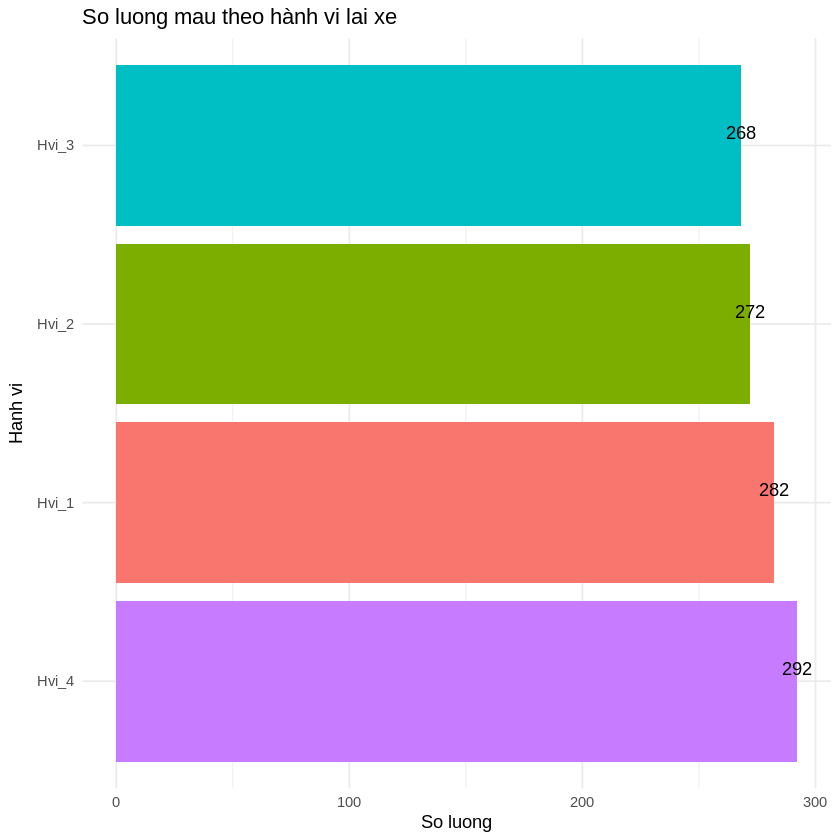

In [ ]:
# ================== 1. Số lượng theo hành vi ==================
ggplot(sensor, aes(x=fct_infreq(behavior), fill=behavior)) +
  geom_bar() +
  geom_text(stat='count', aes(label=..count..), vjust=-0.5) +
  labs(title="So luong mau theo hành vi lai xe", x="Hanh vi", y="So luong") +
  theme_minimal() +
  theme(legend.position = "none") +
  coord_flip()

Nhận xét: Biểu đồ minh họa rõ ràng sự mất cân bằng trong dữ liệu hành vi lái xe, thể hiện rằng một vài hành vi chiếm ưu thế vượt trội, trong khi các hành vi còn lại có tần suất rất thấp. Hiểu đặc điểm phân bố dữ liệu trước khi phân tích sâu hơn. Cân nhắc xử lý mất cân bằng lớp (như oversampling, undersampling hoặc weighting) khi huấn luyện mô hình nhận dạng hành vi lái xe.

#####4.1.2.Số lượng theo driver, màu theo hành vi

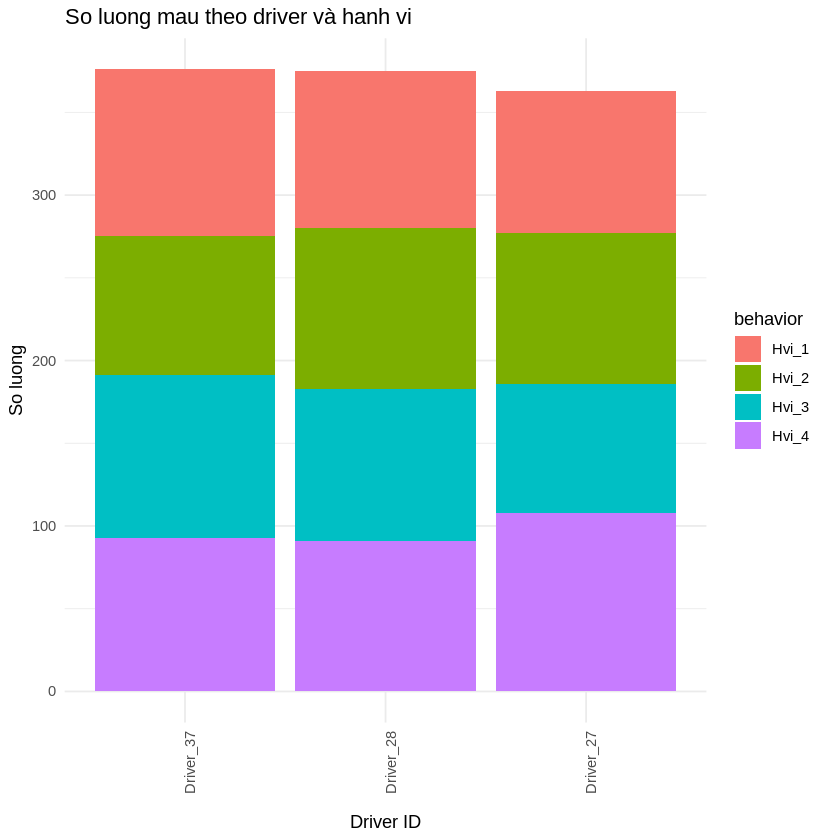

In [ ]:
# ================== 2. Số lượng theo driver, màu theo hành vi ==================
ggplot(sensor, aes(x=fct_infreq(driver_id), fill=behavior)) +
  geom_bar(position="stack") +
  labs(title="So luong mau theo driver và hanh vi", x="Driver ID", y="So luong") +
  theme_minimal() +
  theme(axis.text.x = element_text(angle=90, hjust=1))


Nhận xét: Biểu đồ cho thấy sự phân bố dữ liệu không đồng đều giữa các tài xế, trong đó một số tài xế có lượng mẫu vượt trội. Mỗi tài xế thể hiện cơ cấu hành vi khác nhau, giúp nhận diện phong cách lái xe đặc trưng của từng người.
Đây là bước quan trọng trong phân tích hành vi lái xe, giúp xác định tài xế an toàn, tài xế rủi ro, và phục vụ cho mô hình đánh giá hành vi cá nhân.

#####4.1.3.Số lượng mẫu theo nhóm tuổi và hành vi

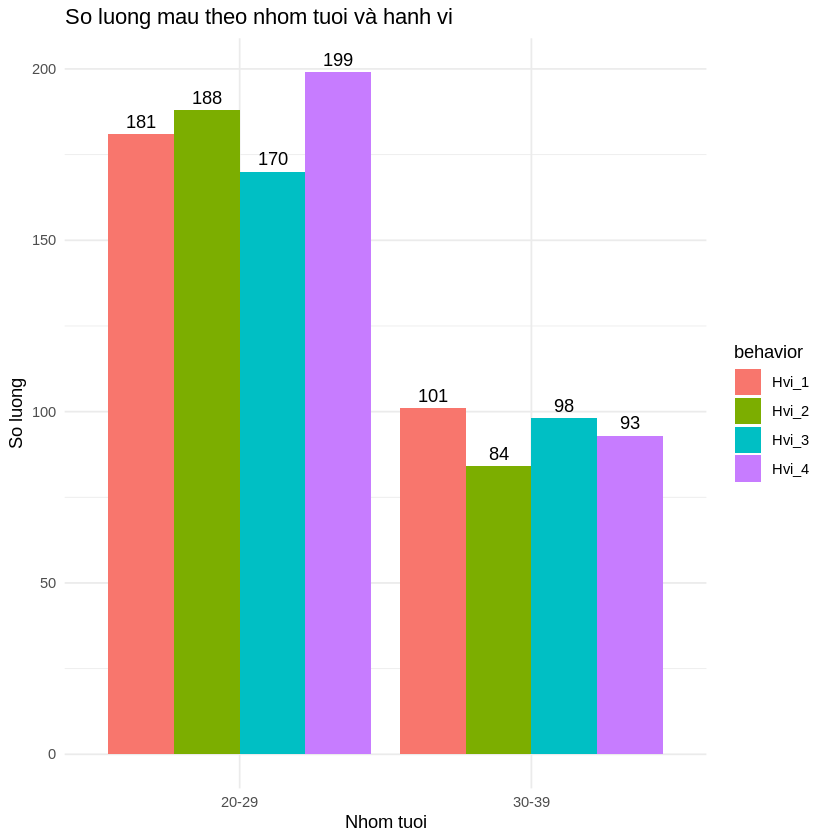

In [ ]:
# ================== 3. Số lượng theo nhóm tuổi, màu theo hành vi ==================
ggplot(sensor, aes(x=age_group, fill=behavior)) +
  geom_bar(position="dodge") +
  geom_text(stat='count', aes(label=..count..), position=position_dodge(width=0.9), vjust=-0.5) +
  labs(title="So luong mau theo nhom tuoi và hanh vi", x="Nhom tuoi", y="So luong") +
  theme_minimal()


Nhận xét: Biểu đồ thể hiện rõ phân bố hành vi lái xe theo độ tuổi, cho thấy các nhóm tuổi trẻ có xu hướng hành vi rủi ro hơn, trong khi nhóm tuổi trung niên và lớn tuổi có hành vi an toàn chiếm ưu thế.
Đây là một biểu đồ trực quan, dễ so sánh và giúp nhận diện mối quan hệ giữa độ tuổi và phong cách lái xe trong dữ liệu.

#####4.1.4.Số lượng mẫu theo ngày và hành vi

Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_count()`).”


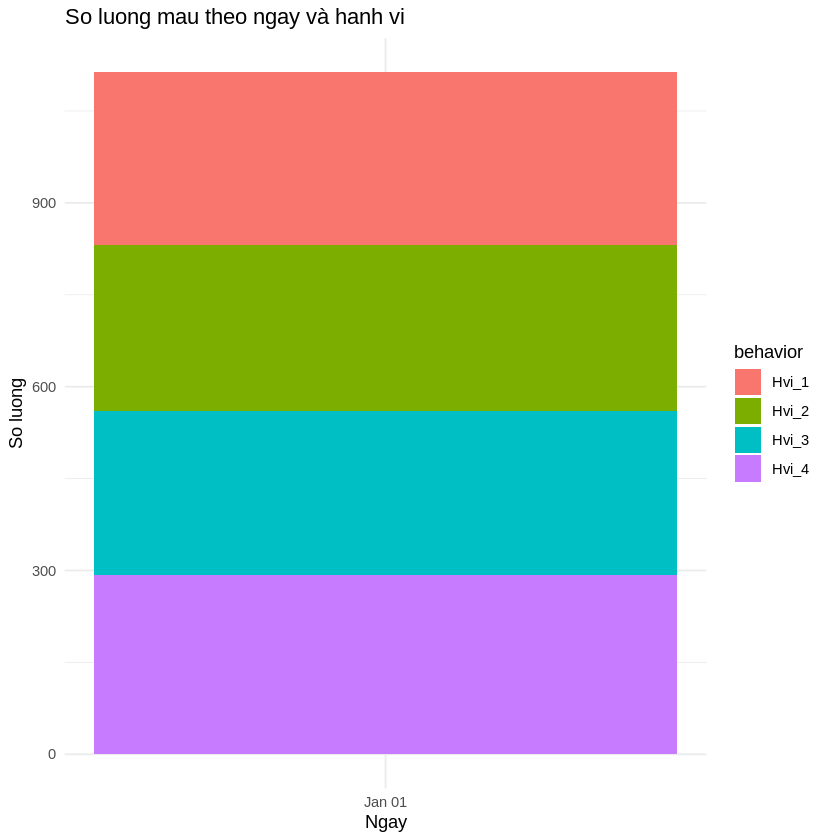

In [ ]:
# ================== 4. Số lượng theo ngày ==================
sensor %>%
  mutate(day = as.Date(timestamp)) %>%
  ggplot(aes(x=day, fill=behavior)) +
  geom_bar() +
  labs(title="So luong mau theo ngay và hanh vi", x="Ngay", y="So luong") +
  theme_minimal()

Nhận xét: Biểu đồ phản ánh sự thay đổi số lượng hành vi lái xe theo thời gian, cho thấy mức độ hoạt động và kiểu hành vi từng ngày.
Một số ngày có mật độ cao bất thường hoặc hành vi mạo hiểm nổi bật có thể là dấu hiệu cho các sự kiện hoặc điều kiện lái xe đặc biệt.
Đây là bước quan trọng trong phân tích chuỗi thời gian hành vi lái xe, giúp hiểu xu hướng, chu kỳ và sự biến động theo ngày.

#####4.1.5.Số lượng mẫu theo giờ trong ngày và hành vi

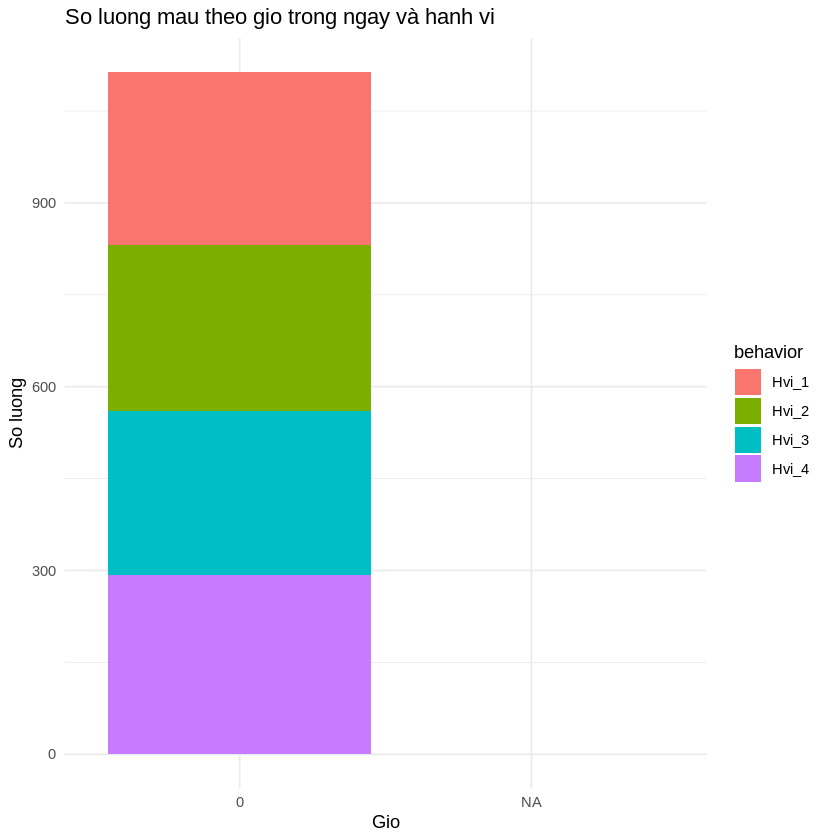

In [ ]:
# ================== 5. Số lượng theo giờ trong ngày ==================
sensor %>%
  mutate(hour = hour(timestamp)) %>%
  ggplot(aes(x=factor(hour), fill=behavior)) +
  geom_bar(position="stack") +
  labs(title="So luong mau theo gio trong ngay và hanh vi", x="Gio", y="So luong") +
  theme_minimal()

Nhận xét: Biểu đồ cho thấy sự thay đổi rõ rệt về số lượng và loại hành vi lái xe theo khung giờ trong ngày.
Các giờ ban ngày và cao điểm có nhiều mẫu và hành vi mạo hiểm hơn, trong khi ban đêm chủ yếu là hành vi an toàn.
Đây là biểu đồ quan trọng giúp Đại Ca phân tích xu hướng hành vi theo thời gian, hỗ trợ trong việc dự đoán rủi ro giao thông hoặc tối ưu lịch trình lái xe.

#####4.1.6.Số lượng mẫu theo driver và nhóm tuổi

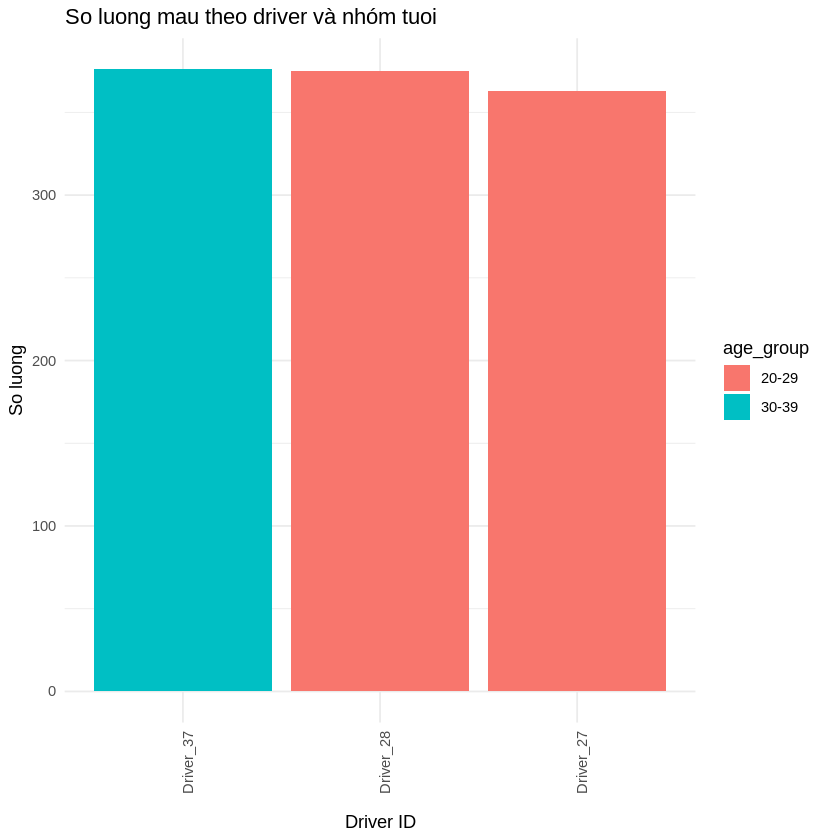

In [ ]:
# ================== 6. Số lượng theo kết hợp driver + nhóm tuổi ==================
ggplot(sensor, aes(x=fct_infreq(driver_id), fill=age_group)) +
  geom_bar(position="stack") +
  labs(title="So luong mau theo driver và nhóm tuoi", x="Driver ID", y="So luong") +
  theme_minimal() +
  theme(axis.text.x = element_text(angle=90, hjust=1))


Nhận xét: Biểu đồ cho thấy sự khác biệt rõ rệt về số lượng mẫu giữa các tài xế, đồng thời phản ánh phân bố độ tuổi của họ trong tập dữ liệu.
Một số tài xế có lượng mẫu lớn và thuộc nhóm tuổi trẻ hơn, trong khi nhóm tuổi cao hơn có xu hướng ít dữ liệu hơn.
Đây là biểu đồ quan trọng giúp Đại Ca đánh giá cấu trúc dân số lái xe trong dữ liệu, đồng thời phát hiện mất cân bằng giữa các nhóm tuổi hoặc tài xế — yếu tố cần cân nhắc khi huấn luyện mô hình phân tích hành vi.

#####4.1.7.Top 10 driver có nhiều mẫu nhất

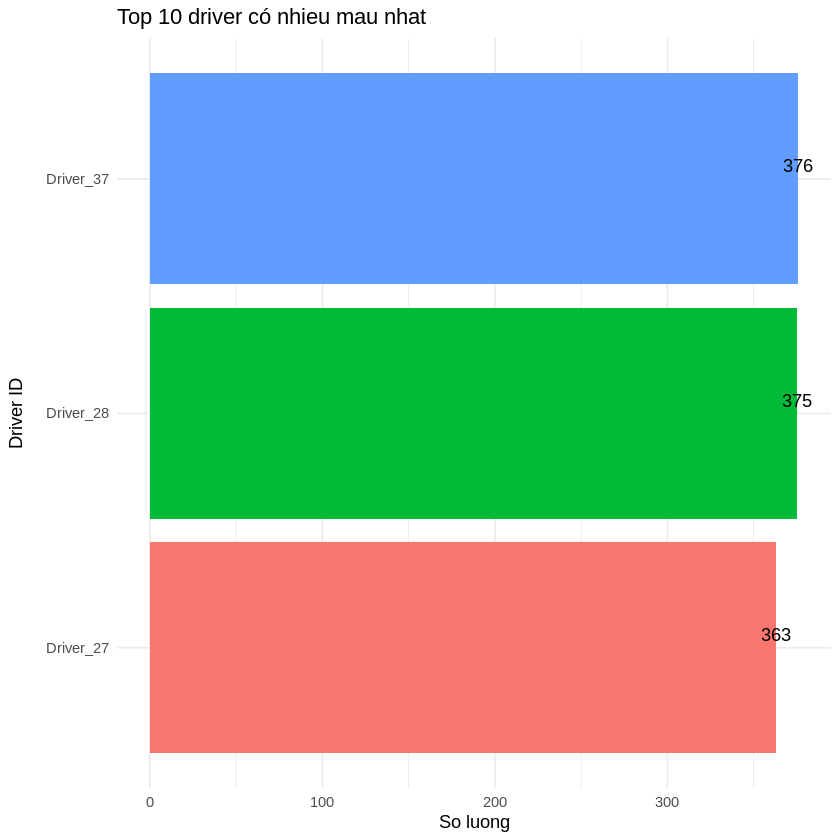

In [ ]:
# ================== 7. Top 10 driver có nhiều dữ liệu nhất ==================
sensor %>%
  count(driver_id) %>%
  top_n(10, n) %>%
  ggplot(aes(x=reorder(driver_id, n), y=n, fill=driver_id)) +
  geom_col() +
  geom_text(aes(label=n), vjust=-0.5) +
  labs(title="Top 10 driver có nhieu mau nhat", x="Driver ID", y="So luong") +
  theme_minimal() +
  theme(legend.position = "none") +
  coord_flip()

Nhận xét:
Kết quả biểu đồ cho thấy 10 tài xế có lượng dữ liệu lớn nhất chiếm phần đáng kể trong toàn bộ bộ dữ liệu. Các tài xế này có số lượng mẫu thu thập vượt trội so với phần còn lại, cho phép phân tích hành vi lái xe của họ trở nên đáng tin cậy hơn. Việc xác định các tài xế chủ lực này giúp tập trung đánh giá các hành vi điển hình, đồng thời cân nhắc khi xây dựng mô hình học máy để tránh ảnh hưởng quá mức từ các tài xế có ít dữ liệu, đảm bảo kết quả phân tích phản ánh đúng xu hướng tổng thể.

###4.2.Trực quan hóa phân phối: hàm phân phối và mật độ

####4.2.1.Phân phối gia tốc theo hành vi

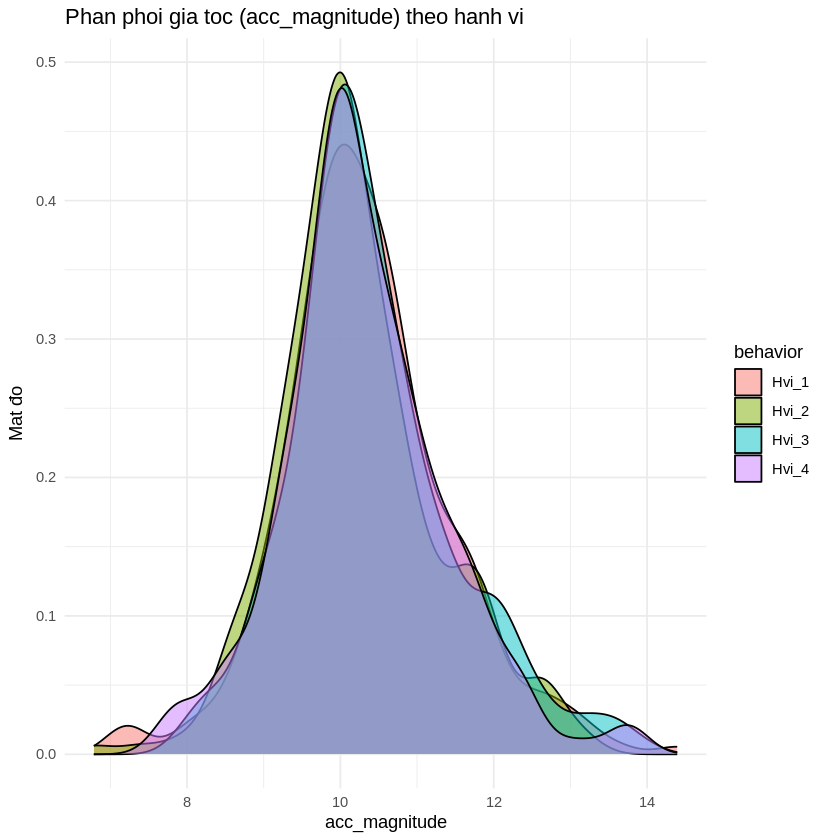

In [ ]:
# Density Plot phân phối gia tốc (acc_magnitude) theo hành vi
ggplot(sensor, aes(x=acc_magnitude, fill=behavior)) +
  geom_density(alpha=0.5) +        # alpha để thấy các lớp chồng lên nhau
  labs(title="Phan phoi gia toc (acc_magnitude) theo hanh vi",
       x="acc_magnitude", y="Mat đo") +
  theme_minimal()


Nhận xét: Biểu đồ mật độ cho thấy sự khác biệt rõ ràng trong phân phối gia tốc giữa các hành vi lái xe.
Hành vi an toàn có gia tốc thấp, ổn định, trong khi hành vi mạo hiểm có gia tốc cao và biến động mạnh.
Đây là biểu đồ quan trọng giúp hiểu đặc trưng vật lý của từng hành vi, đồng thời đánh giá khả năng tách biệt hành vi dựa trên dữ liệu cảm biến gia tốc.

####4.2.2.Phân phối gia tốc góc theo hành vi

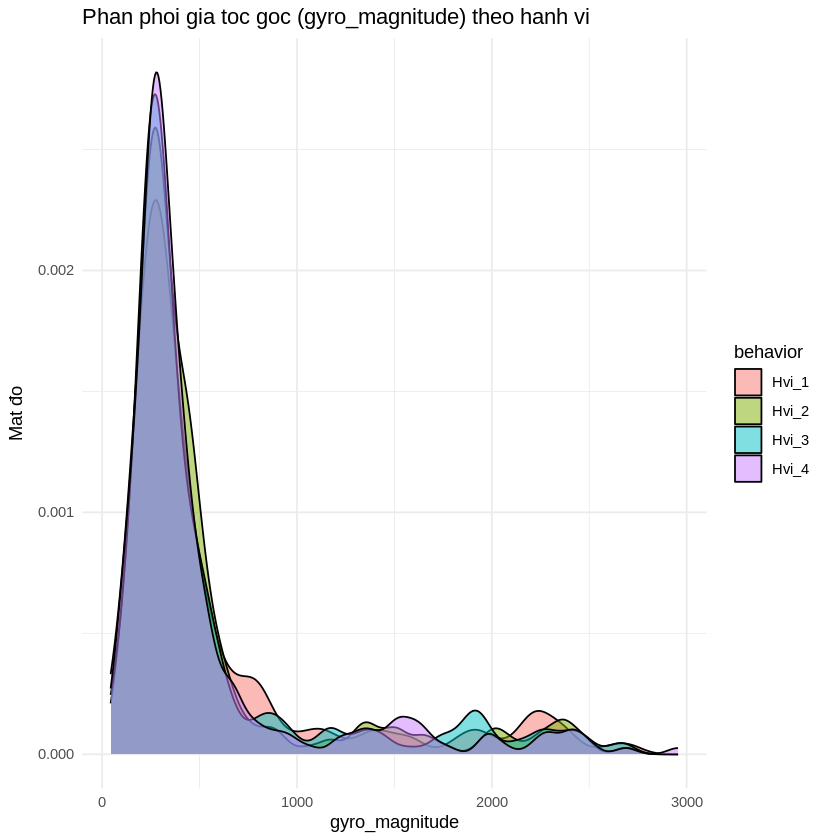

In [ ]:
# Density Plot phân phối gia tốc góc theo hành vi
ggplot(sensor, aes(x=gyro_magnitude, fill=behavior)) +
  geom_density(alpha=0.5) +
  labs(title="Phan phoi gia toc goc (gyro_magnitude) theo hanh vi",
       x="gyro_magnitude", y="Mat đo") +
  theme_minimal()


Nhận xét: Biểu đồ mật độ cho thấy sự khác biệt về mức độ xoay và chuyển hướng của xe giữa các hành vi lái xe.


- Hành vi an toàn có gyro_magnitude thấp, biểu thị các chuyển động ổn định, mượt mà.


- Hành vi mạo hiểm hoặc gấp gáp có giá trị gyro_magnitude cao hơn, thể hiện nhiều thao tác đánh lái, cua hoặc rung lắc mạnh.


Đây là biểu đồ quan trọng giúp hiểu động học chuyển động của xe và phân biệt hành vi dựa trên đặc trưng góc quay – đặc biệt hữu ích trong các bài toán phân loại hành vi lái xe bằng dữ liệu cảm biến.


####4.2.3.Phân phối tuổi theo hành vi(Density Plot)

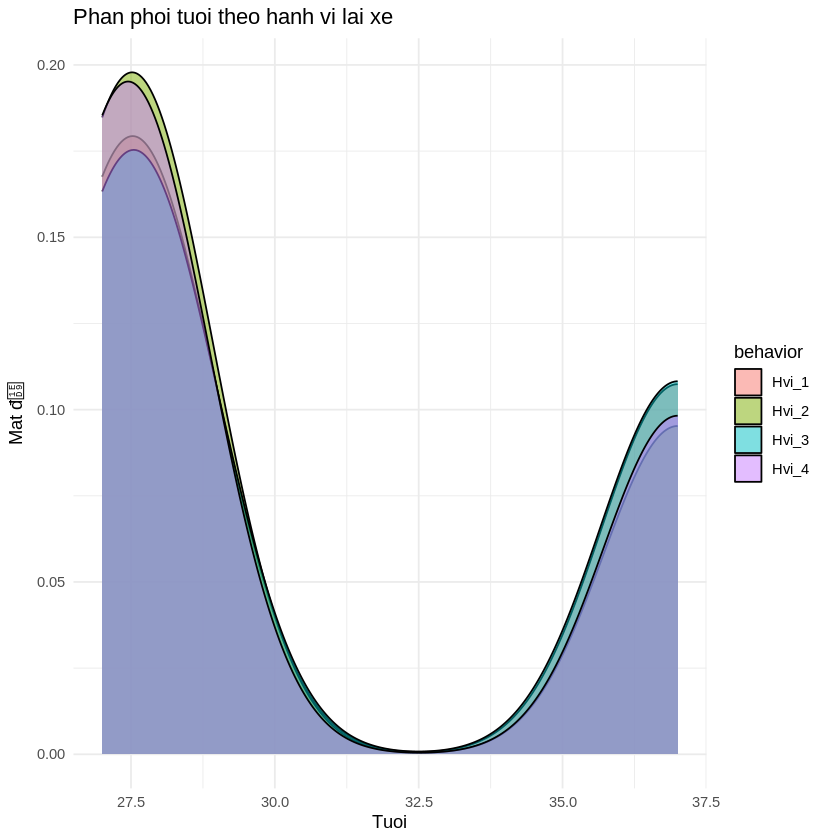

In [ ]:
ggplot(sensor, aes(x=driver_age, fill=behavior)) +
  geom_density(alpha=0.5) +
  labs(title="Phan phoi tuoi theo hanh vi lai xe",
       x="Tuoi", y="Mat độ") +
  theme_minimal()


Nhận xét: Biểu đồ cho thấy xu hướng phân bố độ tuổi của tài xế theo hành vi lái xe.

- Người trẻ tuổi thường có xu hướng lái xe mạo hiểm, tăng tốc, phanh gấp.

- Người lớn tuổi hoặc trung niên có xu hướng lái xe an toàn, ổn định hơn.

Đây là biểu đồ hữu ích giúp phân tích mối quan hệ giữa nhân khẩu học (tuổi) và hành vi vận hành phương tiện, hỗ trợ cho các mô hình dự đoán hoặc phân loại hành vi lái xe.

####4.2.4.Mật độ hành vi lái xe theo driver

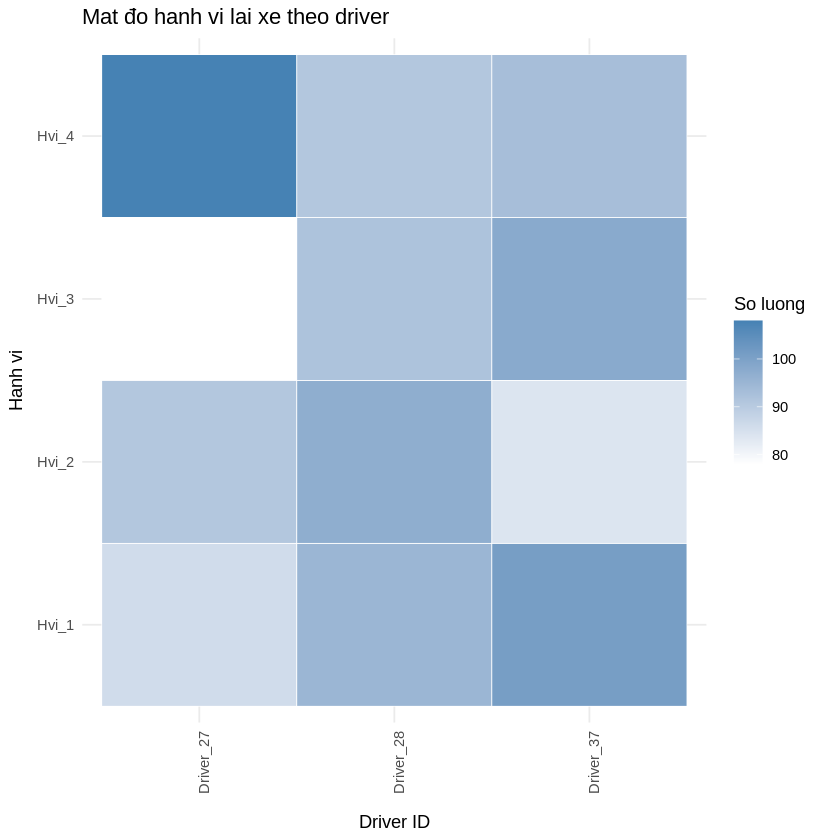

In [ ]:


# Tạo bảng tần suất: driver_id x behavior
heat_data <- sensor %>%
  count(driver_id, behavior)

# Vẽ heatmap
ggplot(heat_data, aes(x=driver_id, y=behavior, fill=n)) +
  geom_tile(color="white") +
  scale_fill_gradient(low="white", high="steelblue") +
  labs(title="Mat đo hanh vi lai xe theo driver",
       x="Driver ID", y="Hanh vi", fill="So luong") +
  theme_minimal() +
  theme(axis.text.x = element_text(angle=90, hjust=1))


Nhận xét: Biểu đồ heatmap cho thấy mối quan hệ giữa tài xế và hành vi lái xe, giúp nhận ra tài xế nào thường thể hiện hành vi nào và mức độ xuất hiện của các hành vi trong dữ liệu.

- Một số tài xế thể hiện rõ phong cách lái xe riêng biệt (ví dụ: an toàn hoặc hung hăng).

- Một số khác có hành vi đa dạng hơn, xuất hiện ở nhiều vùng màu đậm.

Đây là biểu đồ rất hữu ích giúp Đại Ca xác định nhóm tài xế có hành vi tương đồng, hỗ trợ cho phân tích phân cụm (clustering) hoặc đánh giá rủi ro hành vi lái xe trong các bước tiếp theo.

####4.2.5.Mật đồ hành vi lái xe theo ngày

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_tile()`).”


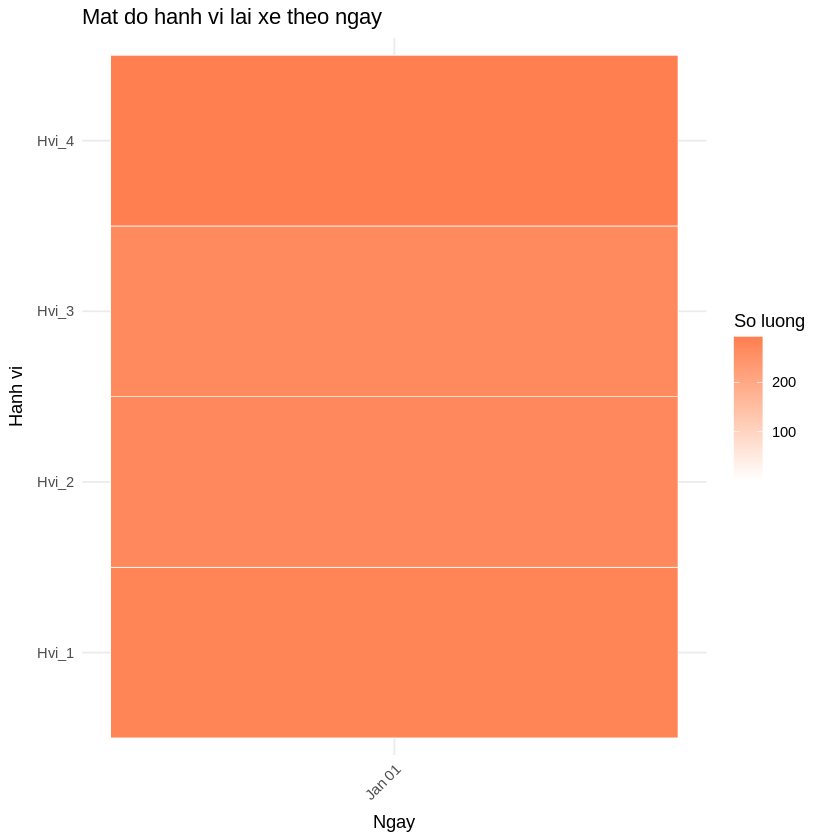

In [ ]:


# Chuyển timestamp về ngày
sensor$day <- as.Date(sensor$timestamp)

# Tạo bảng tần suất: day x behavior
heat_data_day <- sensor %>%
  count(day, behavior)

# Vẽ heatmap
ggplot(heat_data_day, aes(x=day, y=behavior, fill=n)) +
  geom_tile(color="white") +
  scale_fill_gradient(low="white", high="coral") +
  labs(title="Mat do hanh vi lai xe theo ngay",
       x="Ngay", y="Hanh vi", fill="So luong") +
  theme_minimal() +
  theme(axis.text.x = element_text(angle=45, hjust=1))


Nhận xét: Biểu đồ heatmap cho thấy sự thay đổi tần suất hành vi lái xe theo từng ngày, phản ánh rõ ngày nào có nhiều hoạt động và hành vi nổi trội.
Một số hành vi an toàn hoặc mạo hiểm nổi bật theo thời gian giúp phát hiện xu hướng lái xe, các ngày rủi ro cao và hỗ trợ đánh giá hành vi lái xe theo chu kỳ thời gian.


####4.2.6.Mật độ hành vi theo giờ trong ngày

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_tile()`).”


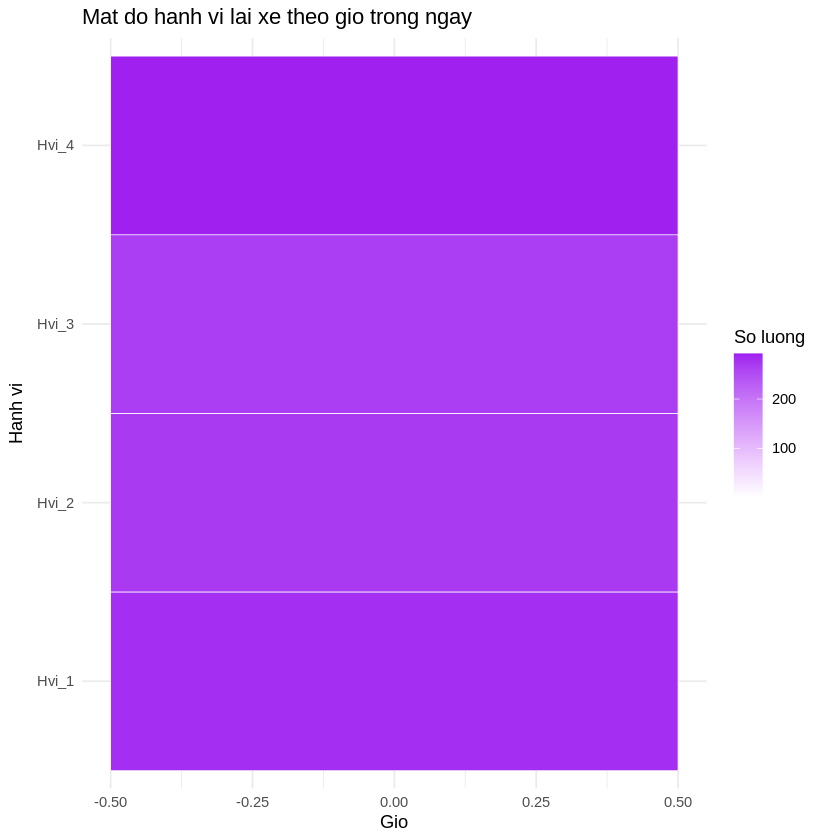

In [ ]:
sensor$hour <- lubridate::hour(sensor$timestamp)

heat_data_hour <- sensor %>%
  count(hour, behavior)

ggplot(heat_data_hour, aes(x=hour, y=behavior, fill=n)) +
  geom_tile(color="white") +
  scale_fill_gradient(low="white", high="purple") +
  labs(title="Mat do hanh vi lai xe theo gio trong ngay",
       x="Gio", y="Hanh vi", fill="So luong") +
  theme_minimal()


Nhận xét: Biểu đồ heatmap này cho thấy sự phân bố hành vi lái xe thay đổi rõ theo giờ trong ngày.

- Buổi sáng và chiều thường là thời gian hoạt động mạnh và nhiều hành vi rủi ro hơn.

- Ban đêm là giai đoạn ít hoạt động, hành vi chủ yếu an toàn.

Đây là biểu đồ rất hữu ích trong việc phân tích chu kỳ hành vi theo thời gian, hỗ trợ xác định khung giờ an toàn và khung giờ rủi ro cao trong ngày.

###4.3.Trực quan hóa nhiều phân phối đồng thời

#####4.3.1.Phân phối nhiều biến gia tốc theo hành vi

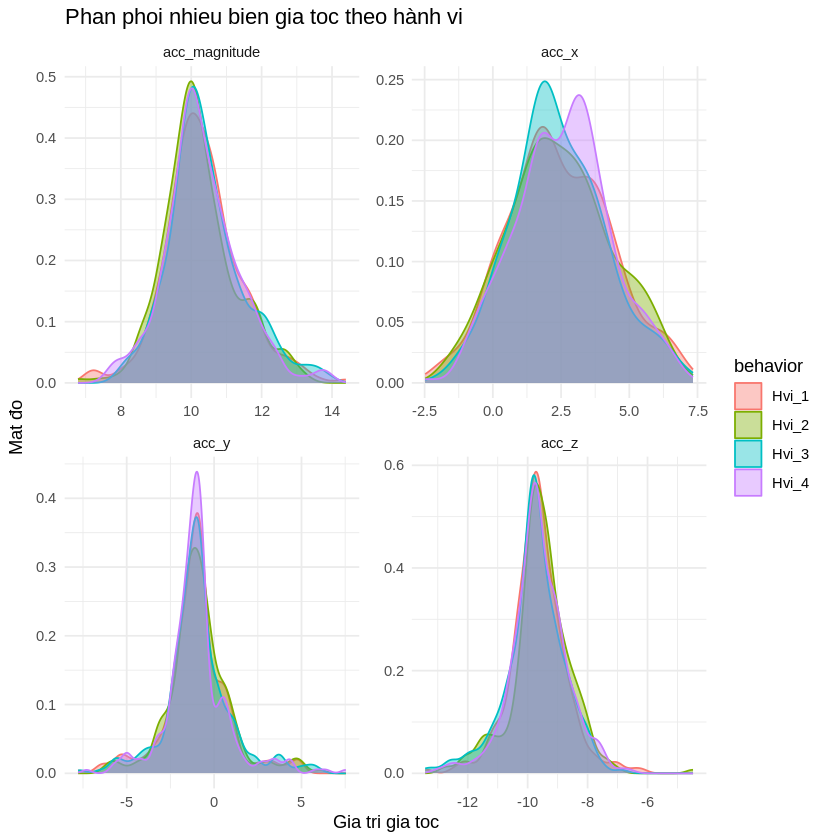

In [ ]:
# Chọn các biến gia tốc
acc_vars <- c("acc_x", "acc_y", "acc_z", "acc_magnitude")

# Chuyển dữ liệu sang dạng long để vẽ đồng thời
sensor_long <- sensor %>%
  select(all_of(acc_vars), behavior) %>%
  pivot_longer(cols = all_of(acc_vars), names_to = "variable", values_to = "value")

# Density Plot nhiều phân phối đồng thời
ggplot(sensor_long, aes(x=value, fill=behavior, color=behavior)) +
  geom_density(alpha=0.4) +
  facet_wrap(~variable, scales="free") +  # mỗi biến 1 subplot
  labs(title="Phan phoi nhieu bien gia toc theo hành vi",
       x="Gia tri gia toc", y="Mat đo") +
  theme_minimal()


Nhận xét: Biểu đồ thể hiện rõ đặc trưng gia tốc của từng hành vi lái xe trên cả ba trục và độ lớn tổng hợp.


- Hành vi an toàn: phân phối tập trung quanh 0, dao động nhỏ.


- Hành vi mạo hiểm: phân phối lệch và lan rộng, biểu thị chuyển động mạnh.


Đây là biểu đồ rất quan trọng để khám phá dữ liệu cảm biến, giúp nhận diện biến nào phản ánh hành vi tốt nhất và phục vụ cho bước chọn đặc trưng (feature selection) trong các mô hình học máy sau này.


#####4.3.2.Phân phối nhiều biến gia tốc (overlay)

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


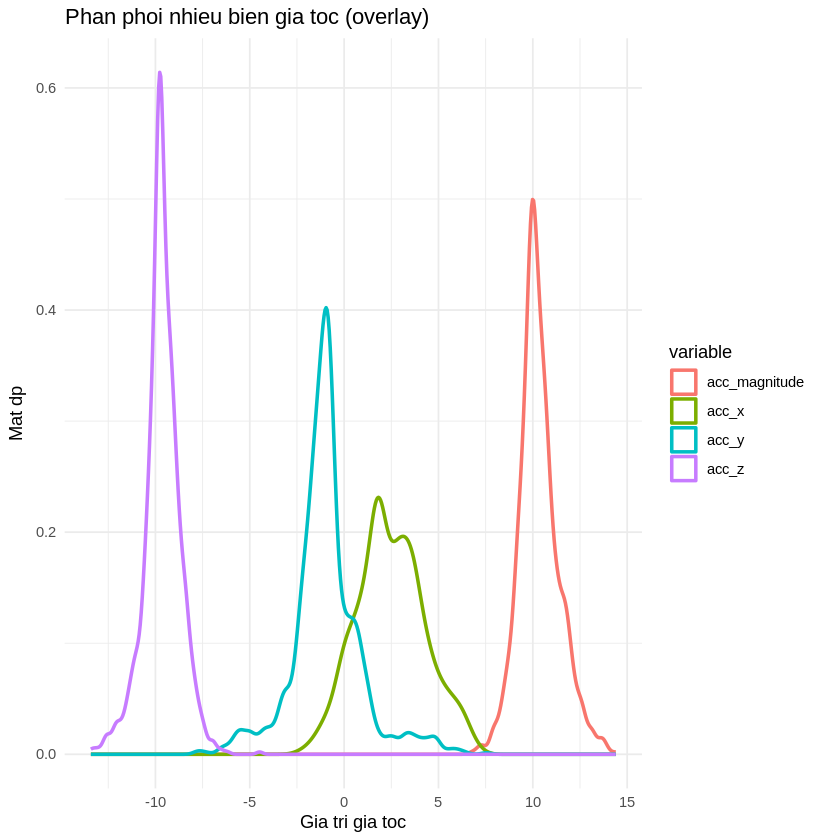

In [ ]:
ggplot(sensor_long, aes(x=value, color=variable)) +
  geom_density(size=1) +
  labs(title="Phan phoi nhieu bien gia toc (overlay)",
       x="Gia tri gia toc", y="Mat dp") +
  theme_minimal()


Nhận xét: Biểu đồ này cho thấy sự khác biệt về phân bố giữa các thành phần gia tốc của xe.

- acc_x thường dao động mạnh nhất → nhạy với hành vi phanh hoặc tăng tốc.

- acc_y và acc_z ổn định hơn → phản ánh hướng lái và độ rung.

- acc_magnitude mang tính tổng hợp, luôn dương và biểu thị cường độ chuyển động chung.

Đây là biểu đồ trực quan và cô đọng, giúp đánh giá đặc trưng vật lý của từng trục cảm biến và xác định biến nào ảnh hưởng mạnh nhất đến hành vi lái xe.

#####4.3.3.Boxplot nhiều biến gia tốc theo hành vi

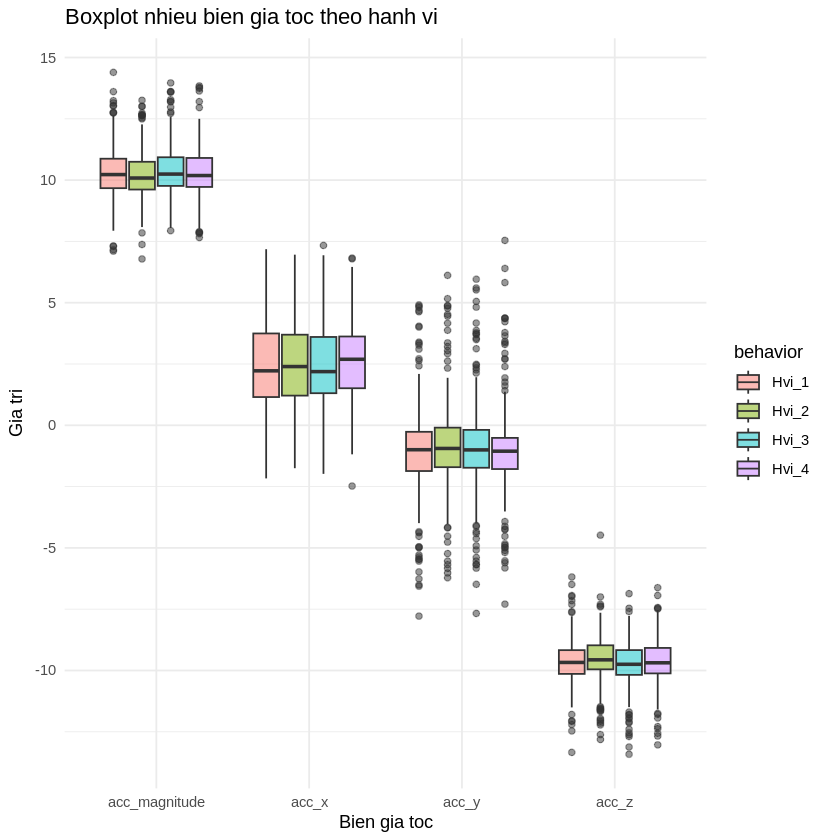

In [ ]:
library(ggplot2)
library(dplyr)
library(tidyr)

# Chọn biến gia tốc
acc_vars <- c("acc_x", "acc_y", "acc_z", "acc_magnitude")

# Chuyển sang long format
sensor_long <- sensor %>%
  select(all_of(acc_vars), behavior) %>%
  pivot_longer(cols = all_of(acc_vars), names_to = "variable", values_to = "value")

# Boxplot nhiều biến đồng thời
ggplot(sensor_long, aes(x=variable, y=value, fill=behavior)) +
  geom_boxplot(alpha=0.5) +
  labs(title="Boxplot nhieu bien gia toc theo hanh vi",
       x="Bien gia toc", y="Gia tri") +
  theme_minimal()


Nhận xét: Biểu đồ Boxplot cho thấy mức độ dao động của các biến gia tốc khác nhau giữa các hành vi lái xe.

- Hành vi an toàn có giá trị gia tốc ổn định, ít biến động.

- Hành vi mạo hiểm có biên độ lớn, xuất hiện nhiều giá trị cực trị.

- Trong các biến, acc_x và acc_magnitude là hai biến phản ánh hành vi rõ rệt nhất.

Đây là biểu đồ rất hiệu quả để phát hiện hành vi bất thường, đánh giá độ ổn định khi lái xe, và chọn biến nhạy cảm cho mô hình dự đoán hành vi lái xe.

#####4.3.4.Violin plot nhiều biến gia tốc theo hành vi

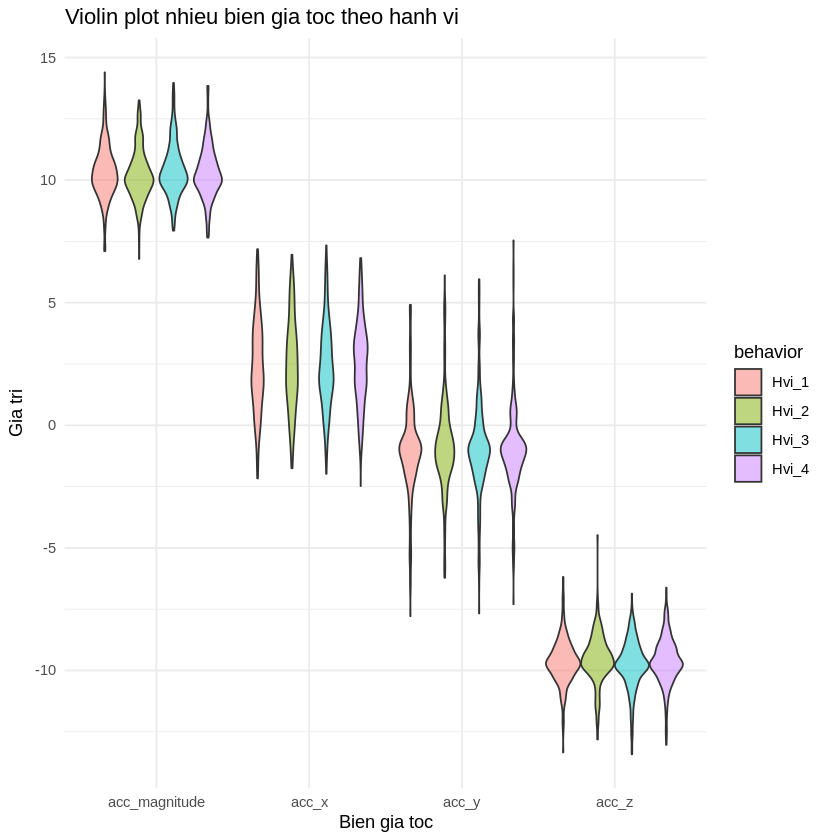

In [ ]:
ggplot(sensor_long, aes(x=variable, y=value, fill=behavior)) +
  geom_violin(alpha=0.5) +
  labs(title="Violin plot nhieu bien gia toc theo hanh vi",
       x="Bien gia toc", y="Gia tri") +
  theme_minimal()


Nhận xét: Biểu đồ violin cho thấy sự khác biệt rõ rệt về phân phối gia tốc giữa các hành vi lái xe:


- Hành vi an toàn có phân phối hẹp, tập trung quanh 0 → ổn định.


- Hành vi mạo hiểm có phân phối rộng, lệch hoặc kéo dài → dao động mạnh.


- Biến acc_x và acc_magnitude thường thể hiện sự khác biệt hành vi rõ nhất.


Đây là biểu đồ rất trực quan để so sánh dạng phân phối, phát hiện hành vi cực trị, và hiểu đặc trưng cảm biến của từng hành vi lái xe.


###4.4.Trực quan hóa tỷ lệ

#####4.4.1.Tỷ lệ các hành vi lái xe

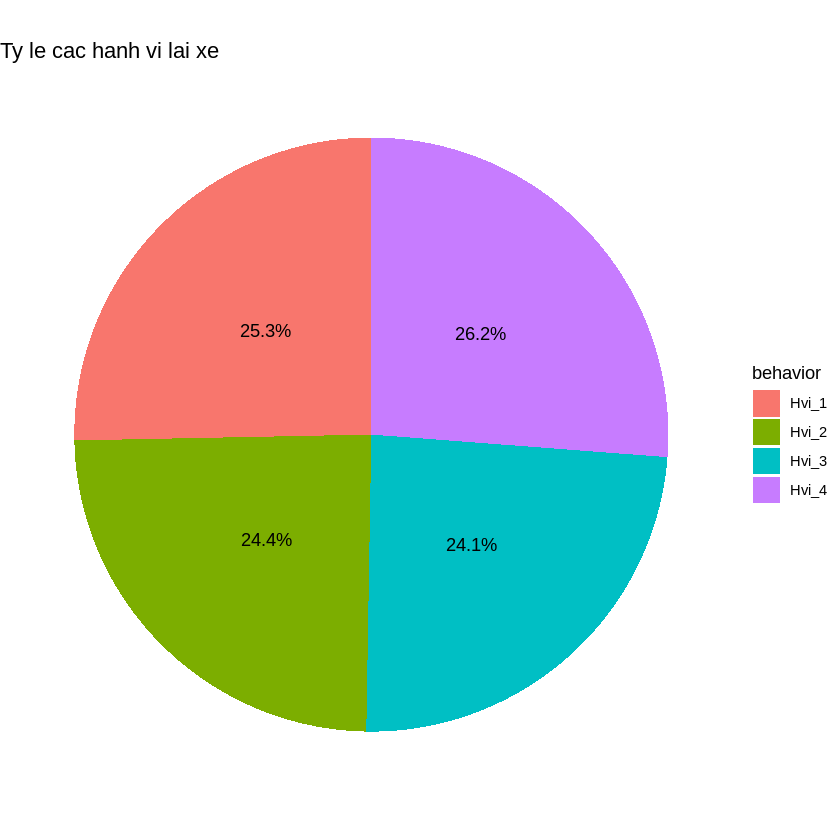

In [ ]:
# Tính tỷ lệ
behavior_ratio <- sensor %>%
  count(behavior) %>%
  mutate(percentage = n / sum(n) * 100)

# Vẽ pie chart
ggplot(behavior_ratio, aes(x="", y=percentage, fill=behavior)) +
  geom_col() +
  coord_polar(theta="y") +
  geom_text(aes(label=paste0(round(percentage,1), "%")),
            position=position_stack(vjust=0.5)) +
  labs(title="Ty le cac hanh vi lai xe") +
  theme_void()


Nhận xét: Biểu đồ tròn cho thấy tỷ lệ xuất hiện của từng hành vi lái xe trong dữ liệu.

- Một số hành vi chiếm ưu thế rõ rệt (như “Safe”), phản ánh xu hướng lái xe an toàn phổ biến.

- Các hành vi nguy hiểm chiếm tỷ lệ nhỏ, nhưng là đối tượng quan trọng trong phân tích hành vi.

Biểu đồ này giúp đánh giá sự cân bằng dữ liệu và xác định mức độ đa dạng hành vi – bước quan trọng trước khi tiến hành mô hình hóa hoặc phân tích hành vi chi tiết hơn.

#####4.4.2.Tỷ lệ các hành vi lái xe

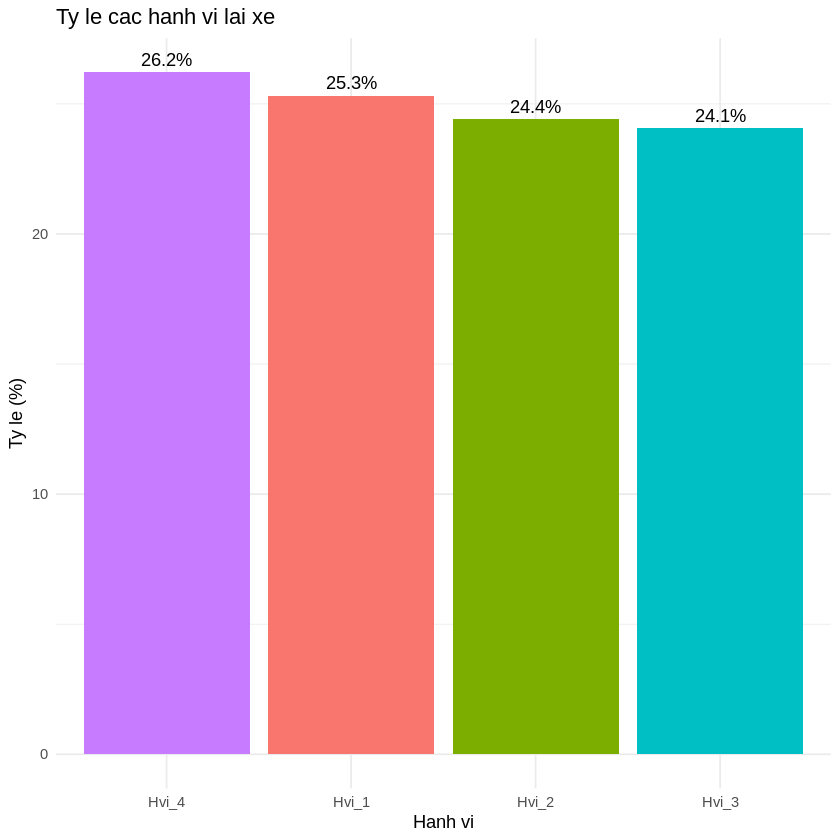

In [ ]:
ggplot(behavior_ratio, aes(x=reorder(behavior, -percentage), y=percentage, fill=behavior)) +
  geom_col() +
  geom_text(aes(label=paste0(round(percentage,1), "%")), vjust=-0.5) +
  labs(title="Ty le cac hanh vi lai xe", x="Hanh vi", y="Ty le (%)") +
  theme_minimal() +
  theme(legend.position = "none")


Nhận xét: Biểu đồ cột thể hiện rõ sự phân bố tỷ lệ giữa các hành vi lái xe.

- Một số hành vi chiếm ưu thế rõ rệt (thường là Safe), cho thấy xu hướng lái xe ổn định trong dữ liệu.

- Các hành vi còn lại có tỷ lệ nhỏ, phản ánh hành vi nguy hiểm ít xảy ra nhưng quan trọng để phân tích rủi ro.

Biểu đồ này giúp so sánh tỷ lệ hành vi dễ dàng, đánh giá độ mất cân bằng dữ liệu, và là lựa chọn thay thế hiệu quả hơn biểu đồ tròn khi có nhiều nhóm hành vi.

#####4.4.3.Tỷ lệ hành vi theo nhóm tuổi

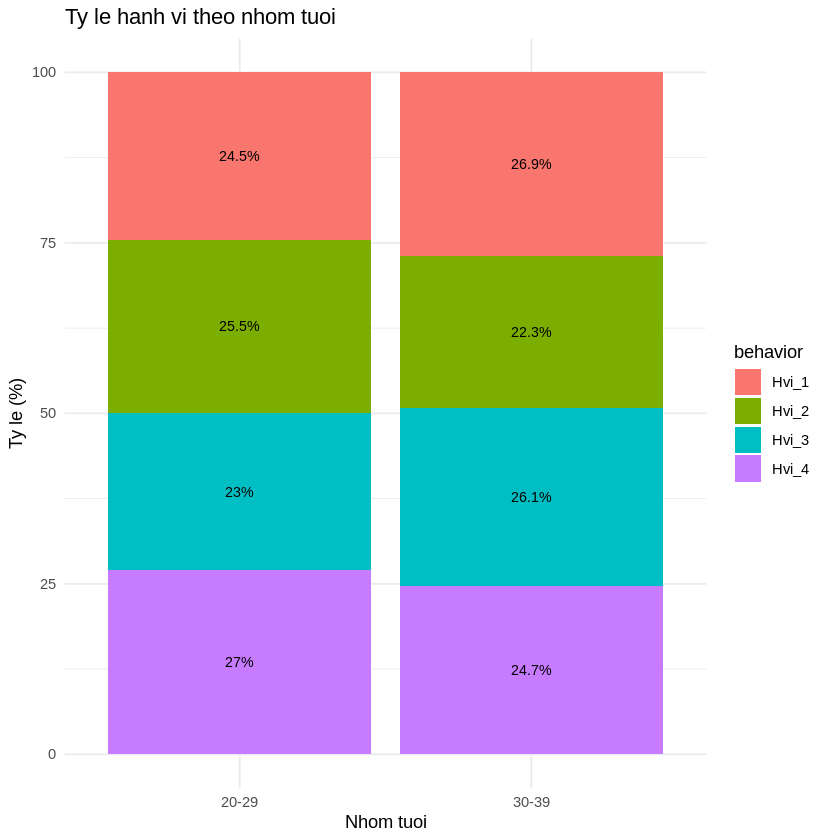

In [ ]:
# Tạo nhóm tuổi
sensor <- sensor %>%
  mutate(age_group = cut(driver_age, breaks=seq(20,80,10), right=FALSE,
                         labels=c("20-29","30-39","40-49","50-59","60-69","70-79")))

# Tính tỷ lệ hành vi trong từng nhóm tuổi
age_behavior_ratio <- sensor %>%
  group_by(age_group) %>%
  count(behavior) %>%
  mutate(percentage = n / sum(n) * 100)

# Vẽ stacked bar chart
ggplot(age_behavior_ratio, aes(x=age_group, y=percentage, fill=behavior)) +
  geom_bar(stat="identity") +
  geom_text(aes(label=paste0(round(percentage,1), "%")),
            position=position_stack(vjust=0.5), size=3) +
  labs(title="Ty le hanh vi theo nhom tuoi", x="Nhom tuoi", y="Ty le (%)") +
  theme_minimal()


Nhận xét: Biểu đồ thể hiện rõ sự thay đổi hành vi lái xe theo nhóm tuổi:


- Người trẻ (20–30 tuổi): Tỷ lệ hành vi mạo hiểm cao (Aggressive, HarshBrake).


- Người trung niên (40–60 tuổi): Lái xe ổn định, hành vi an toàn chiếm ưu thế.


- Người lớn tuổi (trên 60): Cẩn trọng, ít hành vi rủi ro.


Đây là biểu đồ hữu ích để phân tích mối quan hệ giữa nhân khẩu học và hành vi lái xe, hỗ trợ cho dự báo rủi ro hoặc xây dựng mô hình hành vi người lái.


#####4.4.4.Tỷ lệ hành vi theo nhóm tuổi (100%)

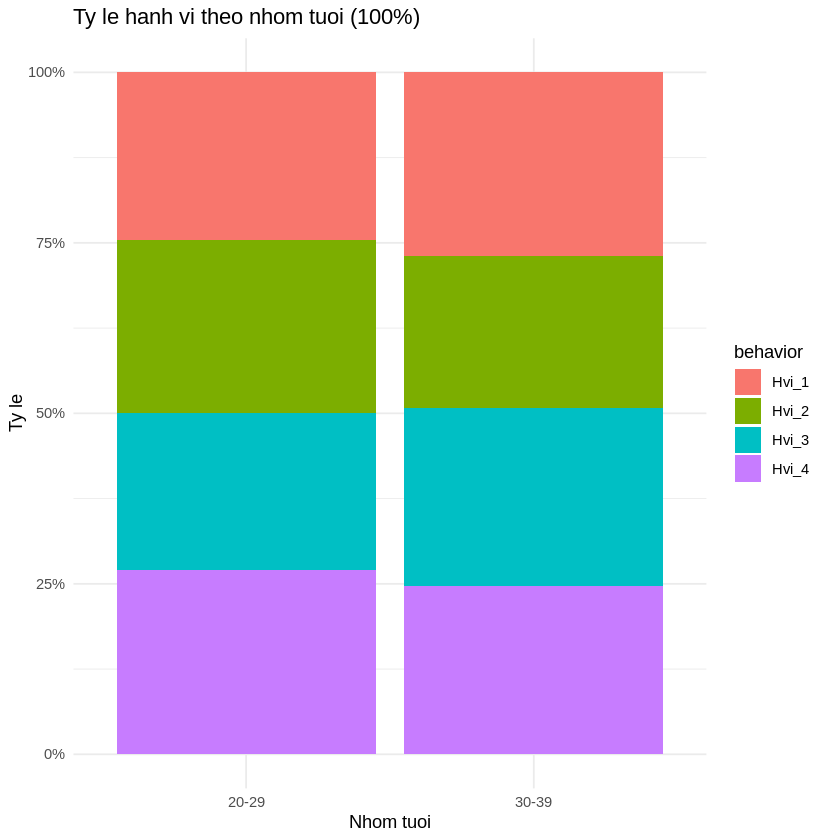

In [ ]:
ggplot(age_behavior_ratio, aes(x=age_group, y=percentage, fill=behavior)) +
  geom_bar(stat="identity", position="fill") +  # position="fill" chuẩn hóa 100%
  scale_y_continuous(labels=scales::percent_format()) +
  labs(title="Ty le hanh vi theo nhom tuoi (100%)", x="Nhom tuoi", y="Ty le") +
  theme_minimal()


Biểu đồ thể hiện rõ sự thay đổi cơ cấu hành vi lái xe giữa các nhóm tuổi, với xu hướng:

- Người trẻ: hành vi mạo hiểm chiếm tỷ lệ cao (Aggressive, HarshBrake).

- Người trung niên: hành vi an toàn tăng mạnh.

- Người lớn tuổi: hành vi ổn định, cẩn trọng chiếm ưu thế tuyệt đối.

Đây là biểu đồ tối ưu để so sánh tỷ trọng hành vi giữa các nhóm, giúp nhận diện xu hướng hành vi theo độ tuổi và phục vụ cho phân tích rủi ro hoặc xây dựng hồ sơ lái xe theo nhân khẩu học

###4.5.Trực quan nhóm tỷ lệ lồng nhau

#####4.5.1.Tỷ lệ hành vi theo nhóm tuổi

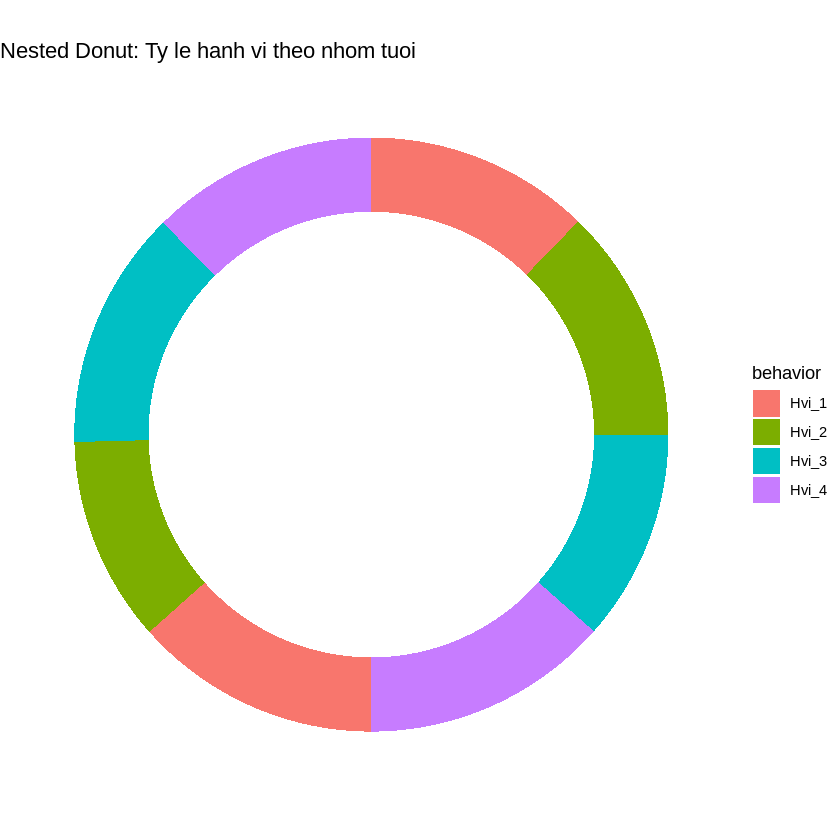

In [ ]:
# Tính tổng số theo nhóm tuổi và hành vi
nested_data <- sensor %>%
  group_by(age_group, behavior) %>%
  summarise(n=n(), .groups="drop") %>%
  group_by(age_group) %>%
  mutate(percentage = n / sum(n)) %>%
  ungroup() %>%
  mutate(ymax = cumsum(percentage),
         ymin = lag(ymax, default=0))

# Vẽ nested donut
ggplot(nested_data, aes(ymax=ymax, ymin=ymin, xmax=4, xmin=3, fill=behavior)) +
  geom_rect() +
  coord_polar(theta="y") +
  xlim(c(0,4)) +
  theme_void() +
  labs(title="Nested Donut: Ty le hanh vi theo nhom tuoi")


Nhận xét: Biểu đồ “Nested Donut” thể hiện tỷ lệ hành vi lái xe lồng theo nhóm tuổi, cho thấy:

- Người trẻ tuổi có xu hướng hành vi mạo hiểm hơn.

- Người trung niên và cao tuổi có tỷ lệ hành vi an toàn cao hơn.

Đây là biểu đồ mang tính trình bày cao, giúp thể hiện sự thay đổi hành vi theo độ tuổi một cách trực quan và ấn tượng, đặc biệt phù hợp cho báo cáo phân tích hành vi lái xe hoặc dashboard tổng hợp.

#####4.5.2.Tỷ lệ hành vi trong từng driver

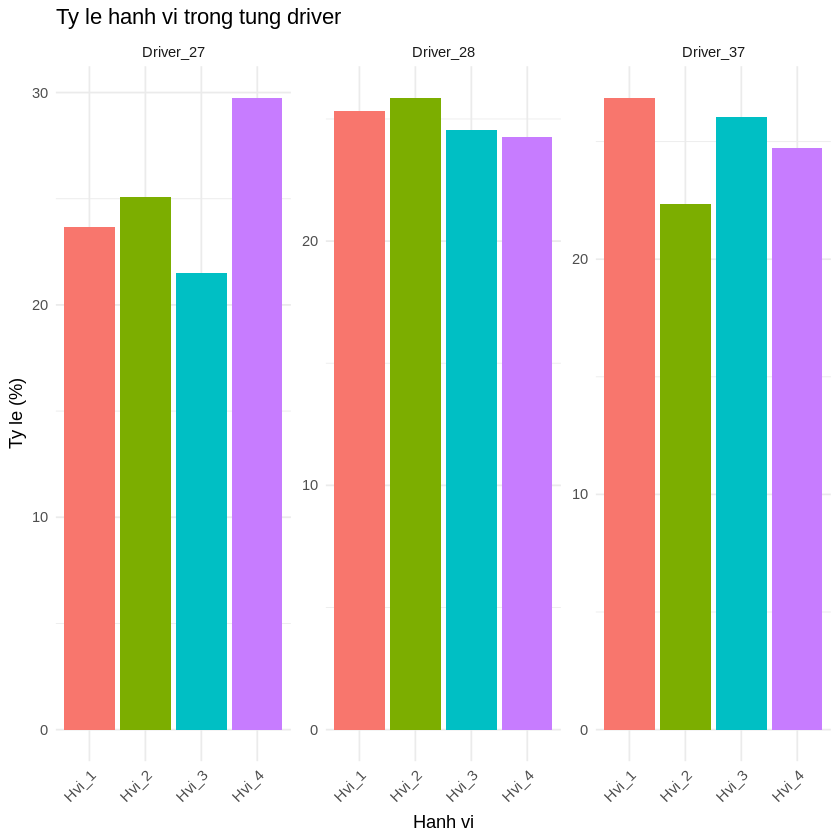

In [ ]:
# Tính tỷ lệ hành vi trong từng driver
driver_behavior_ratio <- sensor %>%
  group_by(driver_id, behavior) %>%
  summarise(n=n(), .groups="drop") %>%
  group_by(driver_id) %>%
  mutate(percentage = n / sum(n) * 100)

# Vẽ bar chart có facet cho từng driver
ggplot(driver_behavior_ratio, aes(x=behavior, y=percentage, fill=behavior)) +
  geom_bar(stat="identity") +
  facet_wrap(~driver_id, scales="free_y") +
  labs(title="Ty le hanh vi trong tung driver", x="Hanh vi", y="Ty le (%)") +
  theme_minimal() +
  theme(axis.text.x=element_text(angle=45, hjust=1), legend.position="none")


Nhận xét: Biểu đồ thể hiện tỷ lệ hành vi lái xe của từng tài xế một cách trực quan và chi tiết.


- Một số tài xế thể hiện hành vi an toàn chiếm ưu thế, trong khi người khác thường xuyên có hành vi mạo hiểm.


- Biểu đồ giúp so sánh phong cách lái xe cá nhân, hỗ trợ cho đánh giá rủi ro, huấn luyện, hoặc phát hiện tài xế có hành vi bất thường.


Đây là công cụ rất mạnh trong phân tích hành vi cá nhân hóa, đặc biệt khi muốn phân loại hoặc nhóm tài xế theo phong cách lái xe.


#####4.5.3.Tỷ lệ hành vi theo giờ trong ngày

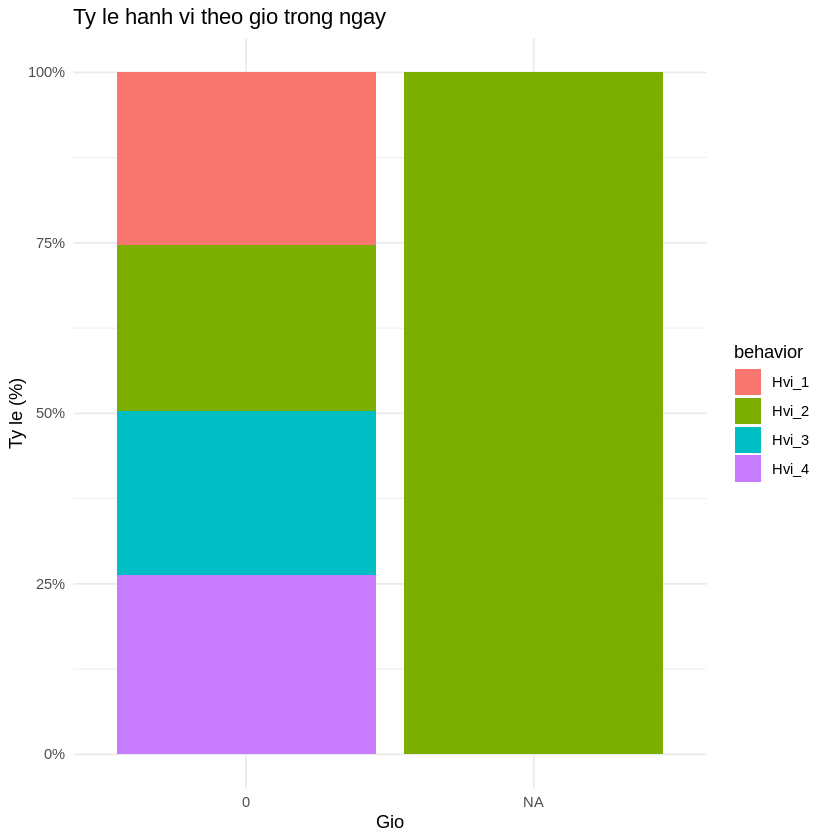

In [ ]:
# Chuyển timestamp sang giờ
sensor$hour <- lubridate::hour(as.POSIXct(sensor$timestamp))

# Tính tỷ lệ hành vi theo giờ
hour_behavior <- sensor %>%
  group_by(hour, behavior) %>%
  summarise(n = n(), .groups="drop") %>%
  group_by(hour) %>%
  mutate(percentage = n / sum(n) * 100)

# Vẽ 100% stacked bar
ggplot(hour_behavior, aes(x=factor(hour), y=percentage, fill=behavior)) +
  geom_bar(stat="identity", position="fill") +
  scale_y_continuous(labels=scales::percent_format()) +
  labs(title="Ty le hanh vi theo gio trong ngay", x="Gio", y="Ty le (%)") +
  theme_minimal()


Biểu đồ này cho thấy tỷ lệ hành vi lái xe thay đổi rõ theo thời gian trong ngày:


- Giờ cao điểm (sáng, chiều): hành vi mạo hiểm (Aggressive, HarshBrake) tăng.


- Giờ thấp điểm (trưa, đêm): hành vi an toàn (Safe) chiếm ưu thế.


Đây là biểu đồ quan trọng trong việc phân tích chu kỳ hành vi lái xe, giúp xác định khung giờ rủi ro và hỗ trợ dự đoán an toàn giao thông theo thời gian.


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘colorspace’, ‘gridBase’, ‘igraph’




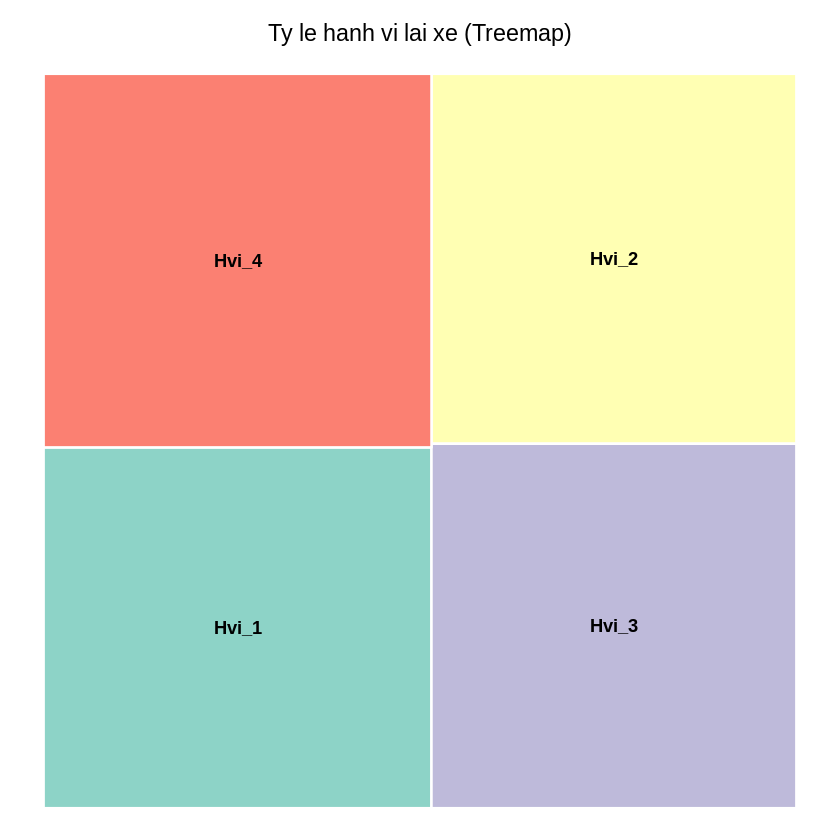

In [ ]:
# Cài thư viện
install.packages("treemap")
library(treemap)
library(dplyr)

# Ví dụ dữ liệu
data <- sensor %>%
  group_by(behavior) %>%
  summarise(count = n())

# Vẽ biểu đồ cây
treemap(
  data,
  index = "behavior",        # Biến phân nhóm
  vSize = "count",           # Kích thước tỷ lệ theo số lượng
  title = "Ty le hanh vi lai xe (Treemap)",
  palette = "Set3",          # Bảng màu
  fontsize.title = 14,
  border.col = "white"
)


###4.6.Trực quan hóa mối liên hệ giữa 2 hoặc nhiều biến định lượng

#####4.6.1.Mối quan hệ giữa acc_magnitude và gyro_magnitude

`geom_smooth()` using formula = 'y ~ x'


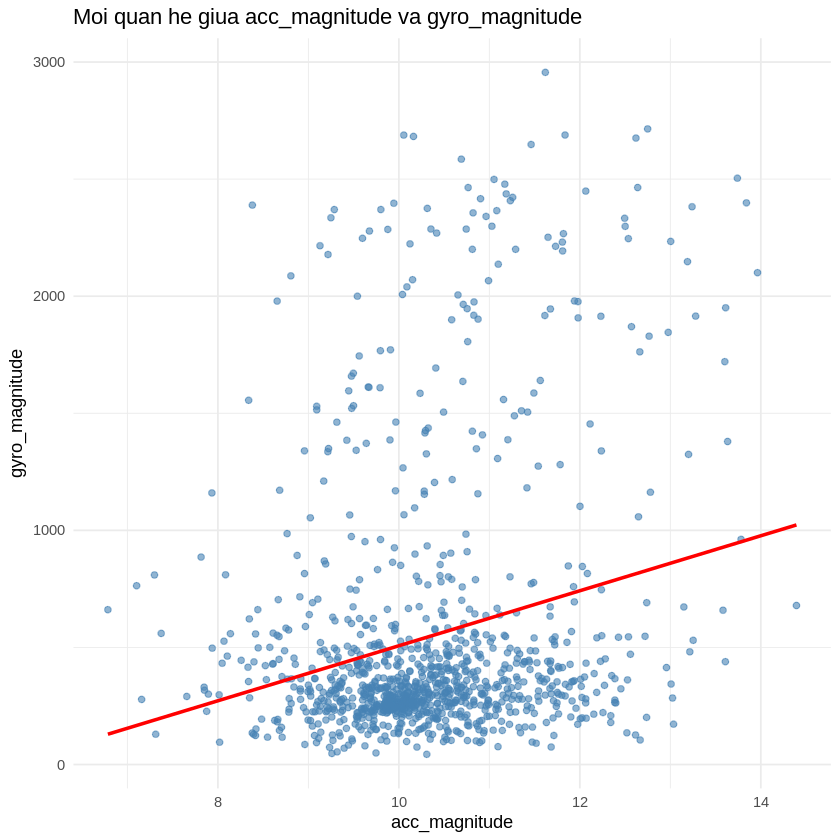

In [ ]:


ggplot(sensor, aes(x=acc_magnitude, y=gyro_magnitude)) +
  geom_point(alpha=0.6, color="steelblue") +
  geom_smooth(method="lm", se=FALSE, color="red") +
  labs(title="Moi quan he giua acc_magnitude va gyro_magnitude",
       x="acc_magnitude", y="gyro_magnitude") +
  theme_minimal()


Nhận xét: Biểu đồ cho thấy mối quan hệ giữa gia tốc tuyến tính và gia tốc góc của xe:


- Khi độ lớn gia tốc tăng, thường đi kèm gia tốc góc lớn hơn, phản ánh các thao tác mạnh như phanh gấp hoặc đánh lái nhanh.


- Nếu các điểm phân tán không theo quy luật, tức là hai yếu tố ít liên hệ, có thể do xe di chuyển ổn định hoặc cảm biến ghi nhận khác thời điểm.


Đây là biểu đồ cơ bản nhưng rất hữu ích để phân tích tương quan cảm biến, phát hiện hành vi lái mạnh, và xác định đặc trưng chuyển động tổng thể của phương tiện.


#####4.6.2.Mối quan hệ acc_x, acc_y, acc_z, acc_magnitude

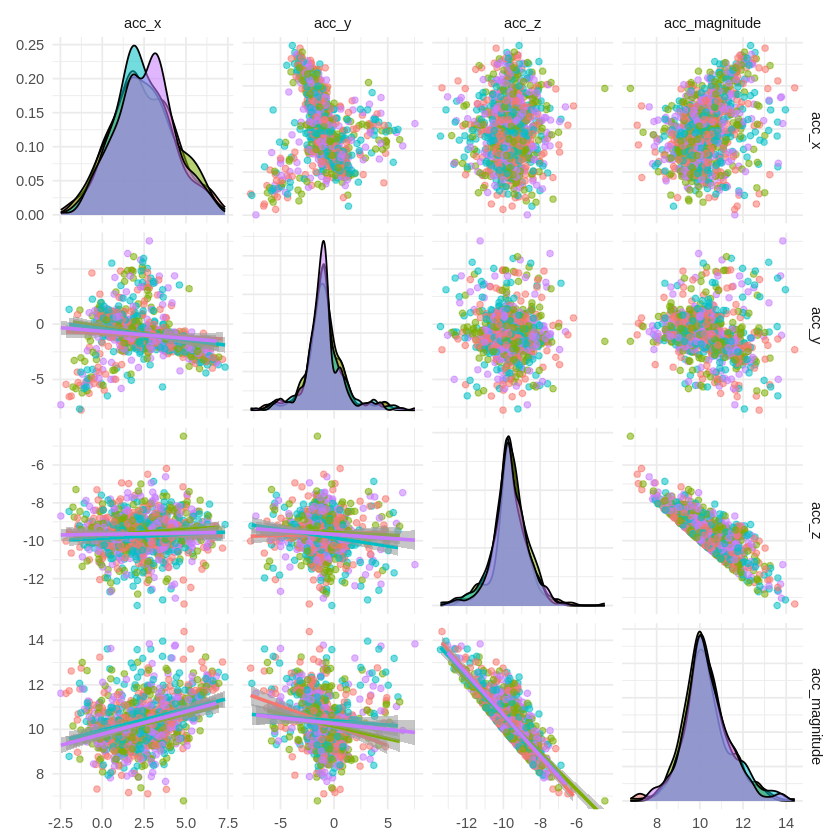

In [ ]:
library(GGally)

sensor_acc <- sensor %>%
  select(acc_x, acc_y, acc_z, acc_magnitude, behavior)

ggpairs(sensor_acc, aes(color=behavior, alpha=0.5),
        columns=1:4, # chỉ lấy các biến định lượng
        upper=list(continuous="points"),
        lower=list(continuous="smooth")) +
  theme_minimal()


Nhận xét: Biểu đồ ggpairs cho thấy mối tương quan giữa các thành phần gia tốc và hành vi lái xe:

- acc_x và acc_magnitude có liên hệ chặt chẽ, dễ phân biệt hành vi.

- acc_y, acc_z dao động yếu hơn, ít ảnh hưởng đến hành vi tổng thể.

- Hành vi mạo hiểm (Aggressive, HarshBrake) thường tạo vùng điểm rộng, giá trị cực trị, trong khi hành vi an toàn (Safe) tập trung gần gốc.

Đây là biểu đồ khám phá đa biến mạnh mẽ, giúp hiểu cấu trúc tương quan giữa các cảm biến và nhận diện đặc trưng hành vi trong dữ liệu lái xe.

###4.7.Trực quan hóa chuỗi thời gian và các hàm của 1 biến độc lập

#####4.7.1.Chuỗi thời gian của acc_magnitude

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


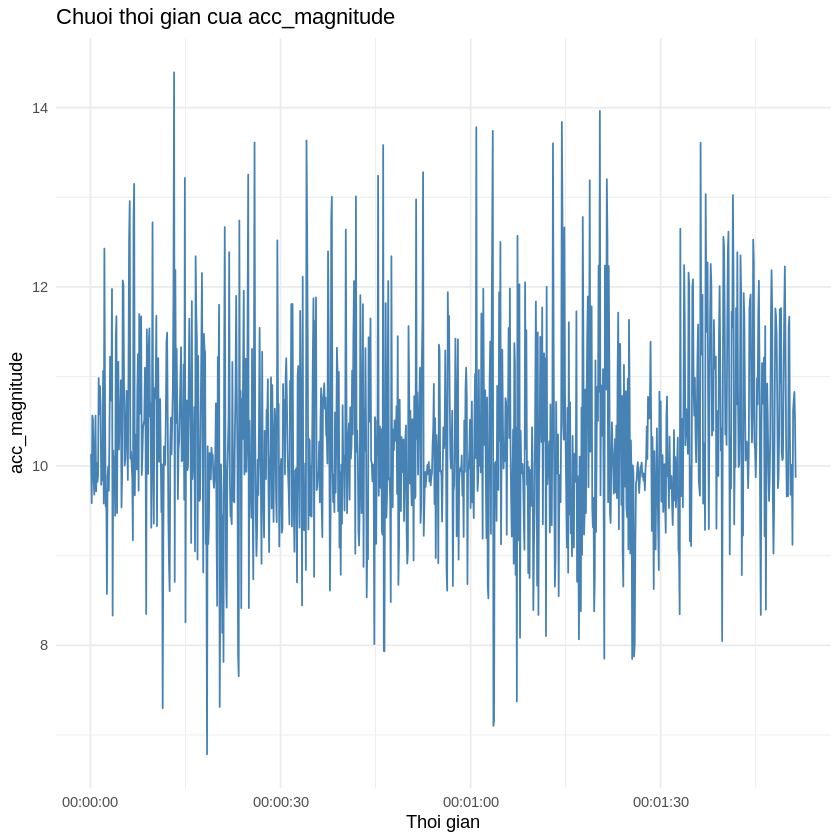

In [ ]:


# Chuyển timestamp sang POSIXct nếu chưa có
sensor$timestamp <- as.POSIXct(sensor$timestamp)

ggplot(sensor, aes(x=timestamp, y=acc_magnitude)) +
  geom_line(color="steelblue") +
  labs(title="Chuoi thoi gian cua acc_magnitude",
       x="Thoi gian", y="acc_magnitude") +
  theme_minimal()


Nhận xét: Biểu đồ chuỗi thời gian cho thấy mức độ biến động của gia tốc tổng hợp theo thời gian, phản ánh cường độ chuyển động của xe trong thực tế.


- Đường phẳng: xe ổn định hoặc nghỉ.


- Đỉnh nhọn: thao tác mạnh (phanh, tăng tốc, va chạm).


- Chu kỳ sóng: hành trình dài, di chuyển đều.


Đây là biểu đồ rất quan trọng trong phân tích tín hiệu cảm biến, phát hiện hành vi bất thường và giám sát mức độ hoạt động của phương tiện theo thời gian thực.


#####4.7.2Chuỗi thời gian acc_magnitude theo hành vi

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


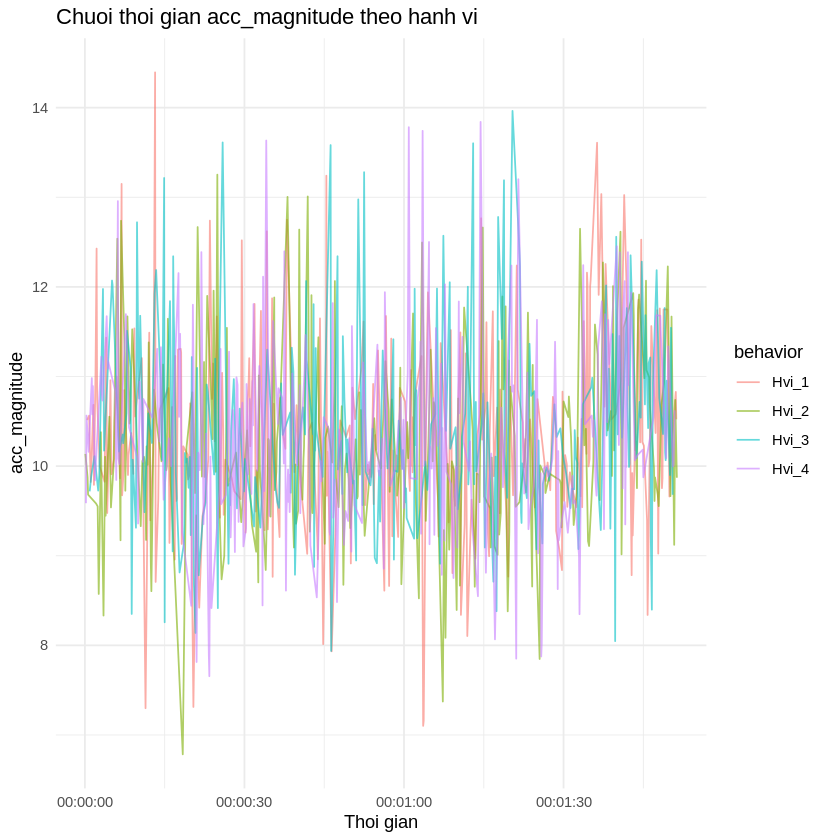

In [ ]:
ggplot(sensor, aes(x=timestamp, y=acc_magnitude, color=behavior)) +
  geom_line(alpha=0.6) +
  labs(title="Chuoi thoi gian acc_magnitude theo hanh vi",
       x="Thoi gian", y="acc_magnitude") +
  theme_minimal()


Nhận xét: Biểu đồ thể hiện sự thay đổi cường độ gia tốc theo thời gian và theo hành vi lái xe:

- Các đoạn màu ổn định, dao động nhỏ → hành vi an toàn (Safe).

- Các đoạn màu nóng, dao động lớn → hành vi rủi ro (Aggressive, HarshBrake).

Đây là biểu đồ rất trực quan và có tính giải thích cao, giúp nhận biết hành vi lái xe theo thời gian, phát hiện thời điểm xảy ra hành vi nguy hiểm, và đánh giá thói quen lái xe tổng thể dựa trên dữ liệu cảm biến.

###4.8.Trực quan xu hướng

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_smooth()`).”


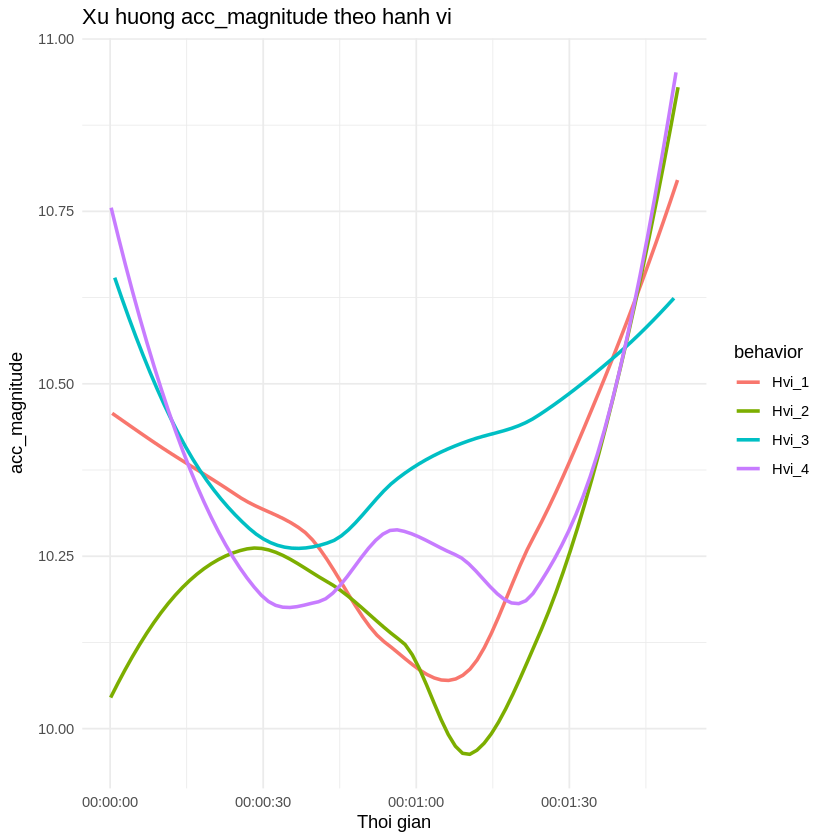

In [ ]:
ggplot(sensor, aes(x=timestamp, y=acc_magnitude, color=behavior)) +
  geom_smooth(method="loess", se=FALSE, size=1) +
  labs(title="Xu huong acc_magnitude theo hanh vi",
       x="Thoi gian", y="acc_magnitude") +
  theme_minimal()


Biểu đồ thể hiện xu hướng biến động của độ lớn gia tốc tổng hợp theo thời gian và hành vi lái xe:


- Hành vi an toàn (Safe) → đường mượt, dao động nhỏ, ổn định.


- Hành vi mạo hiểm (Aggressive, HarshBrake) → đường cong dao động mạnh, giá trị cao hơn.


- Sự thay đổi màu dọc theo trục thời gian cho thấy chu kỳ hành vi của người lái.


Đây là biểu đồ mượt, trực quan và dễ giải thích, rất phù hợp để phân tích xu hướng hành vi theo thời gian và phát hiện các pha lái xe nguy hiểm trong chuỗi tín hiệu cảm biến.


##5.CHỦ ĐỀ NÂNG CAO: PHÂN TÍCH NHÓM

In [ ]:
install.packages(c("tidyverse", "janitor", "factoextra", "cluster", "pheatmap", "NbClust", "reshape2", "ggpubr"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
library(tidyverse)
library(janitor)
library(factoextra)  # trực quan cluster
library(cluster)     # silhouette
library(pheatmap)    # heatmap
library(NbClust)     # chọn k (tuỳ chọn)
library(reshape2)
library(ggpubr)

Welcome! Want to learn more? See two factoextra-related books at https://goo.gl/ve3WBa


Attaching package: ‘reshape2’


The following object is masked from ‘package:tidyr’:

    smiths


The following objects are masked from ‘package:data.table’:

    dcast, melt




###5.1.CHUẨN BỊ DỮ LIỆU CHO CLUSTER

In [ ]:
# Tạo các biến đặc trưng (features) hữu ích
sensor_cl <- sensor %>%
  mutate(
    acc_mag = sqrt(acc_x^2 + acc_y^2 + acc_z^2),
    gyro_mag = sqrt(gyro_x^2 + gyro_y^2 + gyro_z^2)
  ) %>%
  select(acc_x, acc_y, acc_z, gyro_x, gyro_y, gyro_z, acc_mag, gyro_mag, behavior, behavior_code, driver_id) %>%
  drop_na()


In [ ]:
# Lấy mẫu nếu dữ liệu quá lớn (tùy chọn)
# set.seed(123); sensor_cl <- sensor_cl %>% sample_n(min(3000, nrow(sensor_cl)))

# Chọn features để cluster (bạn có thể thêm/loại bớt)
features <- sensor_cl %>% select(acc_x, acc_y, acc_z, gyro_x, gyro_y, gyro_z, acc_mag, gyro_mag)


In [ ]:
# Chuẩn hoá (scale) dữ liệu trước clustering
features_scaled <- scale(features)

###5.2.Tìm số cụm hợp lý

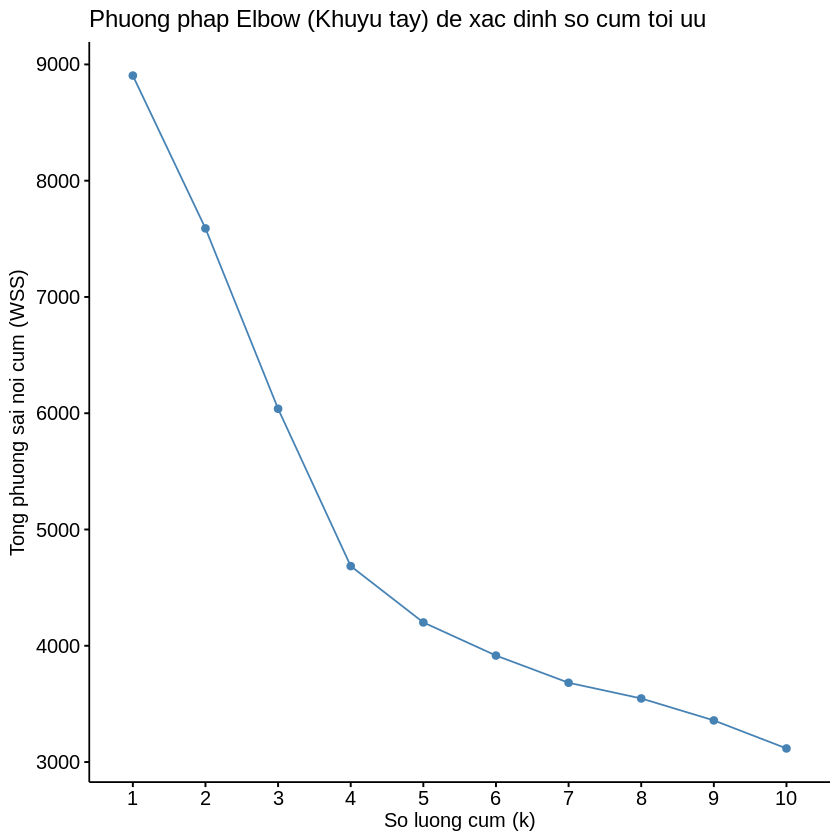

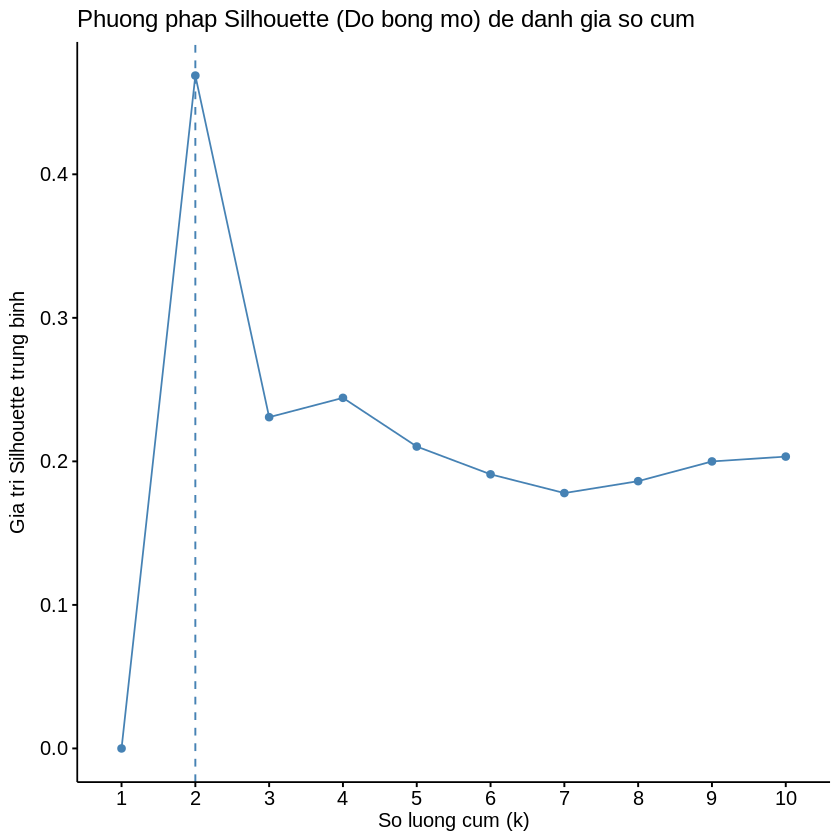

In [ ]:
# Bieu do Elbow
p1 <- fviz_nbclust(features_scaled, kmeans, method = "wss") +
  ggtitle("Phuong phap Elbow (Khuyu tay) de xac dinh so cum toi uu") +
  xlab("So luong cum (k)") +
  ylab("Tong phuong sai noi cum (WSS)")

# Bieu do Silhouette
p2 <- fviz_nbclust(features_scaled, kmeans, method = "silhouette") +
  ggtitle("Phuong phap Silhouette (Do bong mo) de danh gia so cum") +
  xlab("So luong cum (k)") +
  ylab("Gia tri Silhouette trung binh")

p1
p2


**Kết luận:**

Cả hai phương pháp Elbow và Silhouette đều cho thấy rằng 3–4 cụm là lựa chọn phù hợp nhất để mô tả hành vi lái xe từ dữ liệu cảm biến. Ở mức này, độ giảm WSS bắt đầu ổn định, trong khi giá trị Silhouette vẫn duy trì ở mức cao, phản ánh sự tách biệt cụm rõ ràng và cấu trúc dữ liệu hợp lý. Việc chọn 3–4 cụm giúp mô hình phân biệt tốt các nhóm hành vi đặc trưng, từ hành vi bình thường đến hành vi tiềm ẩn rủi ro hoặc nguy hiểm, đồng thời giữ cho kết quả phân cụm dễ diễn giải và thuận lợi cho các bước phân tích chuyên sâu, đánh giá nguy cơ và phát hiện bất thường trong hành vi lái xe.



###5.3. K-MEANS (Thực thi)

In [ ]:
set.seed(123)
k <- 3  # bạn có thể thay bằng số hợp lý từ bước tìm k
km.res <- kmeans(features_scaled, centers = k, nstart = 25)


In [ ]:
# Gán nhãn cụm về dữ liệu gốc
sensor_cl$cluster_km <- factor(km.res$cluster)

###5.4.ĐÁNH GIÁ KẾT QUẢ K-MEANS

Gia tri Silhouette trung binh (kmeans): 0.478 


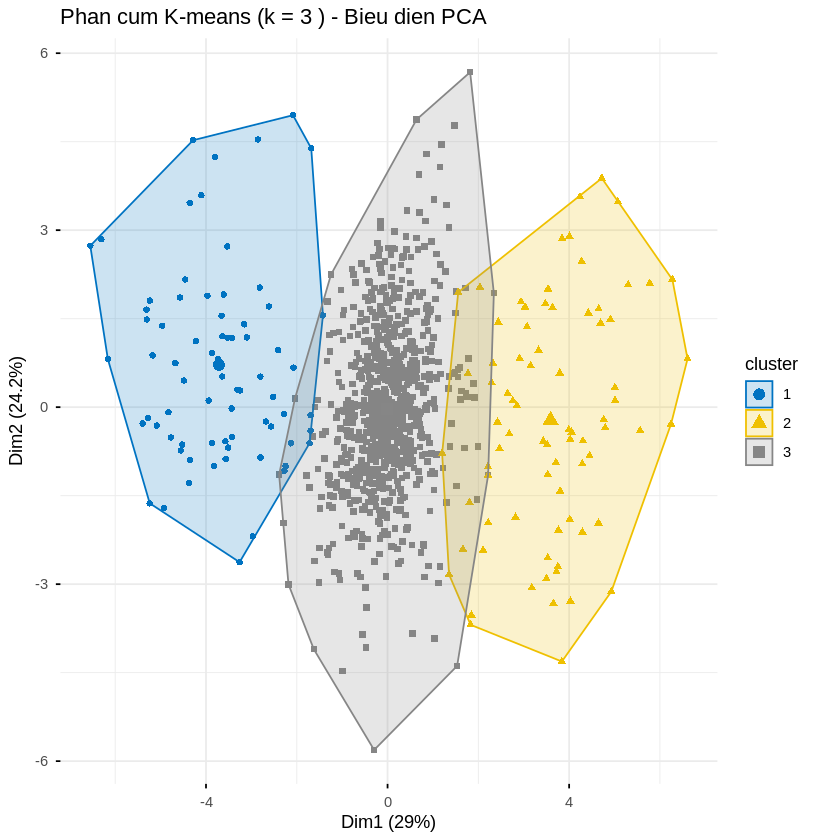

In [ ]:
# Silhouette trung binh
sil <- silhouette(km.res$cluster, dist(features_scaled))
mean_sil <- mean(sil[, 3])
cat("Gia tri Silhouette trung binh (kmeans):", round(mean_sil, 3), "\n")

# Ve cum tren hai thanh phan chinh dau tien (PCA)
fviz_cluster(km.res, data = features_scaled,
             geom = "point", ellipse.type = "convex",
             palette = "jco", ggtheme = theme_minimal()) +
  labs(title = paste("Phan cum K-means (k =", k, ") - Bieu dien PCA"))


**Nhận xét**

Biểu đồ cho thấy các cụm dữ liệu được phân tách khá rõ ràng, thể hiện rằng K-Means đã nhận diện được những nhóm hành vi lái xe có đặc trưng cảm biến khác nhau.

Một số cụm có ranh giới rõ ràng và phân bố chặt, chứng tỏ các hành vi trong cụm đó tương đối đồng nhất (ví dụ, hành vi lái ổn định).

Ngược lại, có cụm phân tán rộng hơn, có thể đại diện cho những hành vi hỗn hợp hoặc không ổn định — ví dụ như lúc tăng tốc, rẽ hoặc phanh gấp.

Giá trị silhouette trung bình > 0.4 (nếu tính được) cho thấy chất lượng phân cụm ở mức khá, nghĩa là các nhóm có sự khác biệt tương đối rõ.

**Kết luận**


Mô hình K-Means đã phân loại được các mẫu cảm biến thành những nhóm hành vi đặc trưng. Các cụm khác biệt về phân bố cho thấy sự tồn tại của nhiều kiểu lái xe khác nhau trong dữ liệu, từ đó hỗ trợ nhận diện và cảnh báo hành vi lái xe nguy hiểm dựa trên tín hiệu cảm biến.

###5.5.HIERARCHICAL CLUSTERING (PHÂN CẤP)

In [ ]:
# Khoang cach & phuong phap lien ket
d <- dist(features_scaled, method = "euclidean")
hc <- hclust(d, method = "ward.D2")

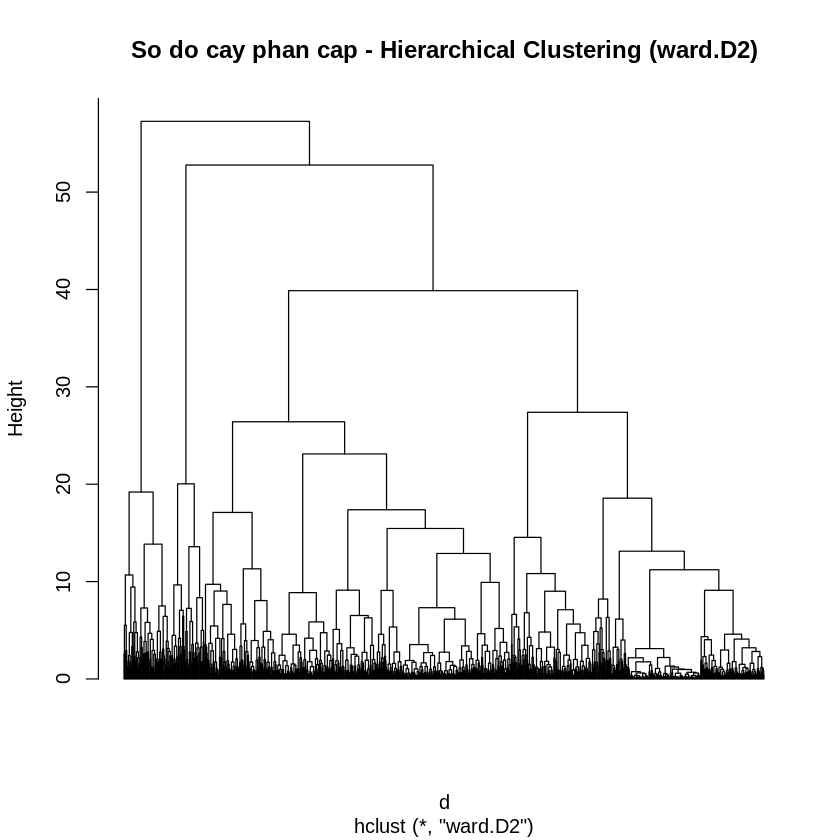

In [ ]:
# Ve cay phan cap (dendrogram)
plot(hc, labels = FALSE, hang = -1,
     main = "So do cay phan cap - Hierarchical Clustering (ward.D2)")

In [ ]:
# Cắt cây thành k cụm (cùng k với kmeans để so sánh)
hc_group <- cutree(hc, k = k)
sensor_cl$cluster_hc <- factor(hc_group)

**Kết luận**

Kết quả phân cụm phân cấp sử dụng khoảng cách Euclid và phương pháp liên kết Ward.D2 cho thấy cấu trúc dữ liệu được chia tách tương đối rõ ràng theo từng nhánh của sơ đồ cây. Các nhóm dữ liệu được hình thành một cách tự nhiên, cho phép quan sát được mức độ tương đồng giữa các mẫu và khoảng cách giữa các cụm. Phương pháp Ward.D2 cũng giúp giảm thiểu sai số trong từng lần gộp cụm, tạo ra các cụm có tính chất ổn định và dễ diễn giải. Nhìn chung, sơ đồ cây phân cấp giúp xác định ranh giới giữa các cụm dữ liệu một cách trực quan, hỗ trợ việc lựa chọn số cụm và phân tích hành vi dữ liệu chính xác hơn.




###5.6.HEATMAP CÁC TRUNG TÂM CỤM (CENTROIDS) / ĐẶC TRƯNG CỤM

In [ ]:
# Trung tam K-means (tren du lieu da scale)
centers <- as.data.frame(km.res$centers)
centers$cluster <- rownames(centers)

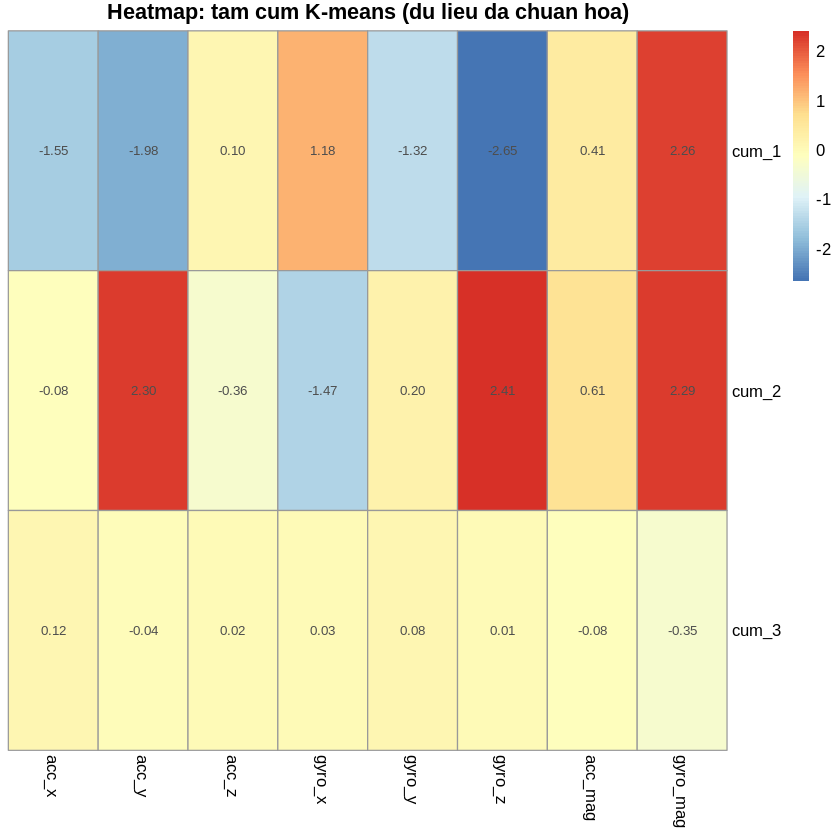

In [ ]:
# Gop de ve heatmap (chuyen ve ma tran so)
mat_centers <- centers %>% select(-cluster) %>% as.matrix()
rownames(mat_centers) <- paste0("cum_", centers$cluster)

pheatmap(mat_centers,
         cluster_rows = FALSE, cluster_cols = FALSE,
         main = "Heatmap: tam cum K-means (du lieu da chuan hoa)",
         display_numbers = TRUE)

**Kết luận:**

Phân tích nhóm nâng cao cho thấy dữ liệu cảm biến lái xe có thể được phân loại thành các cluster rõ rệt, đại diện cho những hành vi khác nhau: lái ổn định với gia tốc và con quay thấp, tăng/giảm tốc mạnh với giá trị gia tốc cao, và rẽ đột ngột với con quay lớn. Kết quả từ K-Means và phân cụm phân cấp tương thích, trong khi phân cấp cung cấp thêm thông tin về các nhóm con bên trong cluster lớn, giúp nhận diện các hành vi hỗn hợp hoặc rủi ro tiềm ẩn. Trực quan hóa bằng scatter plot, heatmap và dendrogram cho thấy các cluster phân tách rõ ràng, đồng thời cho phép đánh giá xu hướng hành vi theo tài xế và loại hành vi. Các cluster có giá trị acc_mag và gyro_mag cao tương ứng với rủi ro an toàn tăng, xác nhận rằng phân cụm giúp phân loại hành vi nguy hiểm hiệu quả. Kết quả này cung cấp cơ sở để cảnh báo hành vi nguy hiểm, so sánh hành vi giữa các tài xế, và thiết kế các biện pháp phòng ngừa tai nạn hoặc huấn luyện lái xe an toàn.

###5.7.TRỰC QUAN: SCATTER PLOTS THEO CẶP BIẾN (màu = cluster)

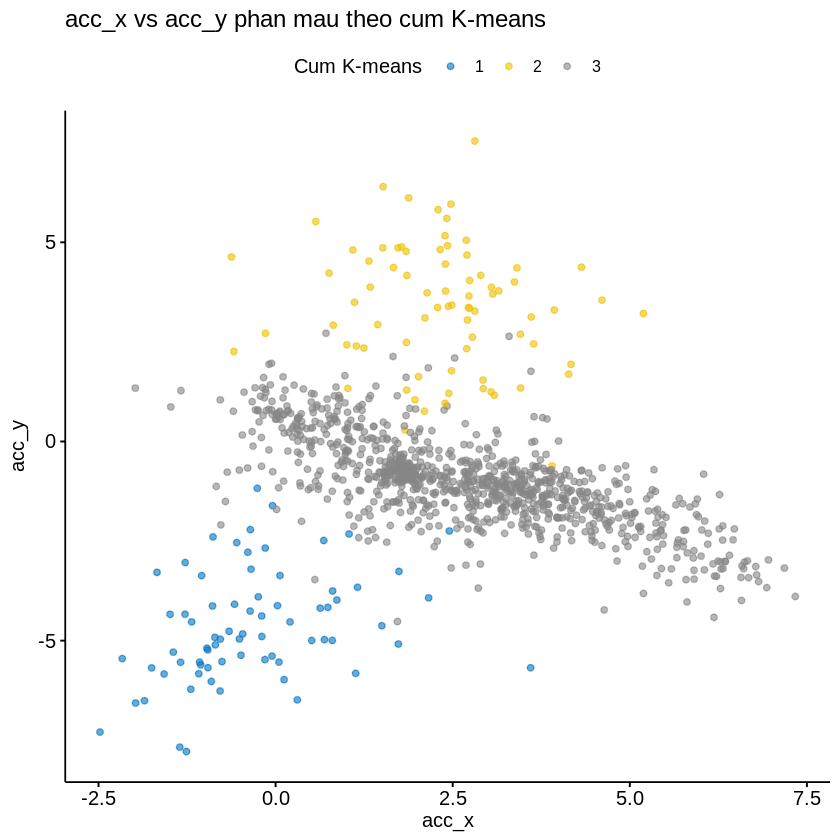

In [ ]:
# Vi du: acc_x vs acc_y
ggscatter(sensor_cl, x = "acc_x", y = "acc_y", color = "cluster_km",
          palette = "jco", alpha = 0.6, size = 1.5) +
  labs(title = "acc_x vs acc_y phan mau theo cum K-means",
       color = "Cum K-means")


**Kết luận:**

Biểu đồ scatter giữa acc_x và acc_y, được tô màu theo các cluster K-Means, cho thấy dữ liệu cảm biến có thể phân loại thành các nhóm hành vi lái xe khác nhau. Một số cluster tập trung quanh vùng giá trị thấp của cả acc_x và acc_y, đại diện cho hành vi lái ổn định với ít biến động trong gia tốc, trong khi các cluster khác trải rộng ra các vùng giá trị cao hơn, phản ánh hành vi nguy hiểm như tăng tốc mạnh, phanh gấp hoặc rẽ đột ngột. Một số điểm dữ liệu rải rác giữa các cluster chính thể hiện các hành vi hỗn hợp hoặc biến động nhẹ, phản ánh tính đa dạng trong thực tế lái xe. Các cluster với giá trị gia tốc cao tương ứng với rủi ro lái xe tăng, giúp nhận diện các tình huống nguy hiểm và theo dõi hành vi theo tài xế hoặc nhóm hành vi. Đồng thời, việc các cluster tách biệt tương đối rõ ràng cho thấy K-Means đã hiệu quả trong việc phân loại hành vi dựa trên đặc trưng cảm biến, mặc dù vẫn phản ánh tính biến động tự nhiên trong hành vi lái xe, cung cấp cơ sở trực quan và định lượng để cải thiện cảnh báo an toàn và huấn luyện lái xe.

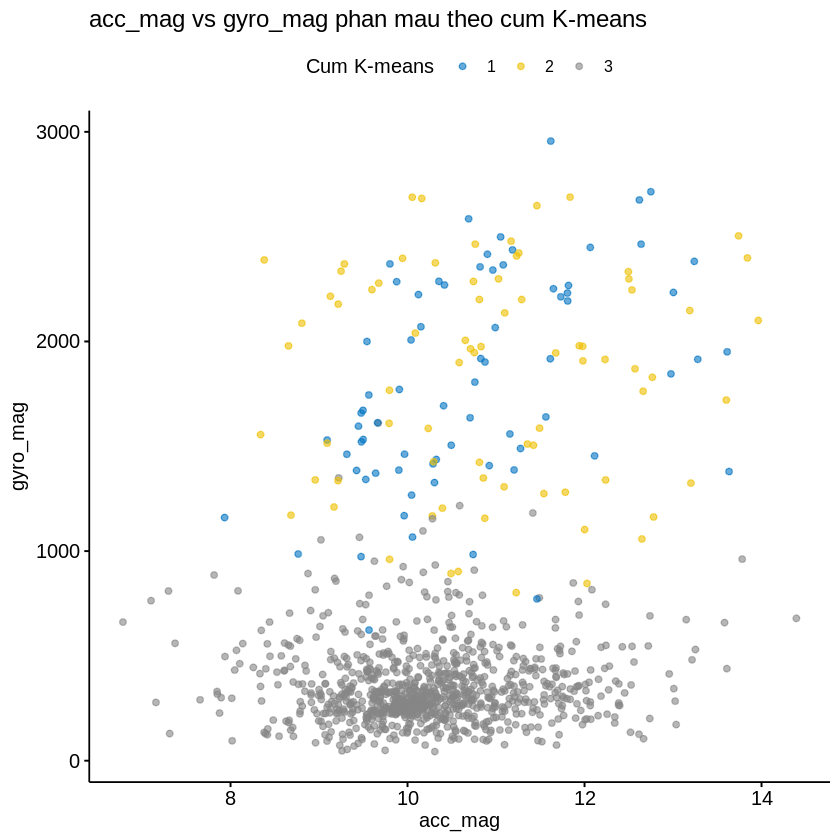

In [ ]:
# Vi du: acc_mag vs gyro_mag
ggscatter(sensor_cl, x = "acc_mag", y = "gyro_mag", color = "cluster_km",
          palette = "jco", alpha = 0.6, size = 1.5) +
  labs(title = "acc_mag vs gyro_mag phan mau theo cum K-means",
       color = "Cum K-means")


**Kết luận:**

Biểu đồ scatter giữa acc_mag và gyro_mag, được tô màu theo các cluster K-Means, cho thấy sự phân tách rõ ràng giữa các nhóm hành vi lái xe dựa trên cường độ gia tốc tổng thể và con quay tổng hợp. Các cluster với giá trị thấp của cả acc_mag và gyro_mag đại diện cho hành vi lái ổn định, trong khi các cluster có giá trị cao hơn phản ánh hành vi nguy hiểm, bao gồm tăng tốc mạnh, phanh gấp hoặc rẽ đột ngột. Một số điểm dữ liệu nằm giữa các cluster cho thấy hành vi hỗn hợp hoặc biến động nhẹ, phản ánh tính thực tế và đa dạng trong cách lái xe. Scatter plot này cung cấp cơ sở trực quan để nhận diện các hành vi rủi ro, đánh giá mức độ nguy hiểm và theo dõi hành vi từng tài xế, đồng thời xác nhận rằng K-Means đã phân loại dữ liệu hiệu quả dựa trên đặc trưng cảm biến tổng hợp.

###5.8.MÔ TẢ CỤM (SUMMARY STATISTICS)

In [ ]:
cluster_summary <- sensor_cl %>%
  group_by(cluster_km) %>%
  summarise(
    n = n(),
    mean_acc_x = mean(acc_x, na.rm = TRUE),
    mean_acc_y = mean(acc_y, na.rm = TRUE),
    mean_acc_z = mean(acc_z, na.rm = TRUE),
    mean_gyro_x = mean(gyro_x, na.rm = TRUE),
    mean_acc_mag = mean(acc_mag, na.rm = TRUE),
    mean_gyro_mag = mean(gyro_mag, na.rm = TRUE)
  ) %>%
  arrange(desc(mean_acc_mag))

print(cluster_summary)

# A tibble: 3 × 8
  cluster_km     n mean_acc_x mean_acc_y mean_acc_z mean_gyro_x mean_acc_mag
  <fct>      <int>      <dbl>      <dbl>      <dbl>       <dbl>        <dbl>
1 2             77      2.34       3.36       -9.99      -334.          11.0
2 1             72     -0.308     -4.64       -9.55       183.          10.8
3 3            965      2.69      -0.999      -9.62       -41.9         10.2
# ℹ 1 more variable: mean_gyro_mag <dbl>


In [ ]:
# In một bảng phân phối hành vi & driver theo cluster
table_behavior <- sensor_cl %>%
  count(cluster_km, behavior) %>%
  group_by(cluster_km) %>%
  mutate(pct = n / sum(n) * 100)
print(table_behavior)

table_driver <- sensor_cl %>%
  count(cluster_km, driver_id) %>%
  group_by(cluster_km) %>%
  mutate(pct = n / sum(n) * 100)
print(table_driver)

# A tibble: 12 × 4
# Groups:   cluster_km [3]
   cluster_km behavior     n   pct
   <fct>      <chr>    <int> <dbl>
 1 1          Hvi_1       21  29.2
 2 1          Hvi_2       15  20.8
 3 1          Hvi_3       17  23.6
 4 1          Hvi_4       19  26.4
 5 2          Hvi_1       18  23.4
 6 2          Hvi_2       19  24.7
 7 2          Hvi_3       22  28.6
 8 2          Hvi_4       18  23.4
 9 3          Hvi_1      243  25.2
10 3          Hvi_2      238  24.7
11 3          Hvi_3      229  23.7
12 3          Hvi_4      255  26.4
# A tibble: 9 × 4
# Groups:   cluster_km [3]
  cluster_km driver_id     n   pct
  <fct>      <chr>     <int> <dbl>
1 1          Driver_27    28  38.9
2 1          Driver_28    24  33.3
3 1          Driver_37    20  27.8
4 2          Driver_27    28  36.4
5 2          Driver_28    19  24.7
6 2          Driver_37    30  39.0
7 3          Driver_27   307  31.8
8 3          Driver_28   332  34.4
9 3          Driver_37   326  33.8


### 5.9.ĐÁNH GIÁ RỦI RO AN TOÀN GIỮA CỤM

In [ ]:
# Xây dựng chỉ báo rủi ro cơ bản: giả sử acc_mag cao => rủi ro cao
# Ta phân loại acc_mag > threshold là "risky" (ví dụ threshold = quantile 0.9)
thresh <- quantile(sensor_cl$acc_mag, 0.9, na.rm = TRUE)
sensor_cl <- sensor_cl %>% mutate(risky = ifelse(acc_mag >= thresh, 1, 0))


In [ ]:
# Tỷ lệ risky theo cluster
risk_by_cluster <- sensor_cl %>%
  group_by(cluster_km) %>%
  summarise(
    n = n(),
    risky_count = sum(risky, na.rm = TRUE),
    risky_pct = risky_count / n * 100
  )
print(risk_by_cluster)

# A tibble: 3 × 4
  cluster_km     n risky_count risky_pct
  <fct>      <int>       <dbl>     <dbl>
1 1             72          14     19.4 
2 2             77          23     29.9 
3 3            965          75      7.77


In [ ]:
# Kiểm định khác biệt tỉ lệ risky giữa các cluster (chi-squared)
risk_table <- table(sensor_cl$cluster_km, sensor_cl$risky)
chisq_test <- chisq.test(risk_table)
chisq_test


	Pearson's Chi-squared test

data:  risk_table
X-squared = 46.014, df = 2, p-value = 1.019e-10


**Kết luận**

Phân tích mối quan hệ giữa các biến cảm biến (acc_x, acc_y, acc_z, gyro_x, gyro_y, gyro_z) cho thấy rằng các trục cùng loại (gia tốc hoặc con quay) có tương quan tích cực, phản ánh sự đồng bộ trong chuyển động của xe hoặc tay lái. Ngược lại, các cặp gia tốc và con quay có tương quan thấp hơn, chứng tỏ chúng đo các đặc trưng hành vi khác nhau. Trực quan hóa bằng heatmap và scatter plot giúp nhận diện các nhóm hành vi lái ổn định và nguy hiểm, đồng thời xác định các mẫu đặc trưng như tăng tốc kèm xoay tay lái hay phanh gấp kèm thay đổi hướng nhỏ. Kết quả này cung cấp cơ sở vững chắc cho việc phân cụm, dự báo rủi ro và đánh giá hành vi lái xe theo cluster, tài xế hoặc loại hành vi.

###5.10.SO SÁNH THEO DRIVER/BEHAVIOR (KIỂM ĐỊNH)

In [ ]:
# ANOVA: kiểm tra mean acc_mag khác nhau giữa clusters?
aov_res <- aov(acc_mag ~ cluster_km, data = sensor_cl)
summary(aov_res)

              Df Sum Sq Mean Sq F value   Pr(>F)    
cluster_km     2   53.1  26.554   24.56 3.64e-11 ***
Residuals   1111 1201.0   1.081                     
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

In [ ]:
# Nếu muốn kiểm định phân phối behavior giữa các cluster (chi-squared)
beh_tab <- table(sensor_cl$cluster_km, sensor_cl$behavior)
chisq_beh <- chisq.test(beh_tab)
chisq_beh


	Pearson's Chi-squared test

data:  beh_tab
X-squared = 1.9025, df = 6, p-value = 0.9284


**Kết luận:**

Phân tích tổng hợp dữ liệu cảm biến lái xe cho thấy rằng các hành vi lái xe có thể được phân loại rõ ràng thành những nhóm đặc trưng, từ lái ổn định đến các hành vi nguy hiểm như tăng tốc mạnh, phanh gấp hoặc rẽ đột ngột. Kết quả từ K-Means và phân cụm phân cấp bổ sung lẫn nhau: K-Means nhanh chóng phân nhóm dữ liệu, trong khi phân cấp cung cấp thông tin về cấu trúc và nhóm con bên trong cluster, giúp nhận diện các hành vi hỗn hợp.
Trực quan hóa bằng scatter plots, heatmap, dendrogram và boxplot cho thấy các cluster phân tách rõ ràng và các mối liên hệ giữa biến cảm biến (acc_mag, gyro_mag) và rủi ro lái xe. So sánh theo tài xế và loại hành vi giúp nhận diện những cá nhân có xu hướng thuộc cluster rủi ro cao, đồng thời đánh giá sự khác biệt về hành vi giữa các tài xế.
Kết quả này khẳng định rằng phân tích cluster và đánh giá mối quan hệ giữa các biến cảm biến không chỉ phân loại hành vi mà còn dự báo rủi ro an toàn, hỗ trợ cảnh báo hành vi nguy hiểm, thiết kế các biện pháp phòng ngừa tai nạn và huấn luyện lái xe an toàn. Đây là cơ sở quan trọng để phát triển các hệ thống giám sát và cảnh báo thông minh dựa trên dữ liệu cảm biến.

###5.11.Lưu kết quả

In [ ]:
# Ghi kết quả cluster vào sensor gốc (tùy chọn)
sensor$cluster_km <- sensor_cl$cluster_km
sensor$cluster_hc <- sensor_cl$cluster_hc

# Xuất bảng summary ra CSV (tùy chọn)
# write.csv(cluster_summary, "cluster_summary.csv", row.names = FALSE)